# Fuffaguru_AVS

## Simulazione di un Fondo Popolare Sovrano (che diventa una holding di controllo)

**Un esercizio di *steelman*: prendiamo la proposta sul serio e vediamo che numeri escono.**

---

### Di cosa parliamo

Il progetto `Fuffaguru_AVS` simula un **Fondo Popolare Sovrano** alimentato da tre fonti fiscali
(recupero dell'evasione, imposta patrimoniale, imposta di successione sulle grandi aziende) con un
obiettivo esplicito: **prendere il controllo del 51 % delle principali partecipate pubbliche
italiane** — e, solo dove conviene, portarle al 100 %.

Il nome è uno sfottò verso `AVS` **Alleanza Verdi Sinistra**, e l'oggetto della simulazione è
l'idea, circolata nel dibattito politico, di un fondo sovrano che «specula in borsa» con soldi
garantiti dalle imprese di Stato. Qui la implementiamo nella versione **più generosa e più
competente possibile**, con obiettivo politico di rinazionalizzare i principali asset strategici
del Paese. Lasciamo che siano i numeri a dire cosa regge e cosa no.

> Il punto del notebook è metodologico: *come si quantifica* una proposta così, e quali sono
> le grandezze che decidono se funziona.

### La differenza rispetto a un «fondo sovrano» normale

Un fondo sovrano investe per rendere. Questo **investe per comandare**, e le due cose non
coincidono quasi mai:

- Comprare il 27 % di ENEL al 35 % di premio **distrugge valore** rispetto a tenere lo stesso
  capitale in BTP. Se l'obiettivo fosse il rendimento, la mossa giusta sarebbe non farla.
- Il denaro non speso non sta in un portafoglio diversificato: sta in **BTP**, in attesa di
  finanziare l'operazione successiva.
- Il patrimonio **scende** ogni volta che si compra, perché il premio di controllo è una perdita
  immediata e non un attivo.

Il notebook modella esattamente questo. Se il risultato sembra deludente, è perché la proposta,
letta seriamente, è meno generosa di come viene raccontata.

### Cosa NON è

- **Non è una previsione.** È un modello didattico, con parametri dichiaratamente rozzi.
- **Non è una consulenza finanziaria né una stima ufficiale di gettito.** I numeri fiscali sono
  stime di ordine di grandezza, ognuna etichettata con la propria fonte e con un `TODO: raffinare`.
- **Non tiene conto** di tutta la normativa UE (regole di bilancio, aiuti di Stato, concorrenza),
  che nella realtà morderebbe parecchio. Se ne parla nella §15, dove si dice anche cosa il modello
  *non* può vedere.

### Mappa del notebook

| § | Contenuto | Cosa impari |
|---|---|---|
| 1 | Setup e **pannello di controllo** | dove si girano le manopole |
| 2 | Architettura, glossario, convenzioni | come è fatto il modello, cosa significa ogni simbolo |
| 3 | Le tre fonti: **RCF, IPP, ISA** | da dove arrivano i soldi, con i conti in chiaro |
| 4 | Dinamica delle entrate | shock ±20 %, regimi politici, crollo a zero |
| 5 | **L'universo di acquisto** | chi si compra, quanto costa, chi paga il premio |
| 6 | La riserva liquida: curva, scadenze, duration | perché il tetto a 10 anni è l'unica protezione |
| 7 | **La macchina della holding** | lo stato, le due regole, il percorso anno per anno |
| 8 | **MCMC** (`emcee`) | come si costruiscono gli intervalli di confidenza |
| 9 | Risultati a 10/20/30/50 anni | ventagli, composizione del patrimonio, valori reali |
| 10 | **Il calendario del controllo** | chi si compra quando, e il conto di ILVA |
| 11 | **Dividendo sociale** | quanto vale, a chi va, e cosa costa in termini di obiettivi |
| 12 | Sensibilità | quale manopola sposta davvero l'ago |
| 13 | Scenari a confronto | base, ottimista, abolizione 2031, shock spread, passivo |
| 14 | Limiti e onestà contabile | dove il modello sarebbe tentato di barare |
| 15 | Il punto, e come si gioca | conclusioni e istruzioni per l'uso |

### Come si legge

Ogni sezione ha una parte discorsiva (quella che stai leggendo) e una parte di codice.
Le **manopole** stanno tutte in un unico blocco nella §1: cambia un numero, riesegui, guarda
i grafici. Nessun valore è cablato dentro le funzioni.

**Unità di misura.** Tutto in **miliardi di euro (mld €)**, salvo dove indicato.
I risultati principali sono riportati in **euro reali 2026** (potere d'acquisto di oggi);
il nominale è sempre disponibile come secondo pannello, perché a 30 anni la differenza è enorme
e mostrare solo il nominale è il modo più semplice di mentire in buona fede.


In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# §1 — Setup
# ══════════════════════════════════════════════════════════════════════════════
#
#  Dipendenze minime : numpy, pandas, matplotlib, scipy
#  Dipendenza opzionale : emcee  (se manca, si usa un sampler MH interno)
#
#  Per reinstallare tutto:  pip install -r ../requirements.txt
# ──────────────────────────────────────────────────────────────────────────────

import json
import math
import time
import warnings
from dataclasses import dataclass, field, fields, asdict, is_dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

# `display` esiste in Jupyter; fuori da Jupyter (per i test da riga di comando)
# definiamo un fallback che stampa a schermo.
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

warnings.filterwarnings("ignore", category=FutureWarning)

# Dentro Jupyter si usa il backend inline, così le figure restano incorporate nel
# notebook anche quando lo si esegue con MPLBACKEND=Agg (nbconvert). Fuori da
# Jupyter (script lanciato da riga di comando) questa riga non fa nulla.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

# --- dipendenza opzionale ----------------------------------------------------
try:
    import emcee
    HAS_EMCEE = True
    EMCEE_VERSION = emcee.__version__
except Exception:
    emcee = None
    HAS_EMCEE = False
    EMCEE_VERSION = None

# --- percorsi ---------------------------------------------------------------
# Il notebook funziona sia lanciato da notebooks/ sia dalla root del progetto.
HERE = Path.cwd()
PROJECT_ROOT = HERE.parent if HERE.name == "notebooks" else HERE
DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20261116

# --- stile grafico ----------------------------------------------------------
C = {
    "ink":      "#1b1b1b",
    "grid":     "#d8d8d8",
    "rcf":      "#2f6f9f",   # blu   — riscossione
    "ipp":      "#b8860b",   # oro   — patrimoniale
    "isa":      "#8b3a62",   # porpora — successioni
    "tot":      "#111111",
    "equity":   "#2a7f4f",
    "btp":      "#a8322d",
    "band1":    "#cfe3f2",
    "band2":    "#a8cae6",
    "band3":    "#6fa3ce",
    "accent":   "#d1495b",
    "grey":     "#7a7a7a",
}

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10.5, 4.6),
    "savefig.dpi": 150,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": C["grid"],
    "grid.linewidth": 0.6,
    "grid.alpha": 0.75,
    "legend.frameon": False,
    "legend.fontsize": 9.5,
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "figure.autolayout": False,
})

plt.rcParams["axes.prop_cycle"] = mpl.cycler(
    color=[C["rcf"], C["ipp"], C["isa"], C["equity"], C["btp"], C["grey"]]
)


def savefig(fig, name: str, verbose: bool = False):
    """Salva una figura in figures/ (utile per riusarla in una presentazione)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if verbose:
        print(f"  → {path}")


def mld(x, _=None):
    """Formattatore: 1234.5 → '1.234'."""
    return f"{x:,.0f}".replace(",", ".")


def pct(x, _=None):
    """Formattatore: 0.073 → '7,3 %'."""
    return f"{x * 100:.1f}".replace(".", ",") + " %"


MLD = FuncFormatter(mld)
PCT = FuncFormatter(pct)

# --- utility numeriche ------------------------------------------------------

def _arr(x, n):
    """Trasforma scalare o vettore in un array di forma (n,). Serve a far
    convivere parametri fissi e parametri che variano da percorso a percorso."""
    a = np.asarray(x, dtype=float)
    if a.ndim == 0:
        return np.full(n, float(a))
    return np.broadcast_to(a, (n,)).astype(float)


def _sc(x):
    """Estrae un float da uno scalare o da un array di un solo elemento."""
    a = np.asarray(x, dtype=float).ravel()
    if a.size != 1:
        raise ValueError(f"atteso scalare, ricevuto array di forma {np.shape(x)}")
    return float(a[0])


def qtab(x, name="F"):
    """Tabella dei quantili, la forma in cui leggeremo tutti i risultati."""
    qs = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    d = {f"P{int(q * 100):02d}": np.quantile(x, q, axis=0) for q in qs}
    d["media"] = np.mean(x, axis=0)
    return pd.DataFrame(d, index=[f"{name}{t}" for t in range(np.shape(x)[1])])


print(f"numpy {np.__version__} · pandas {pd.__version__} · matplotlib {mpl.__version__}")
print(f"emcee: {'disponibile v' + str(EMCEE_VERSION) if HAS_EMCEE else 'NON disponibile → uso il sampler interno'}")
print(f"root progetto: {PROJECT_ROOT}")


numpy 2.5.4 · pandas 3.1.0 · matplotlib 3.11.2
emcee: disponibile v3.1.6
root progetto: /home/massimiliano-romanello/Documenti/Fuffaguru_AVS


## §2 — Architettura del modello, glossario, convenzioni

### 2.1 Il disegno in una riga

```
   FONTI FISCALI            MERCATI                    HOLDING
   ─────────────            ───────                    ───────
   RCF ─┐
   IPP ─┼─→ I_t ─────────→  y_t(τ) curva BTP  ──────→  B_{t+1}   riserva liquida
   ISA ─┘                   r_t^i per titolo            POS_{t+1} quote di controllo
      ▲                        ▲                          │
      │                        │                          └─→ acquisitions (1/anno)
   regime politico        inflazione, PIL                     premio perso subito
                                                               dividendo sociale D_t
```

Quattro blocchi che si parlano poco (ed è voluto: rende il modello leggibile e ogni ipotesi
isolabile).

1. **Blocco fiscale** → produce il flusso annuo `I_t = RCF_t + IPP_t + ISA_t` in mld €.
2. **Blocco mercati** → produce la curva dei tassi per scadenza e il rendimento di ogni titolo.
3. **Blocco holding** → lo stato (`B_t`, `POS_t`, `ST_t`), le due regole di acquisto, i rendimenti.
4. **Blocco spesa** → la regola del dividendo sociale, che è l'unica cosa che esce dal patrimonio.

### 2.2 Glossario

| Simbolo | Nome | Unità | Significato |
|---|---|---|---|
| `F_t` | patrimonio netto (NAV) | mld € | `B_t + Σ POS_t[i]`, il numero che fa scena |
| `B_t` | riserva liquida | mld € | cassa investita in BTP, in attesa di essere spesa |
| `POS_t[i]` | quota detenuta in *i* | mld € | valore di **mercato** della partecipazione |
| `ST_t[i]` | frazione detenuta in *i* | 0–1 | la quota, non il valore |
| `F₀` | **dote iniziale** | mld € | primo anno di incassi: `RCF₀ + IPP₀ + ISA₀` |
| `I_t` | afflusso annuo | mld € | nuovo gettito accantonato nell'anno `t` |
| `RCF` | **Riscossione Crediti Fiscali** | mld € | cassa incassata dal magazzino delle cartelle non riscosse |
| `IPP` | **Imposta Patrimoniale Progressiva** | mld € | 0,1 % sui patrimoni netti sopra 500 k€ |
| `ISA` | **Imposta Successoria sulle Aziende** | mld € | revoca dell'esenzione sui grandi passaggi ereditari d'impresa |
| `y_t(τ)` | tasso BTP a scadenza τ | % annuo | curva a due fattori (livello + pendenza) |
| `D_τ` | duration della scadenza τ | anni | `0,75 τ`: la sensibilità al tasso |
| `φ_t` | quota in BTP della riserva | 0–1 | nelle politiche «constant» e «tatticale» |
| `D_t` | dividendo sociale | mld € | quanto viene distribuito ai cittadini nell'anno `t` |
| `g_t` | crescita del PIL nominale | % annuo | trascina le entrate fiscali |
| `π_t` | inflazione | % annuo | serve a distinguere reale e nominale |

### 2.3 Perché questi nomi

- **`RCF` — Riscossione Crediti Fiscali.** Qui si modella la **cassa effettivamente incassata** dal magazzino dei crediti già
  accertati e non riscossi (cartelle, ruoli, avvisi). È la grandezza che entra in bilancio, ed è
  l'unica che si può accantonare in un fondo. La sigla dice anche il parametro chiave: il *tasso
  di realizzo* sul magazzino.
- **`IPP` — Imposta Patrimoniale Progressiva.** «Progressiva» perché la soglia a 500 k€ la rende
  di fatto progressiva (0 sotto soglia, 0,1 % sopra). Evita l'ambiguità con «patrimoniale secca»
  e ricorda che la progressività sta nella soglia, non nell'aliquota.
- **`ISA` — Imposta Successoria sulle Aziende.** Deliberatamente ristretta: non è una patrimoniale
  sulle successioni in generale, è l'imposta sui **trasferimenti d'impresa** di dimensione
  rilevante, cioè esattamente il perimetro della sentenza 120/2020.

### 2.4 Convenzioni (le tre che contano)

**(a) Reale vs nominale.** Tutti i rendimenti azionari e i tassi BTP sono **nominali** (è così che
li si osserva). L'inflazione è simulata anno per anno e il risultato è riportato in **€ reali 2026**
come misura principale. Un fondo che passa da 17 a ~940 mld in 30 anni *nominali*, con inflazione
al 2 %, vale in realtà ~514 mld di oggi: quasi la metà. Mostrare solo il nominale è il trucco
retorico più comune, e non lo usiamo.

**(b) Il premio di controllo è una perdita, non un attivo.** Quando il fondo paga il 35 % sopra il
prezzo di mercato, quella differenza esce e non torna: nel modello l'attivo entra in bilancio a
**valore di mercato**, quindi il NAV scende nell'istante dell'acquisto. È la convenzione contabile
più onesta e la meno usata nel dibattito.

**(c) Consolidamento.** Il fondo è **pubblico**. Comprare BTP da residenti non riduce il debito
pubblico: cambia il creditore. Comprare azioni ENI da privati trasferisce ricchezza ai privati.
I dividendi delle quote già pubbliche restano al bilancio dello Stato e non sono entrate nuove.
Queste cose sono vere e scomode, e le trattiamo esplicitamente nella §7.3 e nella §14 invece di
seppellirle. È il cuore dell'analisi: **il modello distingue il patrimonio netto della holding
(`F_t`, la cifra che fa scena) da ciò che il settore pubblico ci guadagna davvero**.


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# §3 — Pannello di controllo: TUTTE le manopole stanno qui
# ══════════════════════════════════════════════════════════════════════════════
#
#  Cambia un numero, riesegui da qui in giù: tutto il resto si aggiorna.
#  Ogni campo è documentato nella tabella generata in fondo a questa cella.
#  I commenti "# FONTE:" dicono da dove viene la stima; "# TODO:" cosa rifinire.
# ──────────────────────────────────────────────────────────────────────────────


@dataclass
class FontiConf:
    """Le tre fonti di gettito. Unità: mld €, salvo indicazione."""

    # ── RCF · Riscossione Crediti Fiscali ────────────────────────────────────
    rcf_magazzino_mld: float = 1200.0
    # FONTE: magazzino residuo di Agenzia delle Entrate-Riscossione (cartelle e
    # ruoli non riscossi), valori nominali lordi, ordine di grandezza 1.100–1.300.
    rcf_tasso_realizzo_annuo: float = 0.0095
    # FONTE: incasso annuo AdER ≈ 10–12 mld su magazzino ≈ 1.200 → ~0,9 %/anno.
    rcf_costo_riscossione: float = 0.12
    # FONTE: costi di gestione della riscossione coattiva ≈ 10-15 % dell'incassato.
    rcf_shock_efficienza: float = 0.20
    # MANOPOLA CHIAVE: shock moltiplicativo annuo uniforme in ±20 % sull'efficienza
    # del fisco (organico, digitalizzazione, contenzioso). Richiesto in specifica.
    rcf_elasticita_pil: float = 1.0
    rcf_moltiplicatore_regime_avverso: float = 0.60

    # ── IPP · Imposta Patrimoniale Progressiva (0,1 % sopra 500 k€) ──────────
    ipp_soglia_euro: float = 500_000.0
    ipp_aliquota: float = 0.001
    ipp_ricchezza_netta_mld: float = 10800.0
    # FONTE: ricchezza netta delle famiglie italiane ≈ 10.500–11.000 mld
    # (immobili ~6.100, attività finanziarie ~5.200, passività ~-650), BdI 2024.
    ipp_quota_oltre_soglia: float = 0.68
    # FONTE: quota di ricchezza in mano a famiglie con patrimonio > 500 k€,
    # stimata dalla distribuzione della ricchezza (top ~22 % delle famiglie
    # detiene ~65-70 % della ricchezza). Ordine di grandezza.
    ipp_compliance: float = 0.85
    # FONTE: quota effettivamente incassabile (esterovestizione, trust, estimi
    # catastali non aggiornati, esenzioni, contenzioso). Stima prudente.
    ipp_costi_gestione_mld: float = 0.40
    ipp_elasticita_pil: float = 1.2
    # I patrimoni crescono più del PIL (effetto mercato + immobili).
    ipp_moltiplicatore_regime_avverso: float = 0.0
    # Se una maggioranza avversa vince, la patrimoniale può essere abolita del tutto.

    # ── ISA · Imposta Successoria sulle Aziende ──────────────────────────────
    isa_n_imprese_sopra_soglia: float = 4000.0
    # FONTE: numero di imprese italiane con valore economico > 50 mln €.
    isa_anni_ricambio: float = 35.0
    # FONTE: turnover generazionale della proprietà ≈ 30–40 anni.
    isa_valore_medio_partecipazione_mld: float = 0.22
    # FONTE: valore medio della quota trasferita (≈ 220 mln €): partecipazioni
    # di controllo in imprese sopra soglia, spesso non totalitarie.
    isa_aliquota_media: float = 0.06
    # FONTE: aliquota legale 4 % (coniuge/figli) + progressività sopra 500 mln
    # → aliquota media effettiva ≈ 6 %. Cfr. sentenza C. Cost. 120/2020.
    isa_soglia_dimensione_mln: float = 50.0
    isa_lumpiness: float = 0.45
    # Le grandi successioni sono irregolari (poche, enormi): deviazione standard
    # della componente casuale sul gettito annuo. Modello Poisson-composto.
    isa_elasticita_pil: float = 1.0
    isa_moltiplicatore_regime_avverso: float = 0.0


@dataclass
class MacroConf:
    gdp_nominale_crescita: float = 0.025
    # FONTE: PIL nominale italiano, medio lungo periodo ≈ 2–2,5 %.
    gdp_sigma: float = 0.012
    gdp_floor: float = -0.05
    gdp_cap: float = 0.07
    inflazione_media: float = 0.020
    inflazione_sigma: float = 0.010
    inflazione_floor: float = -0.01
    inflazione_cap: float = 0.12


@dataclass
class PoliticaConf:
    p_fav_a_avv: float = 0.08
    # Probabilità annua che un governo favorevole al fondo cada e sia sostituito
    # da una maggioranza che abolisce patrimoniale e/o successoria.
    p_avv_a_fav: float = 0.40
    # Probabilità annua che la misura venga ripristinata (ciclo politico).
    regime_iniziale: int = 0
    # 0 = favorevole, 1 = avversa.
    shock_entrate_sigma: float = 0.10
    # Rumore residuo sul totale delle entrate (congiuntura, una tantum).
    anno_abolizione: int = -1
    # -1 = nessuna abolizione forzata. Altrimenti anno in cui, con certezza,
    # scatta il regime avverso e le fonti B e C vanno a zero per sempre.
    # Serve per lo scenario "abolizione nel 2031".


@dataclass
class MercatiConf:
    alpha_mode: str = "t_student"
    # "t_student" → α ~ t di Student attorno a un drift prudente (default)
    # "uniform"   → α reale = drift + semilarghezza·U(−1,+1)   [specifica originale]
    drift_atteso: float = 0.055
    # MANOPOLA CHIAVE: rendimento NOMINALE atteso del portafoglio. Il prior è
    # centrato sul μ del paniere (≈7,2 %) RIDOTTO DEL 20 % (haircut prudenziale).
    sigma_alpha: float = 0.16
    t_nu: float = 5.0
    uniform_drift_reale: float = 0.010
    uniform_semilarghezza_reale: float = 0.030
    fee_gestione: float = 0.0015
    slippage_su_afflussi: float = 0.003

    # ── la riserva liquida: dove parcheggia la cassa non ancora spesa ────────
    btp_politica: str = "max_carry"
    # "max_carry"   → tutta la cassa in BTP, sulla scadenza che rende di più
    #                 entro il tetto di duration (default 10 anni)
    # "tatticale"   → ripartizione BTP/equity decisa anno per anno dal premio
    #                 atteso (Merton miope, nessun look-ahead)
    # "constant"    → quota fissa btp_quota in BTP, il resto nel paniere passivo
    # "equity_only" → φ = 0, per confronto
    btp_quota: float = 0.30
    # Usata solo da "constant" (e dallo scenario passivo di confronto).
    btp_duration_max: float = 10.0
    # MANOPOLA CHIAVE: scadenza massima acquistabile. È l'unica protezione
    # contro il rischio di prezzo: con 30 anni una salita dei tassi dell'1 %
    # costa il 22 % del capitale investito.
    btp_yield_lungo: float = 0.035
    # FONTE: BTP 10 anni, media di lungo periodo ≈ 3,5 % nominale.
    btp_ou_kappa: float = 0.25
    btp_ou_sigma: float = 0.011
    btp_slope_iniziale: float = 0.010
    # Pendenza iniziale della curva: 30 anni ≈ 10 anni + 1,0 % (ripidità tipica).
    btp_slope_kappa: float = 0.35
    btp_slope_sigma: float = 0.005
    btp_convessita: float = 0.0
    # Moltiplicatore della convessità: C(τ) = btp_convessita · τ².
    # Default 0 (spenta) e non è pigrizia: con la volatilità dei tassi usata qui
    # (σ_y = 1,1 %/anno) il termine ½·τ²·(Δy)² regalerebbe ai trentennali un
    # +5 %/anno che nella realtà non esiste, perché presuppone che i tassi si
    # muovano ogni anno di un punto. Portalo a 1 per vedere l'artefatto.
    tatticale_avversione: float = 3.0
    # Avversione al rischio della regola tatticale (Merton: w* = premio/(γσ²)).
    spread_shock_anno: int = -1
    # -1 = nessuno. Altrimenti anno in cui scatta uno shock di spread (stile 2011).
    spread_shock_bp: float = 300.0
    quota_non_residenti: float = 0.27
    # FONTE: quota del debito pubblico italiano detenuta da non residenti ≈ 25-28 %.
    # Serve per l'onestà contabile: solo questa quota genera risparmio reale.


@dataclass
class BenchmarkConf:
    """Parametri dell'operazione di controllo societario (la parte «holding»)."""

    premio_controllo: float = 0.35
    # Per portare una quotata sotto controllo serve rastrellare sul mercato:
    # premio medio di takeover ≈ 30-40 % sul prezzo corrente.
    impatto_mercato: float = 0.02
    quota_controllo: float = 0.51
    # Quota che dà il controllo: il sistema pubblico (MEF+CDP+fondo) la raggiunge
    # comprando SOLO il pezzo mancante.
    riserva_minima: float = 0.50
    # Regola prudenziale: un acquisto è "permesso" solo se lascia almeno metà
    # della dotazione libera. Serve a non far risultare tutto comprabile il
    # primo giorno: un fondo che spende il 30 % del NAV per Snam non è un fondo.
    # Portala a 1.01 per disattivare le acquisizioni (scenario passivo).
    soglia_residuo: float = 0.02
    # Fase 2 (100 %): si compra il residuo solo se il rendimento atteso della
    # società supera il BTP di almeno 2 punti. Sotto quella soglia il capitale
    # resta in obbligazioni.
    max_acquisti_anno: int = 1
    # Un'operazione per anno: nella realtà ogni nazionalizzazione è un decreto,
    # un'autorizzazione e un'annata di polemiche.


@dataclass
class SpesaConf:
    regola: str = "eccesso_su_baseline"
    # "eccesso_su_baseline" → distribuisce una quota del surplus rispetto alla
    #                          traiettoria attesa (è la richiesta della specifica)
    # "quota_nav"            → distribuisce una quota fissa del patrimonio
    # "nessuna"              → il fondo capitalizza tutto
    payout_quota: float = 0.30
    # Quota del surplus distribuita come dividendo sociale.
    payout_max_nav: float = 0.03
    # Tetto annuo: mai più del 3 % del patrimonio (protegge il fondo).
    # Il 3 % è lo standard dei fondi sovrani veri: sopra quella soglia il
    # patrimonio reale inizia a erodersi.
    anno_inizio: int = 5
    # Niente dividendi nei primi anni: prima si costruisce la dote.
    quota_nav_fissa: float = 0.02
    sconto_baseline_rendimento: float = 0.015
    # Il "piano" rispetto al quale si misura il surplus è PRUDENTE: rendimento
    # atteso ridotto di 1,5 punti percentuali. Serve perché la MEDIANA di un
    # processo composto cresce meno della MEDIA (disuguaglianza di Jensen):
    # con σ ≈ 16 % il divario è ~1,3 %/anno. Senza questo sconto, "meglio del
    # previsto" coinciderebbe con "meglio della mediana": una soglia che metà
    # dei mondi non supera mai, e il dividendo sociale sarebbe zero per sempre.
    sconto_baseline_crescita: float = 0.0025
    popolazione: float = 58_900_000.0
    # Residenti, per il calcolo del dividendo pro capite.


@dataclass
class SimConf:
    anni: int = 50
    n_paths: int = 12_000
    n_paths_sens: int = 2_500
    n_draws_posterior: int = 600
    seed: int = SEED


@dataclass
class MCMCConf:
    n_walkers: int = 24
    n_steps: int = 3600
    n_burn: int = 500
    thin: int = 2
    mu_prior_mu: float = 0.055
    mu_prior_sd: float = 0.020
    sigma_prior_scale: float = 0.18
    y_prior_lo: float = 0.005
    y_prior_hi: float = 0.090
    infl_prior_mu: float = 0.020
    infl_prior_sd: float = 0.010
    t_nu_lik: float = 5.0


@dataclass
class Config:
    fonti: FontiConf = field(default_factory=FontiConf)
    macro: MacroConf = field(default_factory=MacroConf)
    politica: PoliticaConf = field(default_factory=PoliticaConf)
    mercati: MercatiConf = field(default_factory=MercatiConf)
    benchmark: BenchmarkConf = field(default_factory=BenchmarkConf)
    spesa: SpesaConf = field(default_factory=SpesaConf)
    sim: SimConf = field(default_factory=SimConf)
    mcmc: MCMCConf = field(default_factory=MCMCConf)


CFG = Config()

# ── Documentazione dei parametri (resta sincronizzata col codice) ────────────
NOTE = {
    "fonti.rcf_magazzino_mld": "Magazzino residuo AdER: cartelle/ruoli non riscossi (1.100–1.300)",
    "fonti.rcf_tasso_realizzo_annuo": "Incasso annuo / magazzino: ~0,9 %/anno",
    "fonti.rcf_costo_riscossione": "Costi di gestione della riscossione coattiva",
    "fonti.rcf_shock_efficienza": "Shock annuo ±20 % sull'efficienza del fisco (specifica)",
    "fonti.rcf_elasticita_pil": "Elasticità delle entrate alla crescita del PIL",
    "fonti.rcf_moltiplicatore_regime_avverso": "Riduzione se il governo è ostile",
    "fonti.ipp_soglia_euro": "Soglia di esenzione: 500 k€ di patrimonio netto",
    "fonti.ipp_aliquota": "Aliquota: 0,1 % sulla parte eccedente",
    "fonti.ipp_ricchezza_netta_mld": "Ricchezza netta famiglie italiane (BdI, ~10.800 mld)",
    "fonti.ipp_quota_oltre_soglia": "Quota di ricchezza sopra la soglia (~68 %)",
    "fonti.ipp_compliance": "Quota effettivamente incassabile (erosione, elusione, costi)",
    "fonti.ipp_costi_gestione_mld": "Costi amministrativi annui",
    "fonti.ipp_elasticita_pil": "I patrimoni crescono più del PIL",
    "fonti.ipp_moltiplicatore_regime_avverso": "0 = abolita se vince una maggioranza ostile",
    "fonti.isa_n_imprese_sopra_soglia": "Imprese italiane con valore > 50 mln €",
    "fonti.isa_anni_ricambio": "Turnover generazionale della proprietà",
    "fonti.isa_valore_medio_partecipazione_mld": "Valore medio della quota trasferita (220 mln €)",
    "fonti.isa_aliquota_media": "Aliquota media effettiva (4 % + progressività)",
    "fonti.isa_soglia_dimensione_mln": "Soglia dimensionale dell'impresa (mln €)",
    "fonti.isa_lumpiness": "Irregolarità: poche successioni enormi (Poisson-composto)",
    "fonti.isa_elasticita_pil": "Elasticità al PIL",
    "fonti.isa_moltiplicatore_regime_avverso": "0 = abolita se vince una maggioranza ostile",
    "macro.gdp_nominale_crescita": "Crescita del PIL nominale (media di lungo periodo)",
    "macro.gdp_sigma": "Volatilità della crescita",
    "macro.inflazione_media": "Inflazione media attesa",
    "macro.inflazione_sigma": "Volatilità dell'inflazione",
    "politica.p_fav_a_avv": "P(governo favorevole → avverso) per anno",
    "politica.p_avv_a_fav": "P(governo avverso → favorevole) per anno",
    "politica.regime_iniziale": "0 = si parte con una maggioranza favorevole",
    "politica.shock_entrate_sigma": "Rumore residuo sulle entrate totali",
    "mercati.alpha_mode": "t_student (default) oppure uniform (±3 % reale)",
    "mercati.drift_atteso": "Rendimento nominale atteso del portafoglio (prior MCMC)",
    "mercati.sigma_alpha": "Volatilità del portafoglio",
    "mercati.t_nu": "Gradi di libertà della t di Student (code grasse)",
    "mercati.uniform_drift_reale": "Drift reale nella modalità 'uniform'",
    "mercati.uniform_semilarghezza_reale": "Semilarghezza ±3 % reale (specifica originale)",
    "mercati.fee_gestione": "Costo di gestione annuo",
    "mercati.slippage_su_afflussi": "Costo di transazione sull'investimento degli afflussi",
    "mercati.btp_politica": "max_carry | tatticale | constant | equity_only",
    "mercati.btp_quota": "Quota in BTP (solo politiche 'constant' e scenario passivo)",
    "mercati.btp_duration_max": "Scadenza massima acquistabile (anni) — tetto al rischio di prezzo",
    "mercati.btp_yield_lungo": "BTP 10 anni: tasso di lungo periodo (media di ritorno)",
    "mercati.btp_ou_kappa": "Velocità di mean reversion del livello dei tassi",
    "mercati.btp_ou_sigma": "Volatilità annua del livello dei tassi",
    "mercati.btp_slope_iniziale": "Pendenza iniziale della curva (30 anni − 10 anni)",
    "mercati.btp_slope_kappa": "Velocità di mean reversion della pendenza",
    "mercati.btp_slope_sigma": "Volatilità annua della pendenza",
    "mercati.btp_convessita": "Convessità: C(τ) = moltiplicatore · τ²",
    "mercati.tatticale_avversione": "Avversione al rischio della regola tatticale (γ)",
    "mercati.spread_shock_anno": "Anno dello shock di spread (-1 = nessuno)",
    "mercati.spread_shock_bp": "Entità dello shock in punti base",
    "mercati.quota_non_residenti": "Quota del debito detenuta da non residenti (~27 %)",
    "benchmark.premio_controllo": "Premio di controllo pagato ai privati",
    "benchmark.impatto_mercato": "Costo di impatto sul mercato",
    "benchmark.quota_controllo": "Quota necessaria per il controllo (51 %)",
    "benchmark.riserva_minima": "Cassa libera minima dopo un acquisto (% del NAV)",
    "benchmark.soglia_residuo": "Premio minimo vs BTP per comprare il residuo (fase 2)",
    "benchmark.max_acquisti_anno": "Quante operazioni al massimo in un anno",
    "spesa.regola": "Come si calcola il dividendo sociale",
    "spesa.payout_quota": "Quota del surplus distribuita",
    "spesa.payout_max_nav": "Tetto annuo in % del patrimonio",
    "spesa.anno_inizio": "Primo anno in cui si può distribuire",
    "spesa.popolazione": "Residenti (per il dividendo pro capite)",
    "sim.anni": "Orizzonte di simulazione",
    "sim.n_paths": "Numero di traiettorie Monte Carlo",
    "sim.n_draws_posterior": "Numero di estrazioni dal posterior",
    "mcmc.n_walkers": "Numero di walker emcee",
    "mcmc.n_steps": "Passi per walker",
    "mcmc.n_burn": "Burn-in",
    "mcmc.mu_prior_mu": "Prior: rendimento atteso del paniere",
    "mcmc.mu_prior_sd": "Prior: incertezza sul rendimento atteso",
    "mcmc.sigma_prior_scale": "Prior: scala della volatilità (HalfNormal)",
    "mcmc.y_prior_lo": "Prior: minimo del tasso BTP di lungo periodo",
    "mcmc.y_prior_hi": "Prior: massimo del tasso BTP di lungo periodo",
    "mcmc.infl_prior_mu": "Prior: inflazione media",
    "mcmc.infl_prior_sd": "Prior: incertezza sull'inflazione",
}


def flat(cfg):
    """Appiattisce la configurazione in un dizionario 'sezione.parametro' → valore.
    È il formato che usa il simulatore: così anche l'MCMC può sovrascrivere
    singoli parametri per singolo percorso."""
    out = {}
    for f in fields(cfg):
        v = getattr(cfg, f.name)
        if is_dataclass(v):
            for g in fields(v):
                out[f"{f.name}.{g.name}"] = getattr(v, g.name)
        else:
            out[f.name] = v
    return out


def config_table(cfg):
    rows = []
    for f in fields(cfg):
        v = getattr(cfg, f.name)
        if is_dataclass(v):
            for g in fields(v):
                key = f"{f.name}.{g.name}"
                val = getattr(v, g.name)
                rows.append({
                    "Gruppo": f.name,
                    "Parametro": key,
                    "Valore": val,
                    "Tipo": type(val).__name__,
                    "Note / fonte": NOTE.get(key, ""),
                })
    return pd.DataFrame(rows)


P0 = flat(CFG)
TAB = config_table(CFG)

pd.set_option("display.max_colwidth", 95)
pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 200)

print(f"{len(TAB)} parametri modificabili. Anteprima dei più importanti:\n")
TAB[TAB["Gruppo"].isin(["fonti", "mercati"])].set_index("Parametro")[["Valore", "Note / fonte"]]


88 parametri modificabili. Anteprima dei più importanti:



,Valore,Note / fonte
Parametro,,
fonti.rcf_magazzino_mld,1200.0,Magazzino residuo AdER: cartelle/ruoli non riscossi (1.100–1.300)
fonti.rcf_tasso_realizzo_annuo,0.0095,"Incasso annuo / magazzino: ~0,9 %/anno"
fonti.rcf_costo_riscossione,0.12,Costi di gestione della riscossione coattiva
fonti.rcf_shock_efficienza,0.2,Shock annuo ±20 % sull'efficienza del fisco (specifica)
fonti.rcf_elasticita_pil,1.0,Elasticità delle entrate alla crescita del PIL
fonti.rcf_moltiplicatore_regime_avverso,0.6,Riduzione se il governo è ostile
fonti.ipp_soglia_euro,500000.0,Soglia di esenzione: 500 k€ di patrimonio netto
fonti.ipp_aliquota,0.001,"Aliquota: 0,1 % sulla parte eccedente"
fonti.ipp_ricchezza_netta_mld,10800.0,"Ricchezza netta famiglie italiane (BdI, ~10.800 mld)"


## §4 — Da dove arrivano i soldi (spoiler: non dal cielo)

Prima regola di ogni modello fiscale: **il gettito non è un numero, è un prodotto di numeri**, e
ognuno di quei numeri è contestabile. Qui li scriviamo tutti, in sequenza, in modo che si possa
litigare con ciascuno separatamente invece di litigare col totale.

### 4.1 RCF — Riscossione Crediti Fiscali

Il magazzino di Agenzia delle Entrate-Riscossione (cartelle, ruoli, avvisi non riscossi) vale
**~1.200 mld €** in valori nominali lordi, comprensivi di sanzioni e interessi. È un numero enorme
e in buona parte inesigibile: ciò che conta è il **tasso di realizzo** annuo.

$$\text{RCF} = \underbrace{1.200}_{\text{magazzino}} \times \underbrace{0{,}95\%}_{\text{realizzo}} \times (1 - \underbrace{12\%}_{\text{costi}}) \approx 10{,}0 \ \text{mld}$$

**Perché non di più.** Il magazzino è vecchio: gran parte dei crediti è già stata oggetto di
dilazioni, rottamazioni e rateizzazioni; il residuo è ciò che i debitori non possono pagare.
L'esperienza delle rottamazioni mostra che un'accelerazione produce cassa una volta, non ogni anno.
Un tasso di realizzo del 2 % annuo (24 mld/anno) sarebbe fuori scala rispetto a qualunque dato
osservato: lo teniamo come estremo superiore di sensibilità, non come scenario.

### 4.2 IPP — Imposta Patrimoniale Progressiva (0,1 % sopra 500 k€)

$$\text{IPP} = \underbrace{10.800}_{\text{ricchezza netta}} \times \underbrace{68\%}_{\text{sopra 500k}} \times \underbrace{0{,}1\%}_{\text{aliquota}} \times \underbrace{85\%}_{\text{compliance}} - \underbrace{0{,}4}_{\text{costi}} \approx 5{,}8 \ \text{mld}$$

**I tre punti dove si perde gettito.** *(i)* La base è la ricchezza **netta** delle famiglie: chi ha
un immobile da 600 k€ e un mutuo da 400 k€ non paga quasi nulla. *(ii)* Gli estimi catastali sono
fermi a valori storici: un immobile che vale 800 k€ può risultare da 250 k€, e va sotto soglia.
*(iii)* La compliance non è 100 %: trust, società-veicolo, residenza fiscale estera, contenzioso.
Un'aliquota dello 0,1 % è bassa abbastanza da non giustificare grandi migrazioni patrimoniali, ma
non abbastanza da rendere il gettito certo.

**Sul 500 k€.** È una soglia che colpisce ~20-25 % delle famiglie italiane, ma il grosso del gettito
viene dal 5 % più ricco: è una patrimoniale *di fatto* molto concentrata, e questo è politicamente
rilevante (pochi contribuenti molto visibili, molta capacità di reazione).

### 4.3 ISA — Imposta Successoria sulle Aziende

Qui il punto non è il gettito, è **il principio**: la sentenza **120/2020** della Corte
Costituzionale ha osservato che «risulta in concreto eccessivo che anche trasferimenti di grandi
aziende […], che possono valere centinaia di milioni o addirittura diversi miliardi di euro, vengano
interamente esentati dall'imposta, anche quando i beneficiari sarebbero pienamente in grado di
assolvere l'onere fiscale». L'esenzione attuale (art. 3, comma 4-*ter*, TUS) copre *qualsiasi*
azienda o partecipazione di controllo, senza limite di valore.

Stima:

$$\text{ISA} = \underbrace{\frac{4.000}{35}}_{\text{successioni/anno}} \times \underbrace{0{,}22}_{\text{valore medio}} \times \underbrace{6\%}_{\text{aliquota}} \approx 1{,}5 \ \text{mld}$$

**Perché è "lumpy".** Le grandi successioni non sono un flusso: sono eventi. In un anno possono
esserci due passaggi da 2 mld e in quello dopo nessuno. Le simuliamo con un processo
**Poisson-composto** (numero di eventi × valore lognormale), perché trattarle come una rendita
costante sarebbe il modo più facile di sbagliare la varianza — e la varianza è tutto, in questo
modello.

### 4.4 La dote iniziale

$$F_0 = \text{RCF}_0 + \text{IPP}_0 + \text{ISA}_0$$

Un'osservazione che vale più di tutte le altre: **questi soldi non nascono dal nulla**. Sono
gettito che oggi finanzia altro (sanità, scuola, debito). Accantonarli nel fondo è una *scelta di
destinazione*, non un guadagno. Il fondo non crea ricchezza per lo Stato: la **sposta**, e spera
di spostarla verso impieghi con rendimento migliore. Il guadagno netto, se c'è, è la differenza
tra il rendimento del fondo e il costo del finanziamento che quelle risorse sostituivano.
Ne riparliamo nella §14, ma segniamolo subito: è il punto su cui si gioca tutta la credibilità
dell'operazione.


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# §4 — Livelli base delle tre fonti, con i conti in chiaro
# ══════════════════════════════════════════════════════════════════════════════

# Curva di incidenza della soglia patrimoniale: quota di ricchezza sopra la soglia.
# Valori interpolati dalla distribuzione della ricchezza (BdI, ordine di grandezza).
_SOGLIA_SHARE = {
    0:      1.00,
    250e3:  0.82,
    500e3:  0.68,
    750e3:  0.58,
    1.0e6:  0.50,
    2.0e6:  0.38,
    5.0e6:  0.22,
}


def quota_oltre_soglia(soglia_euro):
    """Quota di ricchezza detenuta da chi sta sopra la soglia.
    Interpolazione lineare sulla tabella _SOGLIA_SHARE.
    (Tenerla fissa mentre si cambia soglia sarebbe un errore da dilettanti.)"""
    xs = np.array(sorted(_SOGLIA_SHARE), dtype=float)
    ys = np.array([_SOGLIA_SHARE[k] for k in sorted(_SOGLIA_SHARE)], dtype=float)
    return float(np.interp(soglia_euro, xs, ys))


def livelli_base(p, n=1):
    """Livelli dell'anno 0 delle tre fonti (mld €). Accetta parametri vettoriali,
    così l'MCMC può far variare i parametri da percorso a percorso."""
    # ── RCF ──────────────────────────────────────────────────────────────────
    rcf = (_arr(p["fonti.rcf_magazzino_mld"], n)
           * _arr(p["fonti.rcf_tasso_realizzo_annuo"], n)
           * (1.0 - _arr(p["fonti.rcf_costo_riscossione"], n)))

    # ── IPP ──────────────────────────────────────────────────────────────────
    ipp_lordo = (_arr(p["fonti.ipp_ricchezza_netta_mld"], n)
                 * _arr(p["fonti.ipp_quota_oltre_soglia"], n)
                 * _arr(p["fonti.ipp_aliquota"], n)
                 * _arr(p["fonti.ipp_compliance"], n))
    ipp = np.maximum(ipp_lordo - _arr(p["fonti.ipp_costi_gestione_mld"], n), 0.0)

    # ── ISA ──────────────────────────────────────────────────────────────────
    n_succ = (_arr(p["fonti.isa_n_imprese_sopra_soglia"], n)
              / _arr(p["fonti.isa_anni_ricambio"], n))
    isa_base = (n_succ
                * _arr(p["fonti.isa_valore_medio_partecipazione_mld"], n)
                * _arr(p["fonti.isa_aliquota_media"], n))
    isa = isa_base  # già al netto: l'aliquota media è intesa effettiva

    return {
        "RCF": rcf, "IPP": ipp, "ISA": isa, "ISA_base_attesa": isa_base,
        "IPP_lordo": ipp_lordo, "n_successioni_anno": n_succ,
        "totale": rcf + ipp + isa,
    }


BASE0 = {k: (_sc(v) if np.size(v) == 1 else v) for k, v in livelli_base(P0).items()}


# ── Derivazione passo-passo, stampata a schermo ──────────────────────────────
def derivazione_tabella(p):
    """Ricostruisce i passaggi aritmetici delle tre fonti, per poterli contestare
    uno per uno invece di contestare il totale."""
    f = p

    # RCF
    rcf_pass = [
        ("Magazzino residuo (mld)", f["fonti.rcf_magazzino_mld"]),
        ("× tasso di realizzo annuo", f["fonti.rcf_tasso_realizzo_annuo"]),
        ("= incasso lordo (mld)", f["fonti.rcf_magazzino_mld"] * f["fonti.rcf_tasso_realizzo_annuo"]),
        ("× (1 − costi di riscossione)", 1 - f["fonti.rcf_costo_riscossione"]),
        ("= RCF (mld)", f["fonti.rcf_magazzino_mld"] * f["fonti.rcf_tasso_realizzo_annuo"] * (1 - f["fonti.rcf_costo_riscossione"])),
    ]
    # IPP
    ipp_lordo = (f["fonti.ipp_ricchezza_netta_mld"] * f["fonti.ipp_quota_oltre_soglia"]
                 * f["fonti.ipp_aliquota"] * f["fonti.ipp_compliance"])
    ipp_pass = [
        ("Ricchezza netta famiglie (mld)", f["fonti.ipp_ricchezza_netta_mld"]),
        ("× quota sopra la soglia", f["fonti.ipp_quota_oltre_soglia"]),
        ("= base imponibile (mld)", f["fonti.ipp_ricchezza_netta_mld"] * f["fonti.ipp_quota_oltre_soglia"]),
        ("× aliquota", f["fonti.ipp_aliquota"]),
        ("× compliance", f["fonti.ipp_compliance"]),
        ("= gettito lordo (mld)", ipp_lordo),
        ("− costi di gestione (mld)", f["fonti.ipp_costi_gestione_mld"]),
        ("= IPP (mld)", max(ipp_lordo - f["fonti.ipp_costi_gestione_mld"], 0)),
    ]
    # ISA
    n_succ = f["fonti.isa_n_imprese_sopra_soglia"] / f["fonti.isa_anni_ricambio"]
    isa_pass = [
        ("Imprese sopra soglia", f["fonti.isa_n_imprese_sopra_soglia"]),
        ("÷ anni di ricambio generazionale", f["fonti.isa_anni_ricambio"]),
        ("= successioni rilevanti / anno", n_succ),
        ("× valore medio partecipazione (mld)", f["fonti.isa_valore_medio_partecipazione_mld"]),
        ("= base imponibile annua (mld)", n_succ * f["fonti.isa_valore_medio_partecipazione_mld"]),
        ("× aliquota media", f["fonti.isa_aliquota_media"]),
        ("= ISA attesa (mld)", n_succ * f["fonti.isa_valore_medio_partecipazione_mld"] * f["fonti.isa_aliquota_media"]),
    ]
    return pd.DataFrame(
        {"RCF": pd.Series(dict(rcf_pass)),
         "IPP": pd.Series(dict(ipp_pass)),
         "ISA": pd.Series(dict(isa_pass))}
    )


DER = derivazione_tabella(P0)
display(DER.style.format("{:,.3f}", na_rep=""))

print(f"\nDOTE INIZIALE  F₀ = RCF + IPP + ISA = "
      f"{BASE0['RCF']:.2f} + {BASE0['IPP']:.2f} + {BASE0['ISA']:.2f} "
      f"= {BASE0['totale']:.2f} mld €/anno")
print(f"Successioni rilevanti stimate: {BASE0['n_successioni_anno']:.0f} per anno "
      f"(base imponibile {BASE0['n_successioni_anno'] * P0['fonti.isa_valore_medio_partecipazione_mld']:.1f} mld)")


,RCF,IPP,ISA
= IPP (mld),,5.842,
= ISA attesa (mld),,,1.509
= RCF (mld),10.032,,
= base imponibile (mld),,"7,344.000",
= base imponibile annua (mld),,,25.143
= gettito lordo (mld),,6.242,
= incasso lordo (mld),11.400,,
= successioni rilevanti / anno,,,114.286
Imprese sopra soglia,,,"4,000.000"
Magazzino residuo (mld),"1,200.000",,



DOTE INIZIALE  F₀ = RCF + IPP + ISA = 10.03 + 5.84 + 1.51 = 17.38 mld €/anno
Successioni rilevanti stimate: 114 per anno (base imponibile 25.1 mld)


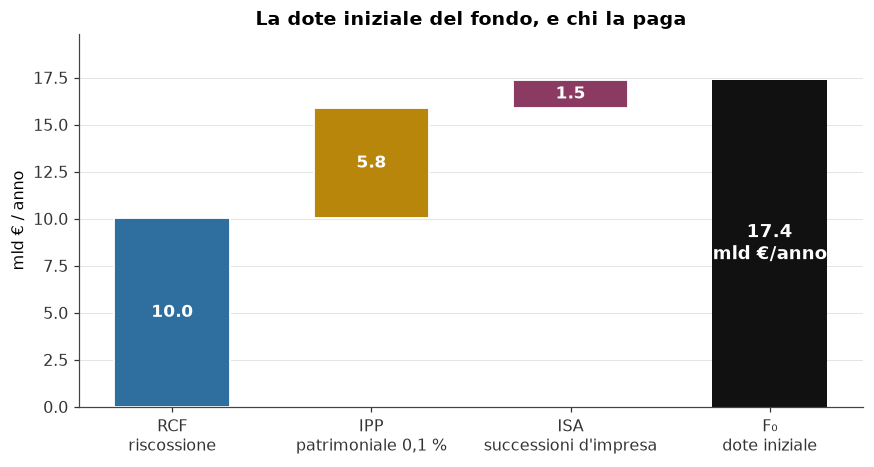

Le tre fonti valgono rispettivamente il 58%, 34% e 9% del totale.
La patrimoniale è la fonte più "solida", la successoria la più volatile.


In [4]:
# ── Chi paga cosa: waterfall della dote iniziale ─────────────────────────────
fig, ax = plt.subplots(figsize=(9.2, 4.4))

nomi = ["RCF\nriscossione", "IPP\npatrimoniale 0,1 %", "ISA\nsuccessioni d'impresa"]
vals = [BASE0["RCF"], BASE0["IPP"], BASE0["ISA"]]
cols = [C["rcf"], C["ipp"], C["isa"]]

bottom = 0.0
for nome, v, col in zip(nomi, vals, cols):
    ax.bar(nome, v, bottom=bottom, color=col, width=0.58, edgecolor="white", linewidth=1.2)
    ax.text(nome, bottom + v / 2, f"{v:.1f}", ha="center", va="center",
            color="white", fontweight="bold", fontsize=11)
    bottom += v

ax.bar("F₀\ndote iniziale", bottom, color=C["tot"], width=0.58)
ax.text(3, bottom / 2, f"{bottom:.1f}\nmld €/anno", ha="center", va="center",
        color="white", fontweight="bold", fontsize=12)

ax.set_ylabel("mld € / anno")
ax.set_title("La dote iniziale del fondo, e chi la paga")
ax.set_ylim(0, bottom * 1.14)
ax.xaxis.grid(False)
ax.spines[["top", "right"]].set_visible(False)
#ax.annotate(f"≈ {bottom / 58.9:.2f} € per abitante all'anno\n(solo per dare la scala)",
#            xy=(0.985, 0.93), xycoords="axes fraction", ha="right", va="top",
#            fontsize=9, color=C["grey"],
#            bbox=dict(boxstyle="round,pad=0.45", fc="#f6f4ee", ec="#d9d2c3"))
savefig(fig, "01_waterfall_dote")
plt.show()

print(f"Le tre fonti valgono rispettivamente il "
      f"{BASE0['RCF'] / BASE0['totale']:.0%}, {BASE0['IPP'] / BASE0['totale']:.0%} e "
      f"{BASE0['ISA'] / BASE0['totale']:.0%} del totale.")
print("La patrimoniale è la fonte più \"solida\", la successoria la più volatile.")


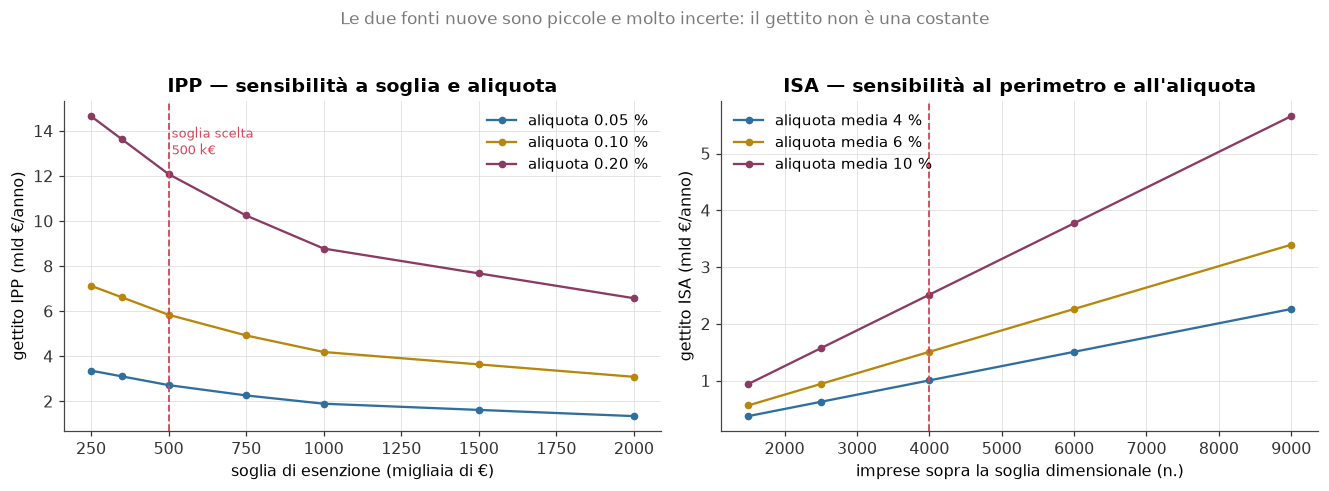

Impatto sulla dote iniziale di un errore del ±50 % su una singola fonte:
  RCF: ± 5.0 mld  →  F₀ tra 12.4 e 22.4 mld
  IPP: ± 2.9 mld  →  F₀ tra 14.5 e 20.3 mld
  ISA: ± 0.8 mld  →  F₀ tra 16.6 e 18.1 mld


In [5]:
# ── Sensibilità: quanto valgono davvero le mani che stiamo mettendo ──────────
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3))

# (a) IPP — soglia × aliquota
soglie = np.array([250e3, 350e3, 500e3, 750e3, 1e6, 1.5e6, 2e6])
aliquote = [0.0005, 0.001, 0.002]
for al in aliquote:
    y = [(P0["fonti.ipp_ricchezza_netta_mld"] * quota_oltre_soglia(s) * al
          * P0["fonti.ipp_compliance"]) - P0["fonti.ipp_costi_gestione_mld"] for s in soglie]
    axes[0].plot(soglie / 1e3, np.maximum(y, 0), marker="o", ms=4,
                 label=f"aliquota {al * 100:.2f} %")
axes[0].axvline(500, color=C["accent"], ls="--", lw=1.2)
axes[0].text(510, axes[0].get_ylim()[1] * 0.93, "soglia scelta\n500 k€", fontsize=8.5,
             color=C["accent"], va="top")
axes[0].set_xlabel("soglia di esenzione (migliaia di €)")
axes[0].set_ylabel("gettito IPP (mld €/anno)")
axes[0].set_title("IPP — sensibilità a soglia e aliquota")
axes[0].legend(loc="upper right")

# (b) ISA — numero imprese × aliquota
n_imp = np.array([1500, 2500, 4000, 6000, 9000])
for al in [0.04, 0.06, 0.10]:
    y = (n_imp / P0["fonti.isa_anni_ricambio"]) * P0["fonti.isa_valore_medio_partecipazione_mld"] * al
    axes[1].plot(n_imp, y, marker="o", ms=4, label=f"aliquota media {al * 100:.0f} %")
axes[1].axvline(4000, color=C["accent"], ls="--", lw=1.2)
axes[1].set_xlabel("imprese sopra la soglia dimensionale (n.)")
axes[1].set_ylabel("gettito ISA (mld €/anno)")
axes[1].set_title("ISA — sensibilità al perimetro e all'aliquota")
axes[1].legend(loc="upper left")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Le due fonti nuove sono piccole e molto incerte: il gettito non è una costante",
             y=1.03, fontsize=11, color=C["grey"])
plt.tight_layout()
savefig(fig, "02_sensibilita_fonti")
plt.show()

# Quanto pesa un errore del 50 % su ciascuna fonte?
print("Impatto sulla dote iniziale di un errore del ±50 % su una singola fonte:")
for k in ["RCF", "IPP", "ISA"]:
    d = 0.5 * BASE0[k]
    print(f"  {k}: ±{d:4.1f} mld  →  F₀ tra {BASE0['totale'] - d:4.1f} e {BASE0['totale'] + d:4.1f} mld")


## §5 — La dinamica delle entrate: shock, cicli, e il rischio che qualcuno le abolisca

Tre meccanismi, in ordine di importanza.

**1. Il trascinamento del PIL.** Le entrate crescono con l'economia. Il PIL nominale cresce al
2,5 % con volatilità dell'1,2 %; la patrimoniale cresce un po' di più (elasticità 1,2) perché i
patrimoni — soprattutto finanziari — battono il PIL. Non è un dettaglio: su 30 anni l'elasticità
1,2 vs 1,0 vale decine di miliardi.

**2. Lo shock di efficienza del fisco, ±20 %.** Come richiesto: ogni anno il gettito da riscossione
può variare di ±20 % per ragioni operative (organico, turnover dei funzionari, digitalizzazione,
esiti del contenzioso). È un **rumore sul livello**, non cumulativo: un anno storto non penalizza
per sempre. È il modo corretto di modellare un'efficienza amministrativa.

**3. Il rischio politico — il meccanismo che decide tutto.**

Un fondo che poggia su due imposte *nuove* e politicamente contestate è esposto a un rischio che
nessun modello finanziario standard cattura: **la maggioranza successiva le abolisce**. Lo
modelliamo con una **catena di Markov a due stati**:

```
        p(fav→avv) = 8 %/anno
   ┌─────────────┐          ┌─────────────┐
   │ FAVOREVOLE  │ ───────► │   AVVERSA   │
   │   (nessun   │          │  patrimoniale│
   │   rischio)  │ ◄─────── │  e successoria│
   └─────────────┘  p=40 %  │  → ZERO      │
                             └─────────────┘
```

Perché una catena e non tre monete indipendenti? Perché **la stessa maggioranza** abolisce tutte le
sue misure insieme: gli shock sono correlati, e trattarli come indipendenti sottostimerebbe
brutalmente la varianza del risultato. Nel regime avverso: `IPP → 0`, `ISA → 0`, `RCF → 60 %`
(il fisco si indebolisce, ma l'Agenzia delle Entrate non si chiude).

Con `p(fav→avv) = 8 %` e `p(avv→fav) = 40 %`, il regime avverso occupa circa il **17 % del tempo**,
con permanenze medie di ~2,5 anni. Se ti sembra poco: significa che in un orizzonte di 30 anni la
probabilità di attraversare almeno una fase di blackout è vicina al **90 %**. Prova a mettere
`p_fav_a_avv = 0.02` e guarda quanto cambiano i risultati: è la manopola più potente del notebook
dopo il rendimento.


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# §5 — Percorsi delle entrate fiscali
# ══════════════════════════════════════════════════════════════════════════════

def percorsi_macro(p, n, T, rng):
    """PIL nominale e inflazione. Restituisce array (n, T)."""
    g_mu = _arr(p["macro.gdp_nominale_crescita"], n)
    g_sd = _arr(p["macro.gdp_sigma"], n)
    g = np.clip(g_mu[:, None] + g_sd[:, None] * rng.standard_normal((n, T)),
                p["macro.gdp_floor"], p["macro.gdp_cap"])

    i_mu = _arr(p["macro.inflazione_media"], n)
    i_sd = _arr(p["macro.inflazione_sigma"], n)
    infl = np.clip(i_mu[:, None] + i_sd[:, None] * rng.standard_normal((n, T)),
                   p["macro.inflazione_floor"], p["macro.inflazione_cap"])
    return g, infl


def percorsi_regime(p, n, T, rng):
    """Catena di Markov a due stati. 0 = favorevole, 1 = avversa. Array (n, T)."""
    p_ff = _arr(p["politica.p_fav_a_avv"], n)
    p_rr = _arr(p["politica.p_avv_a_fav"], n)
    stato = np.full(n, int(p["politica.regime_iniziale"]), dtype=np.int8)
    reg = np.zeros((n, T), dtype=np.int8)
    for t in range(T):
        u = rng.random(n)
        vai_avv = (stato == 0) & (u < p_ff)
        torna_fav = (stato == 1) & (u < p_rr)
        stato = np.where(vai_avv, 1, stato)
        stato = np.where(torna_fav, 0, stato)
        reg[:, t] = stato
    return reg


def percorsi_entrate(p, n, T, rng):
    """Le tre fonti anno per anno, in mld €. Tutto vettorizzato su (n, T)."""
    g, infl = percorsi_macro(p, n, T, rng)
    reg = percorsi_regime(p, n, T, rng)
    _abol = int(p.get("politica.anno_abolizione", -1))
    if _abol > 0:
        reg[:, max(_abol - 1, 0):] = 1        # abolizione certa e permanente
    b = livelli_base(p, n)

    # moltiplicatori di regime
    m_rcf = np.where(reg == 1, _arr(p["fonti.rcf_moltiplicatore_regime_avverso"], n)[:, None], 1.0)
    m_ipp = np.where(reg == 1, _arr(p["fonti.ipp_moltiplicatore_regime_avverso"], n)[:, None], 1.0)
    m_isa = np.where(reg == 1, _arr(p["fonti.isa_moltiplicatore_regime_avverso"], n)[:, None], 1.0)

    # crescita cumulata (indice anno t = 1, 2, ... perché l'anno 0 è già in F₀)
    cum_rcf = np.cumprod(1.0 + g * _arr(p["fonti.rcf_elasticita_pil"], n)[:, None], axis=1)
    cum_ipp = np.cumprod(1.0 + g * _arr(p["fonti.ipp_elasticita_pil"], n)[:, None], axis=1)
    cum_isa = np.cumprod(1.0 + g * _arr(p["fonti.isa_elasticita_pil"], n)[:, None], axis=1)

    # shock di efficienza del fisco: uniforme ±20 %, sul livello, non cumulativo
    s_rcf = _arr(p["fonti.rcf_shock_efficienza"], n)[:, None]
    u = rng.uniform(-1.0, 1.0, (n, T))
    eff = 1.0 + s_rcf * u

    RCF = b["RCF"][:, None] * cum_rcf * eff * m_rcf

    IPP_lordo = b["IPP_lordo"][:, None] * cum_ipp
    IPP = np.maximum(IPP_lordo - _arr(p["fonti.ipp_costi_gestione_mld"], n)[:, None], 0.0) * m_ipp

    # ISA: componente regolare × irregolarità (Poisson-composto approssimato
    # con una lognormale a media 1, così il valore atteso resta quello di base)
    lam = _arr(p["fonti.isa_lumpiness"], n)[:, None]
    lump = np.exp(rng.normal(0.0, 1.0, (n, T)) * lam - 0.5 * lam ** 2)
    ISA = b["ISA"][:, None] * cum_isa * lump * m_isa

    # rumore residuo sul totale, applicato in modo proporzionale per mantenere
    # l'additività: I = RCF + IPP + ISA esattamente.
    s_tot = rng.normal(0.0, _arr(p["politica.shock_entrate_sigma"], n)[:, None], (n, T))
    scala = np.maximum(1.0 + s_tot, 0.05)
    RCF, IPP, ISA = RCF * scala, IPP * scala, ISA * scala

    return {
        "RCF": RCF, "IPP": IPP, "ISA": ISA,
        "I": RCF + IPP + ISA, "g": g, "infl": infl, "regime": reg,
    }


# ── verifica rapida ─────────────────────────────────────────────────────────
_t0 = time.time()
_chk = percorsi_entrate(P0, 4000, CFG.sim.anni, np.random.default_rng(1))
print(f"Simulazione di prova: {_chk['I'].shape[0]} percorsi × {_chk['I'].shape[1]} anni "
      f"in {time.time() - _t0:.2f} s")

_anni = np.arange(1, CFG.sim.anni + 1)
_tab = pd.DataFrame({
    "mediana": np.median(_chk["I"], axis=0),
    "P10": np.quantile(_chk["I"], 0.10, axis=0),
    "P90": np.quantile(_chk["I"], 0.90, axis=0),
    "P(I = 0)": np.mean(_chk["I"] < 0.5, axis=0),
}, index=_anni)

print(f"\nEntrate totali: mediana anno 1 = {np.median(_chk['I'][:, 0]):.1f} mld, "
      f"anno 30 = {np.median(_chk['I'][:, 29]):.1f} mld")
print(f"Quota di percorsi in regime avverso in un anno qualsiasi: "
      f"{_chk['regime'].mean():.1%}")
print(f"Probabilità di attraversare almeno un blackout entro 30 anni: "
      f"{np.mean(_chk['regime'][:, :30].max(axis=1) == 1):.1%}")

_tab.iloc[[0, 4, 9, 19, 29]].round(2)


Simulazione di prova: 4000 percorsi × 50 anni in 0.02 s

Entrate totali: mediana anno 1 = 17.4 mld, anno 30 = 37.2 mld
Quota di percorsi in regime avverso in un anno qualsiasi: 16.3%
Probabilità di attraversare almeno un blackout entro 30 anni: 92.4%


,mediana,P10,P90,P(I = 0)
1,17.38,13.27,20.66,0.0
5,19.07,7.20,22.91,0.0
10,21.80,8.00,26.33,0.0
20,28.48,10.17,34.57,0.0
30,37.23,13.03,45.20,0.0


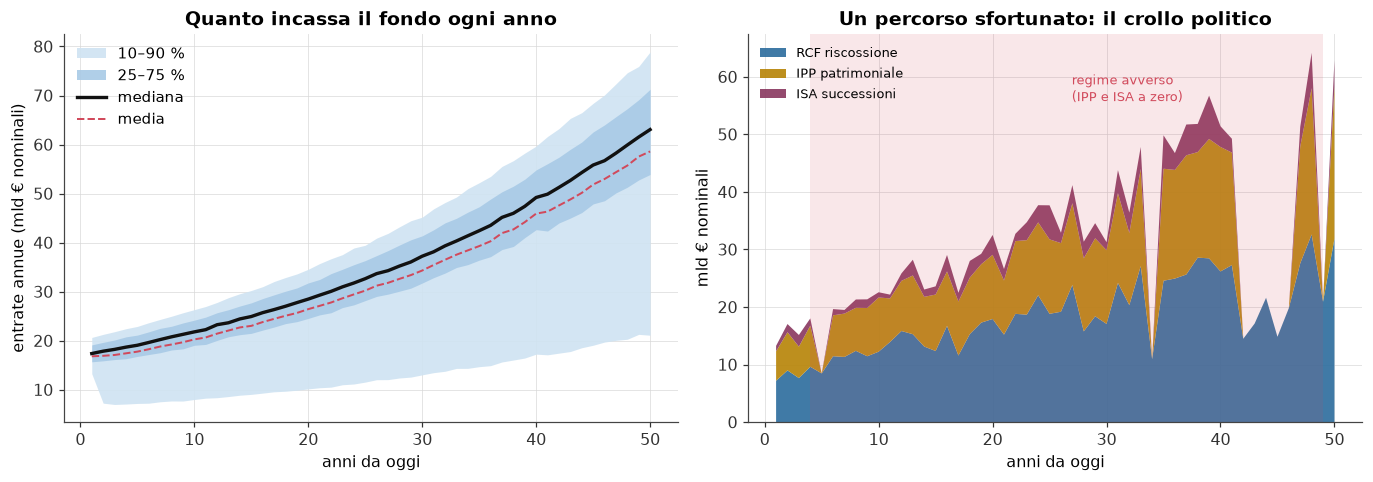

rischio basso (1 %/anno)    : entrate cumulate a 30 anni, mediana =      801 mld nominali
base (8 %/anno)             : entrate cumulate a 30 anni, mediana =      732 mld nominali
rischio alto (20 %/anno)    : entrate cumulate a 30 anni, mediana =      635 mld nominali


In [7]:
# ── Ventaglio delle entrate + un percorso esemplificativo ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5))

ax = axes[0]
x = _anni
for lo, hi, col, lab in [(0.10, 0.90, C["band1"], "10–90 %"),
                         (0.25, 0.75, C["band2"], "25–75 %")]:
    ax.fill_between(x, np.quantile(_chk["I"], lo, axis=0), np.quantile(_chk["I"], hi, axis=0),
                    color=col, alpha=0.9, lw=0, label=lab)
ax.plot(x, np.median(_chk["I"], axis=0), color=C["tot"], lw=2.2, label="mediana")
ax.plot(x, np.mean(_chk["I"], axis=0), color=C["accent"], lw=1.3, ls="--", label="media")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("entrate annue (mld € nominali)")
ax.set_title("Quanto incassa il fondo ogni anno")
ax.legend(loc="upper left", ncol=1)
ax.spines[["top", "right"]].set_visible(False)

# percorso esemplificativo: primo percorso che attraversa un blackout
j = int(np.argmax(_chk["regime"].max(axis=1) == 1))
ax = axes[1]
ax.stackplot(x, _chk["RCF"][j], _chk["IPP"][j], _chk["ISA"][j],
             labels=["RCF riscossione", "IPP patrimoniale", "ISA successioni"],
             colors=[C["rcf"], C["ipp"], C["isa"]], alpha=0.92, lw=0)
bl = np.where(_chk["regime"][j] == 1)[0]
if len(bl):
    ax.axvspan(bl.min(), bl.max() + 1, color=C["accent"], alpha=0.13, lw=0)
    ax.text(ax.get_ylim()[1] * 0.4, ax.get_ylim()[1] * 0.9,
            "regime avverso\n(IPP e ISA a zero)", fontsize=8.5, color=C["accent"], va="top")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € nominali")
ax.set_title("Un percorso sfortunato: il crollo politico")
ax.legend(loc="upper left", fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "03_entrate")
plt.show()

# Quanto vale il rischio politico in termini attesi?
_p_basso = {**P0, "politica.p_fav_a_avv": 0.01}
_p_alto = {**P0, "politica.p_fav_a_avv": 0.20}
for nome, pp in [("rischio basso (1 %/anno)", _p_basso), ("base (8 %/anno)", P0), ("rischio alto (20 %/anno)", _p_alto)]:
    r = percorsi_entrate(pp, 3000, 30, np.random.default_rng(7))
    tot = np.median(r["I"].sum(axis=1))
    print(f"{nome:28s}: entrate cumulate a 30 anni, mediana = {tot:8.0f} mld nominali")


## §6 — L'universo di acquisto: chi si compra, quanto costa, chi paga il premio

### 6.1 Cambio di natura: da fondo a holding

Nella versione precedente questo era un fondo che comprava un *paniere* di azioni, un po' come
un ETF. È la lettura sbagliata di quello che la proposta dice: **l'obiettivo non è il rendimento,
è il controllo**. Quindi il modello compra *quote di controllo*, una società alla volta, e il
criterio non è «quale titolo rende di più» ma «quale azienda serve comandare».

Da qui tre conseguenze che cambiano tutti i numeri a valle:

- La cassa non spesa non è «investita in borsa»: sta in **BTP** a fare da riserva, e finanzia
  l'acquisto successivo. L'azionario *è* la partecipata, non un paniere diversificato.
- Ogni acquisto è un **evento discreto**: la cassa esce, l'attivo entra, il NAV scende. Non è
  un rendimento, è una conversione — con una perdita dentro.
- Si compra **solo il pezzo che manca**. Il controllo è del *sistema pubblico* (MEF + CDP +
  fondo), non del fondo da solo.

### 6.2 Il tavolo dei target

| Impresa | Quota pubblica | Da comprare | Capitale | Prezzo oggi | Nota |
|---|---|---|---|---|---|
| **Poste Italiane** | 64,3 % | **0** | 18,3 | 0 | già controllata: non c'è niente da nazionalizzare |
| **Leonardo** | 30,2 % | 20,8 % | 30,0 | 8,6 | difesa, alta volatilità |
| **ENEL** | 23,6 % | 27,4 % | 75,0 | 28,3 | utility regolata |
| **ENI** | 9,2 % | 41,8 % | 48,0 | 27,6 | il pezzo più grosso da comprare |
| **Snam** | 30,9 % | 20,1 % | 17,0 | 4,7 | gasdotti |
| **Terna** | 29,9 % | 21,1 % | 14,0 | 4,1 | rete elettrica |
| **TIM rete (NetCo)** | 10,0 % | 100 % | — | 17,0 | non quotata: si ricompra da KKR |
| **ILVA (Taranto)** | 0 % | 100 % | — | 14,0 | non è un acquisto: è un salvataggio |

Il totale per mettere sotto controllo pubblico **tutto il perimetro** è **≈ 104 mld**, non 300:
la differenza rispetto ai conti della propaganda è che lo Stato molto lo possiede già e che il
premio si paga solo sulla parte comprata, non sulla capitalizzazione intera.

**Trenitalia è uscita dal paniere.** È al 100 % dentro Ferrovie dello Stato, che è al 100 % del
MEF: non c'è nessuna quota da comprare e i suoi conti passano dal contratto di servizio, cioè dal
bilancio dello Stato, non dal fondo. Metterla qui dentro sarebbe stato un doppio conteggio. Chi
promette di «riportare Trenitalia in mani pubbliche» promette una cosa che è già così.

### 6.3 Il premio di controllo, e perché è una perdita immediata

Per portare una quotata dal 24 % al 51 % non si compra al prezzo di listino: si paga un **premio**
a chi vende (media europea dei takeover: 30-40 %) più l'**impatto di mercato** di chi rastrella il
20-30 % del capitale (altro 2 %). Il modello usa il 35 %.

Quel premio **non è un investimento: è un trasferimento a privati**, e va perso subito. Nel
modello l'attivo entra in bilancio *a valore di mercato*, non a prezzo di acquisto: se il fondo
paga 28,3 mld per una quota che vale 21,0, il NAV scende di 7,3 nello stesso istante. Chi presenta
la nazionalizzazione come un investimento a costo zero sta nascondendo questa riga.

### 6.4 Il dividendo: chi lo incassa

Distinzione che sembra un dettaglio contabile e invece decide tutto:

- I dividendi sulle quote **già pubbliche** (il 24 % del MEF in ENEL) vanno al **bilancio dello
  Stato**, come oggi. Sono lo *status quo*: contarle come entrata del fondo sarebbe un doppio
  conteggio. Il modello le calcola e le tiene in una riga a parte, come *memo*.
- I dividendi sulle quote **comprate dal fondo** restano **nel fondo** e finanziano gli acquisti
  successivi. Sono l'unica novità: prima andavano a privati, ora vanno al settore pubblico.

Su un dividendo di cassa medio del 4-5 % e 100 mld di partecipate comprate, la seconda voce vale
4-5 mld l'anno: non è poco, ma non è la pioggia d'oro che si racconta.

### 6.5 Rendimenti e correlazione: perché non è un portafoglio

`μ` sono rendimenti **nominali total return** prudenti. Il punto che conta qui è un altro:
il drift comune è la manopola `mercati.drift_atteso` (5,5 %, con haircut del 25 % sul μ storico del
paniere), e ogni titolo ci aggiunge o toglie il proprio premio specifico. Se il fondo rende come i
BTP, comprare il controllo non ha più senso economico — e il modello lo mostra, perché la fase 2
(il residuo al 100 %) si attiva solo se la società rende più del BTP + 2 punti.

Con una correlazione media di **0,55** tra titoli italiani a controllo pubblico, il paniere riduce
la volatilità idiosincratica ma **non** il rischio di scenario: uno shock energetico o sui tassi
colpisce tutte le partecipate insieme, e il fondo le possiede tutte. Chi racconta che la holding
pubblica "diversifica" sta vendendo fumo.


In [8]:
# ══════════════════════════════════════════════════════════════════════════════
# §6 — L'universo di acquisto: le partecipate e il loro prezzo
# ══════════════════════════════════════════════════════════════════════════════

# ── Il tavolo dei target ─────────────────────────────────────────────────────
#  chiave         identificatore interno
#  cap_mld        capitalizzazione di Borsa (NaN per le non quotate)
#  quota_pub      quota già in mano pubblica (MEF + CDP): NON va comprata
#  target         quota che dà il controllo (51 %); 100 % per le non quotate
#  mu, sigma      rendimento totale atteso (nominale) e volatilità
#  div_yield      parte del rendimento che arriva come dividendo
#  costo_diretto  prezzo a trattativa per le non quotate (mld €)
#  recupero       frazione del costo che resta come valore d'avviamento
#  premio_mult    moltiplicatore del premio di controllo (0 = asset in crisi)
#
#  FONTE: capitalizzazioni di ordine di grandezza (2025-26), quote pubbliche da
#  partecipazioni MEF/CDP dichiarate. # TODO: aggiornare con Borsa Italiana.

_Q51 = CFG.benchmark.quota_controllo

TARGETS = pd.DataFrame([
    dict(chiave="ENEL", nome="ENEL", tipo="quotata",
         cap_mld=75.0, quota_pub=0.236, target=_Q51, premio_mult=1.0,
         mu=0.080, sigma=0.22, div_yield=0.045, costo_diretto=np.nan,
         recupero=1.0, nota="utility regolata, dividendo alto · MEF ~24 %"),
    dict(chiave="ENI", nome="ENI", tipo="quotata",
         cap_mld=48.0, quota_pub=0.092, target=_Q51, premio_mult=1.0,
         mu=0.072, sigma=0.25, div_yield=0.040, costo_diretto=np.nan,
         recupero=1.0, nota="petrolifero, ciclico · MEF 4,4 % + CDP 4,8 %"),
    dict(chiave="Leonardo", nome="Leonardo", tipo="quotata",
         cap_mld=30.0, quota_pub=0.302, target=_Q51, premio_mult=1.0,
         mu=0.100, sigma=0.33, div_yield=0.015, costo_diretto=np.nan,
         recupero=1.0, nota="difesa, alta volatilità · MEF ~30 %"),
    dict(chiave="Snam", nome="Snam", tipo="quotata",
         cap_mld=17.0, quota_pub=0.309, target=_Q51, premio_mult=1.0,
         mu=0.065, sigma=0.19, div_yield=0.036, costo_diretto=np.nan,
         recupero=1.0, nota="gasdotti, regolata · CDP ~31 %"),
    dict(chiave="Terna", nome="Terna", tipo="quotata",
         cap_mld=14.0, quota_pub=0.299, target=_Q51, premio_mult=1.0,
         mu=0.068, sigma=0.17, div_yield=0.038, costo_diretto=np.nan,
         recupero=1.0, nota="rete elettrica, bassa beta · CDP ~30 %"),
    dict(chiave="Poste", nome="Poste Italiane", tipo="quotata",
         cap_mld=18.3, quota_pub=0.643, target=_Q51, premio_mult=1.0,
         mu=0.075, sigma=0.22, div_yield=0.045, costo_diretto=np.nan,
         recupero=1.0, nota="GIÀ controllata: al sistema pubblico basta il 51 %"),
    dict(chiave="TIMrete", nome="TIM rete (NetCo)", tipo="non_quotata",
         cap_mld=np.nan, quota_pub=0.10, target=1.0, premio_mult=0.0,
         mu=0.055, sigma=0.28, div_yield=0.015, costo_diretto=17.0,
         recupero=1.0, nota="venduta a KKR nel 2024: si ricompra · CDP ~10 %"),
    dict(chiave="ILVA", nome="ILVA (Taranto)", tipo="non_quotata",
         cap_mld=np.nan, quota_pub=0.00, target=1.0, premio_mult=0.0,
         mu=0.045, sigma=0.30, div_yield=0.000, costo_diretto=14.0,
         recupero=0.40, nota="non un acquisto: un salvataggio (vedi §11.3)"),
]).set_index("chiave")

# Il fondo compra solo il pezzo che manca: il controllo è del SISTEMA PUBBLICO
# (MEF + CDP + fondo), non del fondo da solo.
TARGETS["quota_da_comprare"] = np.maximum(TARGETS["target"] - TARGETS["quota_pub"], 0.0)
TARGETS["residuo_privato"] = 1.0 - np.maximum(TARGETS["target"], TARGETS["quota_pub"])

# ── Ordine strategico di acquisizione ────────────────────────────────────────
#  Si compra prima ciò che è più urgente e più piccolo: si parte dal salvataggio
#  industriale, si finisce con la difesa. Poste non compare: è già controllata.
ORDINE_CONTROLLO = ["ILVA", "ENI", "ENEL", "Terna", "Snam", "TIMrete", "Leonardo"]
#  Fase 2 (residuo al 100 %): in ordine di rendimento atteso decrescente.
ORDINE_RESIDUO = ["Leonardo", "ENEL", "Poste", "ENI", "Terna", "Snam"]

# ── Il paniere passivo (solo per lo scenario di confronto) ───────────────────
PESI_PASSIVO = {"ENEL": 0.24, "ENI": 0.20, "Poste": 0.13, "Terna": 0.12,
                "Snam": 0.12, "Leonardo": 0.09, "TIMrete": 0.10}

BASKET = TARGETS.loc[list(PESI_PASSIVO), ["nome", "mu", "sigma", "div_yield",
                                          "quota_pub", "tipo", "nota"]].copy()
BASKET.insert(0, "peso", [PESI_PASSIVO[k] for k in BASKET.index])

assert abs(BASKET["peso"].sum() - 1.0) < 1e-9, "i pesi devono sommare a 1"

RHO = 0.55  # correlazione media tra i titoli del paniere

mu_paniere = float((BASKET["peso"] * BASKET["mu"]).sum())
w = BASKET["peso"].to_numpy()
s = BASKET["sigma"].to_numpy()
var_paniere = RHO * (w * s).sum() ** 2 + (1 - RHO) * (w ** 2 * s ** 2).sum()
sigma_paniere = float(np.sqrt(var_paniere))
div_paniere = float((BASKET["peso"] * BASKET["div_yield"]).sum())

_costo_p1 = ((TARGETS["quota_da_comprare"] * TARGETS["cap_mld"].fillna(0.0)
              * (1 + CFG.benchmark.premio_controllo * TARGETS["premio_mult"])
              * (1 + CFG.benchmark.impatto_mercato))
             + TARGETS["costo_diretto"].fillna(0.0))
TARGETS["costo_oggi"] = _costo_p1.to_numpy()

display(TARGETS[["nome", "tipo", "cap_mld", "quota_pub", "target",
                 "quota_da_comprare", "mu", "div_yield", "costo_oggi", "nota"]]
        .style.format({"cap_mld": "{:,.0f}", "quota_pub": "{:.1%}", "target": "{:.0%}",
                       "quota_da_comprare": "{:.1%}", "mu": "{:.1%}", "div_yield": "{:.1%}",
                       "costo_oggi": "{:,.1f}"}, na_rep="—")
        .set_caption("Il tavolo dei target — costi al prezzo di oggi, premio 35 % incluso"))

print(f"Controllo del sistema pubblico (51 %): {_costo_p1.sum():6.1f} mld € di acquisti")
print(f"  di cui fase 2 (residuo al 100 %)   : "
      f"{(TARGETS['residuo_privato'] * TARGETS['cap_mld'].fillna(0.0) * (1 + CFG.benchmark.premio_controllo * TARGETS['premio_mult']) * (1 + CFG.benchmark.impatto_mercato)).sum():6.1f} mld €")
print(f"Già controllate dal sistema pubblico: "
      f"{', '.join(TARGETS.index[TARGETS['quota_pub'] >= TARGETS['target']]) or 'nessuna'}")
print()
print(f"μ del paniere passivo (pesi × μ)   : {mu_paniere:6.2%} nominale")
print(f"σ del paniere passivo (ρ = {RHO:.2f})     : {sigma_paniere:6.2%}")
print(f"dividend yield di cassa            : {div_paniere:6.2%} → il resto è prezzo")
print(f"μ usato nel modello (prudenziale)  : {CFG.mercati.drift_atteso:.2%} nominale "
      f"(haircut {(1 - CFG.mercati.drift_atteso / mu_paniere):.0%})")
print(f"  → in termini reali (infl. 2 %)   : {(1 + CFG.mercati.drift_atteso) / 1.02 - 1:.2%}")
print(f"  → premio per il rischio vs BTP   : {CFG.mercati.drift_atteso - CFG.mercati.btp_yield_lungo:.2%}")


,nome,tipo,cap_mld,quota_pub,target,quota_da_comprare,mu,div_yield,costo_oggi,nota
chiave,,,,,,,,,,
ENEL,ENEL,quotata,75,23.6%,51%,27.4%,8.0%,4.5%,28.3,"utility regolata, dividendo alto · MEF ~24 %"
ENI,ENI,quotata,48,9.2%,51%,41.8%,7.2%,4.0%,27.6,"petrolifero, ciclico · MEF 4,4 % + CDP 4,8 %"
Leonardo,Leonardo,quotata,30,30.2%,51%,20.8%,10.0%,1.5%,8.6,"difesa, alta volatilità · MEF ~30 %"
Snam,Snam,quotata,17,30.9%,51%,20.1%,6.5%,3.6%,4.7,"gasdotti, regolata · CDP ~31 %"
Terna,Terna,quotata,14,29.9%,51%,21.1%,6.8%,3.8%,4.1,"rete elettrica, bassa beta · CDP ~30 %"
Poste,Poste Italiane,quotata,18,64.3%,51%,0.0%,7.5%,4.5%,0.0,GIÀ controllata: al sistema pubblico basta il 51 %
TIMrete,TIM rete (NetCo),non_quotata,—,10.0%,100%,90.0%,5.5%,1.5%,17.0,venduta a KKR nel 2024: si ricompra · CDP ~10 %
ILVA,ILVA (Taranto),non_quotata,—,0.0%,100%,100.0%,4.5%,0.0%,14.0,non un acquisto: un salvataggio (vedi §11.3)


Controllo del sistema pubblico (51 %):  104.3 mld € di acquisti
  di cui fase 2 (residuo al 100 %)   :  133.1 mld €
Già controllate dal sistema pubblico: Poste

μ del paniere passivo (pesi × μ)   :  7.38% nominale
σ del paniere passivo (ρ = 0.55)     : 18.33%
dividend yield di cassa            :  3.64% → il resto è prezzo
μ usato nel modello (prudenziale)  : 5.50% nominale (haircut 25%)
  → in termini reali (infl. 2 %)   : 3.43%
  → premio per il rischio vs BTP   : 2.00%


α nominale: mediana 5.35%, media 5.34%, σ 20.52%, P5 -26.91%, P95 37.50%
α reale   : mediana 3.26%
ENEL      : rendimento totale atteso 6.18%, di cui dividendo 4.50%


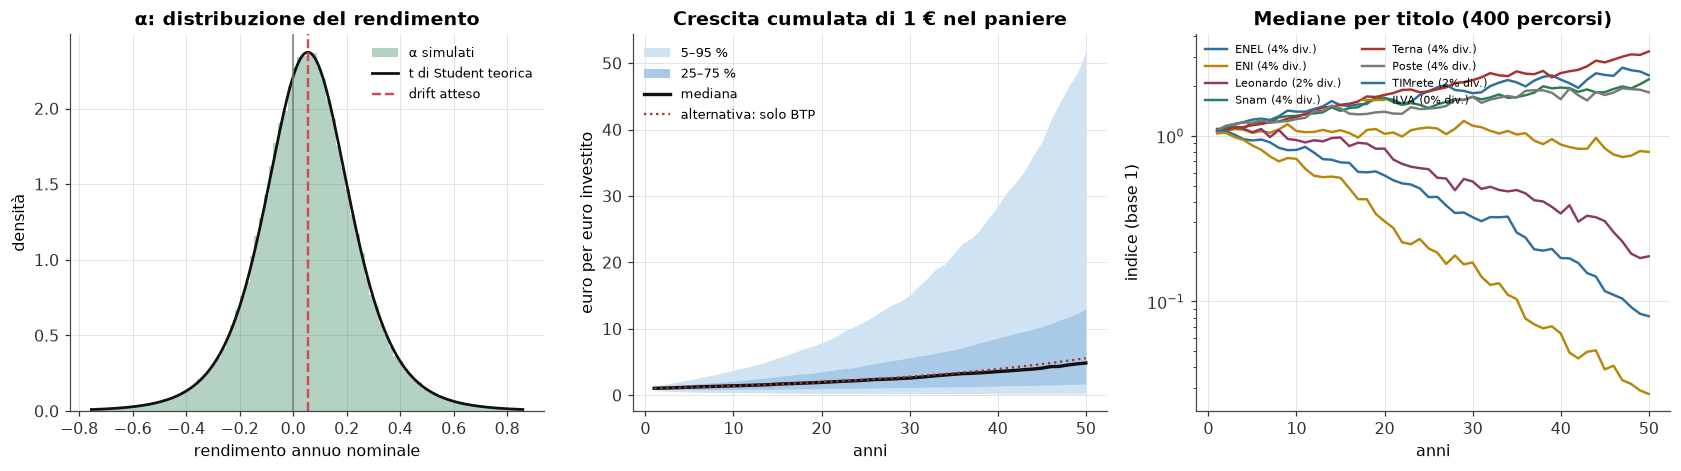

In [9]:
# ── α_t: il rendimento annuo del paniere passivo ────────────────────────────

def percorsi_alpha(p, n, T, rng, infl):
    """Rendimento NOMINALE annuo del paniere passivo, al netto delle commissioni.
    Due modalità:
      t_student → α = drift + σ·t(ν)          [default: prudente, code grasse]
      uniform   → α reale = drift + hw·U(−1,1), poi convertito in nominale
    """
    if p["mercati.alpha_mode"] == "uniform":
        drift_r = _arr(p["mercati.uniform_drift_reale"], n)[:, None]
        hw = _arr(p["mercati.uniform_semilarghezza_reale"], n)[:, None]
        a_reale = drift_r + hw * rng.uniform(-1.0, 1.0, (n, T))
        alpha = (1.0 + a_reale) * (1.0 + infl) - 1.0
    else:
        drift = _arr(p["mercati.drift_atteso"], n)[:, None]
        sd = _arr(p["mercati.sigma_alpha"], n)[:, None]
        nu = float(p["mercati.t_nu"])
        alpha = drift + sd * rng.standard_t(nu, size=(n, T))
    # Le code di Student possono generare rendimenti < -100 %, che non esistono:
    # un investimento può al massimo azzerarsi. Senza questo taglio il prodotto
    # cumulato cambia segno e le mediane diventano rumore.
    alpha = np.maximum(alpha, -0.99)
    return alpha - _arr(p["mercati.fee_gestione"], n)[:, None]


def mu_titoli(p, n):
    """Rendimento totale atteso per singolo titolo, ancorato al drift comune.

    Il drift è il motore comune (è la manopola `mercati.drift_atteso`, quella
    che l'MCMC aggiorna); il premio specifico di ogni titolo è la distanza dal
    μ del paniere, e resta fisso. Così la manopola del rendimento muove davvero
    anche le partecipate, invece di lasciarle intoccate.
    """
    base = _arr(p["mercati.drift_atteso"], n)[:, None]        # (n, 1)
    extra = TARGETS["mu"].to_numpy() - mu_paniere              # (A,)
    return base + extra[None, :]                               # (n, A)


def percorsi_titoli(p, n, T, rng, rho=RHO):
    """Rendimenti TOTALI annui per singolo titolo (n, T, A).
    t di Student multivariata con correlazione costante ρ."""
    A = len(TARGETS)
    R = np.full((A, A), rho) + (1 - rho) * np.eye(A)
    Lc = np.linalg.cholesky(R)
    z = rng.standard_normal((n, T, A)) @ Lc.T
    z = z / np.sqrt(rng.chisquare(5.0, size=(n, T, 1)) / 5.0)   # code grasse
    mu_t = mu_titoli(p, n)[:, None, :]
    # Floor a -99 %: con t di Student a 5 gradi di libertà lo 0,5 % dei
    # titolo-anni finirebbe sotto -100 %, che è impossibile e manda in tilt
    # il prodotto cumulato (e quindi i grafici e la composizione del NAV).
    return np.maximum(mu_t + TARGETS["sigma"].to_numpy()[None, None, :] * z, -0.99)


_rng_a = np.random.default_rng(2)
_infl_a = percorsi_macro(P0, 6000, CFG.sim.anni, _rng_a)[1]
_AL = percorsi_alpha(P0, 6000, CFG.sim.anni, _rng_a, _infl_a)
_TOT = percorsi_titoli(P0, 6000, CFG.sim.anni, _rng_a)
print(f"α nominale: mediana {np.median(_AL):.2%}, media {_AL.mean():.2%}, "
      f"σ {_AL.std():.2%}, P5 {np.quantile(_AL, 0.05):.2%}, P95 {np.quantile(_AL, 0.95):.2%}")
print(f"α reale   : mediana {np.median((1 + _AL) / (1 + _infl_a) - 1):.2%}")
_i = list(TARGETS.index).index("ENEL")
print(f"ENEL      : rendimento totale atteso {_TOT[:, :, _i].mean():.2%}, "
      f"di cui dividendo {float(TARGETS.loc['ENEL', 'div_yield']):.2%}")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.4))

# (a) distribuzione di α
ax = axes[0]
_xlo, _xhi = np.quantile(_AL, [0.002, 0.998])
_vis = _AL[(_AL >= _xlo) & (_AL <= _xhi)]
ax.hist(_vis, bins=90, density=True, color=C["equity"], alpha=0.35, label="α simulati")
xs = np.linspace(_xlo, _xhi, 400)
ax.plot(xs, stats.t.pdf(xs, CFG.mercati.t_nu, loc=CFG.mercati.drift_atteso,
                        scale=CFG.mercati.sigma_alpha), color=C["tot"], lw=1.8, label="t di Student teorica")
ax.axvline(CFG.mercati.drift_atteso, color=C["accent"], lw=1.6, ls="--", label="drift atteso")
ax.axvline(0, color=C["grey"], lw=1)
ax.set_xlabel("rendimento annuo nominale")
ax.set_ylabel("densità")
ax.set_title("α: distribuzione del rendimento")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (b) ventaglio del rendimento cumulato
ax = axes[1]
cum = np.cumprod(1 + _AL, axis=1)
x = np.arange(1, CFG.sim.anni + 1)
ax.fill_between(x, np.quantile(cum, 0.05, axis=0), np.quantile(cum, 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(x, np.quantile(cum, 0.25, axis=0), np.quantile(cum, 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(x, np.median(cum, axis=0), color=C["tot"], lw=2.2, label="mediana")
ax.plot(x, np.cumprod(np.full(CFG.sim.anni, 1 + CFG.mercati.btp_yield_lungo)), color=C["btp"],
        lw=1.5, ls=":", label="alternativa: solo BTP")
ax.set_xlabel("anni")
ax.set_ylabel("euro per euro investito")
ax.set_title("Crescita cumulata di 1 € nel paniere")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (c) percorsi per titolo
ax = axes[2]
paths = np.cumprod(1 + percorsi_titoli(P0, 400, CFG.sim.anni, np.random.default_rng(3)), axis=1)
for i, t in enumerate(TARGETS.index):
    ax.plot(np.arange(1, CFG.sim.anni + 1), np.median(paths[:, :, i], axis=0),
            lw=1.6, label=f"{t} ({float(TARGETS.loc[t, 'div_yield']):.0%} div.)")
ax.set_xlabel("anni")
ax.set_ylabel("indice (base 1)")
ax.set_title("Mediane per titolo (400 percorsi)")
ax.legend(fontsize=7.0, ncol=2, loc="upper left")
ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "04_rendimenti")
plt.show()


## §7 — La riserva liquida: curva dei tassi, scadenze, tetto di duration

### 7.1 La curva, non il tasso unico

Il modello non usa «il tasso BTP»: usa una **curva**, perché la scelta della scadenza è la vera
decisione. Due fattori, entrambi mean-reverting:

$$L_{t+1} = L_t + \kappa_L(\bar{y} - L_t) + \sigma_L\varepsilon_t, \qquad
S_{t+1} = S_t + \kappa_S(\bar{S} - S_t) + \sigma_S\eta_t$$

$$y_t(\tau) = L_t + S_t\cdot\frac{\tau - 10}{20}, \qquad \tau \in \{3, 5, 10, 30\}$$

con $\bar{y} = 3{,}5\%$ (il 10 anni di lungo periodo), $\kappa_L = 0{,}25$ (memoria di ~4 anni),
$\sigma_L = 1{,}1\%$, e una pendenza $\bar{S} = 1\%$ (il 30 anni rende un punto più del 10).
La pendenza ha vita più breve ($\kappa_S = 0{,}35$): le curve si irripidiscono e si appiattiscono
più in fretta di quanto si muova il livello. È quello che è successo tra il 2011 e il 2022.

Il rendimento totale non è la cedola: è cedola **più** variazione di prezzo:

$$r_t(\tau) \approx y_t(\tau) - D_\tau\,\Delta y_t(\tau) + \tfrac{1}{2}C_\tau\,(\Delta y_t)^2,
\qquad D_\tau = 0{,}75\,\tau,\quad C_\tau = c\cdot\tau^2$$

Il termine di convessità ha $c = 0$ di default, e non è pigrizia: con la volatilità dei tassi
usata qui ($\sigma_y = 1{,}1\%$ all'anno) e una scadenza di 30 anni, quel termine vale
$\tfrac{1}{2}\cdot 900\cdot(0{,}011)^2 \approx 5{,}4\%$ all'anno. Non è un rendimento: è un
artefatto di Taylor applicato a un processo che nella realtà non si muove di un punto ogni anno.
Lasciarlo acceso farebbe sembrare i trentennali un affare. Porta `btp_convessita` a 1 se vuoi
vedere l'artefatto con i tuoi occhi.

### 7.2 La regola: si compra la scadenza che rende di più, ma non oltre il tetto

`btp_politica = "max_carry"` (default). Il fondo compra **la scadenza più lunga consentita**, perché
in una curva normale rende di più; se la curva si inverte, compra corto. Non è una strategia
sofisticata, è una regola e lo dice: **l'unica protezione vera è `btp_duration_max`**, fissato a
**10 anni**.

Il numero che rende l'idea: con 30 anni di scadenza ($D \approx 22{,}5$), una salita dei tassi
dell'1 % costa il **22 % del capitale**. Con 3 anni, il 2,3 %. Il 30 anni rende ~1 punto in più e
rischia dieci volte tanto. Un fondo pubblico che compra trentennali per «incassare i tassi» sta
scommettendo sui tassi con i soldi dei contribuenti.

Le altre politiche disponibili:

| `btp_politica` | Cosa fa | A cosa serve |
|---|---|---|
| `max_carry` | tutta la riserva in BTP, scadenza massima entro il tetto | caso base: la cassa è riserva, non investimento |
| `tatticale` | ripartizione BTP/equity anno per anno | scenario «in base a ciò che conviene» |
| `constant` | quota fissa `btp_quota` in BTP, il resto nel paniere passivo | confronto con la versione «fondo» |
| `equity_only` | φ = 0 | quanto costa rinunciare alle cedole |

La regola tatticale merita una riga, perché è quella che tutti promettono. È un **Merton miope**:
quota azionaria $=(\mu - y_t)/(\gamma\sigma^2)$, con $\gamma = 3$, calcolata sul rendimento *corrente*
della scadenza scelta. Nessun look-ahead, nessuna previsione: reagisce e basta. Con un premio
atteso di 2 punti e σ = 16 %, la quota azionaria è ~26 % — che è più o meno quello che fanno i
fondi veri, e molto meno di quello che promettono i tassi di rendimento dei volantini.

### 7.3 Il punto scomodo: comprare BTP non riduce il debito pubblico

Questa è la parte che di solito sparisce dalle presentazioni politiche.

Il fondo è **pubblico**. Quando compra un BTP sul secondario, il Tesoro non incassa nulla: il
titolo cambia semplicemente proprietario. Lo Stato continua a pagare la stessa cedola, solo a
un creditore diverso — sé stesso, per interposta persona. **Nel bilancio consolidato del settore
pubblico, debito e credito si elidono: il debito netto non scende di un euro.**

Il beneficio reale esiste, ma solo su due canali:

1. **La quota detenuta da non residenti (~27 %).** Su quella parte, la cedola esce dal Paese. Se il
   fondo la ricompra, quella cedola resta in Italia: è un vero trasferimento di ricchezza
   dall'estero al contribuente italiano. Su 800 mld di debito estero al 3,5 %, sono ~28 mld/anno
   di interessi che smettono di uscire — ma servono decenni per ricomprarli tutti.
2. **La riduzione dello spread.** Un creditore stabile e domestico riduce la volatilità dei prezzi
   e quindi il premio di rischio richiesto dal mercato. Questo è il vero guadagno strategico, ed è
   anche il più difficile da quantificare con onestà: dipende dalla credibilità, non dalla size.

Qui però la riserva BTP ha un ruolo diverso e più modesto che nella versione «fondo»: **è la cassa
in attesa di essere spesa**. Non è una strategia di riacquisto del debito, è un parcheggio. Il
modello la tratta così, e il confronto della §10 (holding vs «stesse entrate, solo BTP») serve a
dire quanto rende quel parcheggio rispetto al comprare.


Rendimento riserva BTP: media 3.57%, σ 9.13%, P5 -11.58%, P95 18.74%
Anni con rendimento BTP totale NEGATIVO (effetto prezzo): 33.9% — la cedola c'è sempre, ma il capitale oscilla.
Scadenza scelta: 10 anni nel 94% dei casi (tetto: 10 anni)


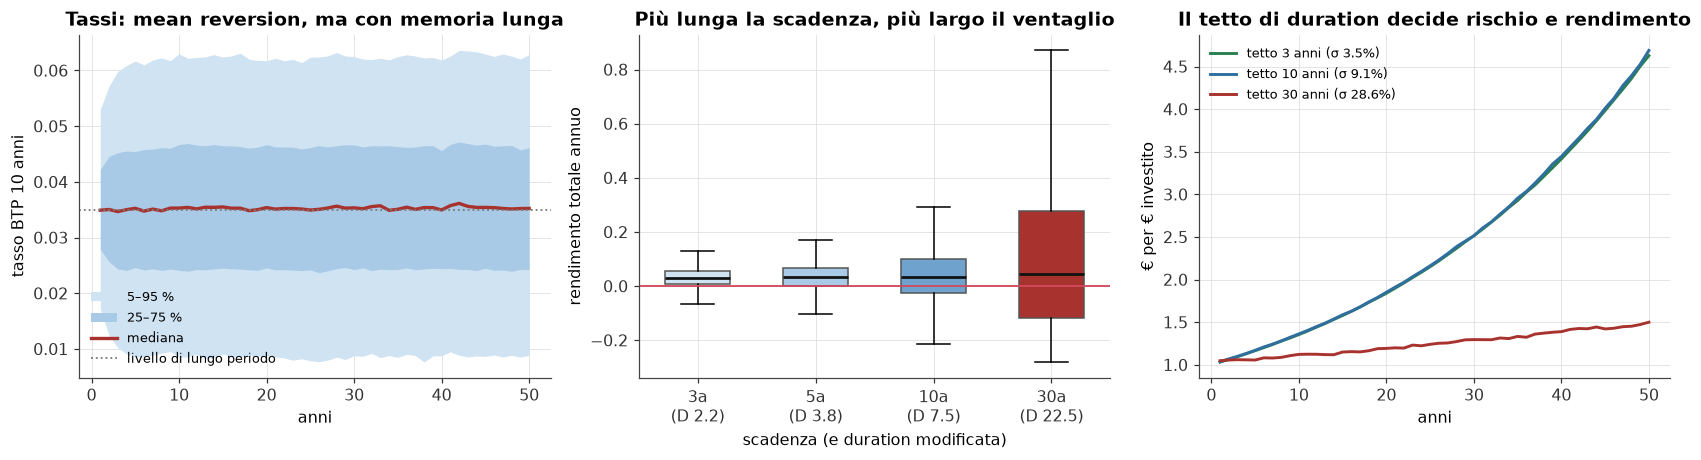

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
# §7 — La riserva liquida: curva dei tassi, scadenze, tetto di duration
# ══════════════════════════════════════════════════════════════════════════════

MATURITA = np.array([3.0, 5.0, 10.0, 30.0])     # anni


def curva_tassi(p, n, T, rng, deterministico=False):
    """Curva per scadenza, da due fattori (livello e pendenza), entrambi OU.

        L_{t+1} = L_t + κ_L (ȳ − L_t) + σ_L ε_t
        S_{t+1} = S_t + κ_S (S̄ − S_t) + σ_S η_t
        y_t(τ)  = L_t + S_t · (τ − 10)/20

    Ritorna y (n, T+1, M) e il livello L (n, T+1).
    """
    theta = _arr(p["mercati.btp_yield_lungo"], n)[:, None]
    k_l = float(p["mercati.btp_ou_kappa"])
    sd_l = float(p["mercati.btp_ou_sigma"])
    s_0 = float(p["mercati.btp_slope_iniziale"])
    k_s = float(p["mercati.btp_slope_kappa"])
    sd_s = float(p["mercati.btp_slope_sigma"])

    L = np.empty((n, T + 1))
    S = np.empty((n, T + 1))
    L[:, 0] = theta[:, 0]
    S[:, 0] = s_0
    eps_l = np.zeros((n, T)) if deterministico else rng.standard_normal((n, T))
    eps_s = np.zeros((n, T)) if deterministico else rng.standard_normal((n, T))

    for t in range(T):
        dL = k_l * (theta[:, 0] - L[:, t]) + sd_l * eps_l[:, t]
        dS = k_s * (s_0 - S[:, t]) + sd_s * eps_s[:, t]
        if int(p["mercati.spread_shock_anno"]) == t + 1:
            dL = dL + float(p["mercati.spread_shock_bp"]) / 10_000.0
        L[:, t + 1] = np.clip(L[:, t] + dL, 0.001, 0.20)
        S[:, t + 1] = np.clip(S[:, t] + dS, -0.020, 0.030)

    y = L[:, :, None] + S[:, :, None] * ((MATURITA[None, None, :] - 10.0) / 20.0)
    return np.maximum(y, 0.0005), L


def pesi_scadenze(p, y, T):
    """Pesi sulle scadenze: 100 % sulla scadenza che rende di più entro il tetto.

    È la regola `max_carry`, ed è dichiaratamente stupida: compra sempre la
    scadenza più lunga consentita, perché in una curva normale rende di più.
    Se la curva si inverte compra corto. Il tetto `btp_duration_max` è l'unica
    protezione contro il rischio di prezzo, e quindi l'unica manopola che conta.
    """
    dmax = float(p["mercati.btp_duration_max"])
    elig = MATURITA <= dmax + 1e-9
    if not elig.any():
        elig = MATURITA == MATURITA.min()
    ye = np.where(elig[None, None, :], y, -np.inf)
    idx = np.argmax(ye, axis=2)                       # (n, T+1)
    W = np.zeros_like(ye)
    np.put_along_axis(W, idx[:, :, None], 1.0, axis=2)
    return W[:, :-1, :], idx[:, :-1]


def percorsi_btp(p, n, T, rng, alpha=None, deterministico=False):
    """Rendimento totale della riserva liquida + politica di allocazione.

    Ritorna un dizionario con: r_btp (rendimento della gamba obbligazionaria),
    y / L (curva), scadenza scelta, φ (quota in BTP della riserva) e r_sleeve
    (rendimento effettivo della riserva, BTP + eventuale gamba azionaria).
    """
    y, L = curva_tassi(p, n, T, rng, deterministico)
    W, scad = pesi_scadenze(p, y, T)                             # (n, T, M)
    dy = np.diff(y, axis=1)                                      # (n, T, M)
    D = 0.75 * MATURITA[None, None, :]                           # duration ≈ 0.75 τ
    Cx = float(p["mercati.btp_convessita"]) * MATURITA[None, None, :] ** 2
    r_m = y[:, :-1, :] - D * dy + 0.5 * Cx * dy ** 2             # (n, T, M)
    r_btp = (W * r_m).sum(axis=2)                                # (n, T)

    pol = p["mercati.btp_politica"]
    if pol == "equity_only":
        phi = np.zeros((n, T))
    elif pol == "constant":
        phi = np.full((n, T), float(p["mercati.btp_quota"]))
    elif pol == "tatticale" and alpha is not None:
        # Merton miope: quota azionaria = premio atteso / (γ σ²). Nessun
        # look-ahead: il premio usa il rendimento *corrente* della scadenza
        # scelta, che è osservabile oggi.
        mu = (_arr(p["mercati.drift_atteso"], n)[:, None]
              - _arr(p["mercati.fee_gestione"], n)[:, None])
        sd = _arr(p["mercati.sigma_alpha"], n)[:, None]
        gamma = float(p["mercati.tatticale_avversione"])
        quota_az = np.clip((mu - r_btp) / (gamma * sd ** 2 + 1e-12), 0.0, 1.0)
        phi = 1.0 - quota_az
    else:
        phi = np.ones((n, T))

    r_az = alpha if alpha is not None else np.zeros((n, T))
    return {"r_btp": r_btp, "y": y, "L": L, "W": W, "scadenza": scad,
            "phi": phi, "r_sleeve": phi * r_btp + (1 - phi) * r_az}


# ── diagnostica ─────────────────────────────────────────────────────────────
_btp = percorsi_btp(P0, 6000, CFG.sim.anni, np.random.default_rng(4))
_btp_ret, _y = _btp["r_btp"], _btp["y"]
print(f"Rendimento riserva BTP: media {_btp_ret.mean():.2%}, σ {_btp_ret.std():.2%}, "
      f"P5 {np.quantile(_btp_ret, 0.05):.2%}, P95 {np.quantile(_btp_ret, 0.95):.2%}")
print(f"Anni con rendimento BTP totale NEGATIVO (effetto prezzo): "
      f"{np.mean(_btp_ret < 0):.1%} — la cedola c'è sempre, ma il capitale oscilla.")
_scad = MATURITA[_btp["scadenza"]]
_val, _cnt = np.unique(_scad, return_counts=True)
print(f"Scadenza scelta: {_val[np.argmax(_cnt)]:.0f} anni nel {_cnt.max() / _cnt.sum():.0%} "
      f"dei casi (tetto: {CFG.mercati.btp_duration_max:.0f} anni)")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.3))
x = np.arange(1, CFG.sim.anni + 1)
_y10 = _y[:, 1:, 2]                      # tasso a 10 anni

ax = axes[0]
ax.fill_between(x, np.quantile(_y10, 0.05, axis=0), np.quantile(_y10, 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(x, np.quantile(_y10, 0.25, axis=0), np.quantile(_y10, 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(x, np.median(_y10, axis=0), color=C["btp"], lw=2.2, label="mediana")
ax.axhline(CFG.mercati.btp_yield_lungo, color=C["grey"], ls=":", lw=1.2, label="livello di lungo periodo")
ax.set_xlabel("anni")
ax.set_ylabel("tasso BTP 10 anni")
ax.set_title("Tassi: mean reversion, ma con memoria lunga")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
_rette = []
for j, tau in enumerate(MATURITA):
    dy_j = np.diff(_y[:, :, j], axis=1)
    r_j = _y[:, :-1, j] - 0.75 * tau * dy_j + 0.5 * (tau ** 2) * dy_j ** 2
    _rette.append(r_j.ravel())
bp = ax.boxplot(_rette, tick_labels=[f"{t:.0f}a\n(D {0.75 * t:.1f})" for t in MATURITA],
                patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=C["tot"], lw=1.8))
for patch, col in zip(bp["boxes"], [C["band1"], C["band2"], C["band3"], C["btp"]]):
    patch.set_facecolor(col)
    patch.set_edgecolor("#555555")
ax.axhline(0, color=C["accent"], lw=1.2)
ax.set_xlabel("scadenza (e duration modificata)")
ax.set_ylabel("rendimento totale annuo")
ax.set_title("Più lunga la scadenza, più largo il ventaglio")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[2]
for dmax, col, lab in [(3, C["equity"], "tetto 3 anni"), (10, C["rcf"], "tetto 10 anni"),
                       (30, C["btp"], "tetto 30 anni")]:
    _p = {**P0, "mercati.btp_duration_max": dmax}
    _b = percorsi_btp(_p, 4000, CFG.sim.anni, np.random.default_rng(5))["r_btp"]
    ax.plot(x, np.median(np.cumprod(1 + _b, axis=1), axis=0), lw=1.9, color=col,
            label=f"{lab} (σ {_b.std():.1%})")
ax.set_xlabel("anni")
ax.set_ylabel("€ per € investito")
ax.set_title("Il tetto di duration decide rischio e rendimento")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "05_btp")
plt.show()


## §8 — La macchina: uno stato, non una formula

La versione «fondo» stava in una riga. La holding no, e vale la pena vedere perché:

```
   anno t
   ├── incassi        I_t  (RCF + IPP + ISA)  +  dividendi sulle quote possedute
   ├── dividendo      D_t = min(30 % · surplus, 3 % · NAV)        [solo dall'anno 5]
   ├── acquisto       1 società al massimo, se dopo il pagamento resta metà NAV libero
   │                  → la cassa scende del PREZZO, l'attivo entra a VALORE DI MERCATO
   │                  → il premio di controllo è perso subito
   ├── rendimenti     cassa: BTP (scadenza scelta)   quote: rendimento per titolo
   └── stato          B_{t+1}, POS_{t+1}[i], ST_{t+1}[i]  (cassa, valore, quota detenuta)
```

Lo stato è composto da tre pezzi:

| Simbolo | Significato |
|---|---|
| `B_t` | **riserva liquida**, investita in BTP sulla scadenza consentita |
| `POS_t[i]` | **valore di mercato** della quota detenuta nella società *i* |
| `ST_t[i]` | **frazione** del capitale della società *i* detenuta dal fondo |

e il patrimonio netto è `F_t = B_t + Σ POS_t[i]`. Nessuna magia: è un bilancio.

### 8.1 Le due regole che generano tutto

**Regola 1 — si compra solo con la cassa che avanza.** Un acquisto è permesso se, dopo averlo
pagato, resta almeno la metà del NAV in liquidità (`benchmark.riserva_minima = 0,50`). Senza
questa regola il fondo comprerebbe tutto il primo giorno, perché il NAV iniziale basterebbe: è
un vincolo prudenziale, non un tecnicismo.

**Regola 2 — un'operazione all'anno.** Nella realtà ogni nazionalizzazione è un decreto, un
parere dell'Antitrust, un'autorizzazione europea e un'annata di polemiche. Mettere un limite di
uno all'anno rende il modello meno eccitante e più vero.

Il risultato è una **cascata**: le prime operazioni sono piccole (ILVA, poi ENI), ognuna riduce la
cassa, e la successiva aspetta che gli incassi e i rendimenti la ricostituiscano. La §11 mostra
il calendario che ne esce.

### 8.2 La traiettoria di riferimento

Per definire «meglio del previsto» serve un *previsto*: un percorso **deterministico** con le
stesse entrate, gli stessi acquisti, i rendimenti ai valori attesi e **nessun dividendo sociale**.
È il piano che il fondo seguirebbe se tutto andasse come previsto e nessuno staccasse assegni.
I residui sono `F_t − F_t^{base}`, e su quelli si calcola il dividendo.

Conseguenza voluta: in un anno qualsiasi **circa metà dei mondi non distribuisce nulla**, perché
sta sotto il piano. Il dividendo sociale è un premio di risultato, non uno stipendio. La §12 lo
quantifica; qui basti sapere che è la regola, non un caso.

### 8.3 Nota su cosa NON è un rendimento

Quando il fondo compra il 27 % di ENEL, il NAV **scende**: paga il prezzo pieno (premio incluso)
e iscrive l'attivo al valore di mercato. Nel modello la perdita è immediata e visibile
(`PREMIO`), e nel tempo la posizione recupera solo se il rendimento della società supera quello
dei BTP. È l'unico modo onesto di modellare la cosa: chi presenta la nazionalizzazione come
«un investimento» sta contando il premio come se fosse un asset.

La tabella in fondo a questa sezione è un percorso singolo commentato anno per anno: si vede la
cassa che si accumula, l'anno in cui parte l'acquisizione, e il NAV che fa un gradino in giù
proprio nel momento in cui il fondo «si arricchisce» di una partecipata.


In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# §8 — Il simulatore: non un fondo, una holding di controllo
# ══════════════════════════════════════════════════════════════════════════════

def rendimento_atteso(p):
    """Rendimento nominale atteso del paniere passivo (al netto delle commissioni)."""
    if p["mercati.alpha_mode"] == "uniform":
        a_reale = float(p["mercati.uniform_drift_reale"])
        a_nom = (1 + a_reale) * (1 + float(p["macro.inflazione_media"])) - 1
    else:
        a_nom = float(p["mercati.drift_atteso"])
    return a_nom - float(p["mercati.fee_gestione"])


def _media_param(p):
    """Riduce i parametri (che possono essere vettori per-path) al loro valore medio.
    Serve per la traiettoria di riferimento: il 'piano' è costruito sui valori attesi."""
    out = {}
    for k, v in p.items():
        if isinstance(v, (bool, str)):
            out[k] = v
        elif isinstance(v, np.ndarray):
            out[k] = float(np.mean(v)) if v.size > 1 else float(v.ravel()[0])
        else:
            out[k] = float(v)
    return out


def entrate_deterministiche(p, T):
    """Entrate senza shock: regime sempre favorevole, nessuna irregolarità.
    È il 'piano' contro cui si misura il surplus, e la spina dorsale del fondo."""
    b = livelli_base(p, 1)
    g = (float(p["macro.gdp_nominale_crescita"])
         - float(p["spesa.sconto_baseline_crescita"]))
    s = np.arange(1, T + 1)
    RCF = _sc(b["RCF"]) * (1 + g * float(p["fonti.rcf_elasticita_pil"])) ** s
    IPP = np.maximum(_sc(b["IPP_lordo"]) * (1 + g * float(p["fonti.ipp_elasticita_pil"])) ** s
                     - float(p["fonti.ipp_costi_gestione_mld"]), 0.0)
    ISA = _sc(b["ISA"]) * (1 + g * float(p["fonti.isa_elasticita_pil"])) ** s
    return {
        "RCF": RCF[None, :], "IPP": IPP[None, :], "ISA": ISA[None, :],
        "I": (RCF + IPP + ISA)[None, :],
        "infl": np.full((1, T), float(p["macro.inflazione_media"])),
        "regime": np.zeros((1, T), dtype=np.int8),
    }


def fondo_baseline(p, T):
    """Traiettoria deterministica: il 'previsto' rispetto al quale si misura il surplus.
    Nessuno shock, rendimenti ai valori attesi, stesso calendario di acquisizioni,
    e — per costruzione — nessun dividendo sociale."""
    pm = _media_param(p)
    s = simula_fondo(pm, 1, T, np.random.default_rng(0), dividendo=False,
                     baseline=np.zeros(T + 1), deterministico=True)
    return s["F"][0]


def simula_fondo(p, n, T, rng, dividendo=True, baseline=None, deterministico=False):
    """Simulazione completa della holding.

    Stato, anno per anno:
      B_t              riserva liquida (investita in BTP, e solo in BTP)
      POS_t[i]         valore di mercato della quota detenuta in i
      ST_t[i]          frazione del capitale di i detenuta dal fondo
      ANNO_C[i]        anno in cui il sistema pubblico arriva al 51 %
      ANNO_F[i]        anno in cui il sistema pubblico arriva al 100 %

    Ogni anno: si incassano le entrate e i dividendi delle quote possedute, si
    paga il dividendo sociale, si compra (al massimo) una società, e si applicano
    i rendimenti. Il premio di controllo è perso subito: l'attivo entra a valore
    di mercato, la cassa esce a prezzo di acquisto.
    """
    if deterministico:
        # Il "piano" è prudente di un punto e mezzo l'anno: serve a compensare
        # la disuguaglianza di Jensen (la mediana di un processo composto cresce
        # meno della media). Senza questo sconto "meglio del previsto"
        # coinciderebbe con "meglio della mediana", cioè con metà dei mondi che
        # non distribuiscono mai.
        _sc_rend = float(np.mean(p["spesa.sconto_baseline_rendimento"]))
        ent = entrate_deterministiche(p, T)
        alpha = np.full((1, T), rendimento_atteso(p) - _sc_rend)
    else:
        _sc_rend = 0.0
        ent = percorsi_entrate(p, n, T, rng)
        alpha = percorsi_alpha(p, n, T, rng, ent["infl"])

    btp = percorsi_btp(p, n, T, rng, alpha=alpha, deterministico=deterministico)
    if deterministico:
        btp["r_sleeve"] = btp["r_sleeve"] - _sc_rend   # solo nel piano

    A = len(TARGETS)
    nomi = list(TARGETS.index)
    icol = {k: i for i, k in enumerate(nomi)}
    mu = TARGETS["mu"].to_numpy()
    dvy = TARGETS["div_yield"].to_numpy()
    cap0 = TARGETS["cap_mld"].to_numpy()
    qpub = TARGETS["quota_pub"].to_numpy()
    obiettivo = TARGETS["quota_da_comprare"].to_numpy()
    quota_tot = 1.0 - qpub                     # quota del fondo per arrivare al 100 %
    costo_diretto = TARGETS["costo_diretto"].to_numpy()
    recupero = TARGETS["recupero"].to_numpy()
    premio_mult = TARGETS["premio_mult"].to_numpy()
    nonq = np.isnan(cap0)
    tgt = TARGETS["target"].to_numpy()

    # valori "di piano": i parametri possono essere vettori per-path, qui serve
    # il valore medio (prezzi e valori unitari sono tabelle deterministiche).
    premio = float(np.mean(p["benchmark.premio_controllo"]))
    impatto = float(np.mean(p["benchmark.impatto_mercato"]))
    ris = float(np.mean(p["benchmark.riserva_minima"]))
    soglia_res = float(np.mean(p["benchmark.soglia_residuo"]))
    infl_exp = float(np.mean(p["macro.inflazione_media"]))
    slip = float(np.mean(p["mercati.slippage_su_afflussi"]))
    max_acq = int(np.mean(p["benchmark.max_acquisti_anno"]))

    # ── rendimenti per titolo ────────────────────────────────────────────────
    if deterministico:
        R_tot = np.broadcast_to(mu_titoli(p, n)[:, None, :], (n, T, A)).copy() - _sc_rend
    else:
        R_tot = percorsi_titoli(p, n, T, rng)
    R_price = R_tot - dvy[None, None, :]           # il dividendo esce dal prezzo

    # ── valore unitario e prezzo unitario, anno per anno ─────────────────────
    cres = (1.0 + mu - dvy)[None, :] ** np.arange(T + 1)[:, None]      # (T+1, A)
    val_unit = cap0[None, :] * cres                                     # (T+1, A)
    if nonq.any():
        val_unit[:, nonq] = ((costo_diretto * recupero)[nonq][None, :]
                             * (1 + infl_exp) ** np.arange(T + 1)[:, None])
    val_unit = np.nan_to_num(val_unit, nan=0.0)

    prezzo_unit = cap0[None, :] * cres * (1 + premio * premio_mult[None, :]) * (1 + impatto)
    if nonq.any():
        prezzo_unit[:, nonq] = (costo_diretto[nonq][None, :]
                                * (1 + infl_exp) ** np.arange(T + 1)[:, None])
    prezzo_unit = np.nan_to_num(prezzo_unit, nan=0.0)

    # ── stato ────────────────────────────────────────────────────────────────
    F = np.zeros((n, T + 1))
    B = np.zeros((n, T + 1))
    POS = np.zeros((n, T + 1, A))
    ST = np.zeros((n, T + 1, A))
    ANNO_C = np.full((n, A), T + 1)
    ANNO_F = np.full((n, A), T + 1)
    DIV_F = np.zeros((n, T))        # dividendi che restano nel fondo
    DIV_B = np.zeros((n, T))        # dividendi delle quote preesistenti → bilancio
    SPESA = np.zeros((n, T))        # cassa uscita per le acquisizioni
    PREMIO = np.zeros((n, T))       # valore bruciato (premio + impatto)
    D = np.zeros((n, T))
    N_CTRL = np.zeros((n, T + 1), dtype=np.int16)

    I = ent["I"] * (1 - slip)
    F0 = np.asarray(livelli_base(p, n)["totale"], dtype=float).reshape(n)
    F[:, 0] = F0
    B[:, 0] = F0
    _gia_controllate = qpub >= tgt - 1e-9         # Poste: già controllata al giorno zero
    ANNO_C[:, _gia_controllate] = 0               # anno 0 = controllo preesistente
    N_CTRL[:, 0] = int(_gia_controllate.sum())

    if baseline is None:
        baseline = fondo_baseline(p, T)

    regola = p["spesa.regola"]
    payout = float(np.mean(p["spesa.payout_quota"]))
    cap_spesa = float(np.mean(p["spesa.payout_max_nav"]))
    t0 = int(np.mean(p["spesa.anno_inizio"]))

    for t in range(T):
        # 1. dividendi sulle quote già in portafoglio a inizio anno
        div_t = (POS[:, t, :] * dvy[None, :]).sum(axis=1)
        DIV_F[:, t] = div_t
        DIV_B[:, t] = (val_unit[t] * qpub * dvy).sum()

        cassa = B[:, t] + I[:, t] + div_t
        F_t = B[:, t] + POS[:, t, :].sum(axis=1)

        # 2. dividendo sociale (solo il surplus rispetto al piano)
        if dividendo and t >= t0:
            if regola == "eccesso_su_baseline":
                surplus = np.maximum(F_t - baseline[t], 0.0)
                D[:, t] = np.minimum(payout * surplus, cap_spesa * F_t)
            elif regola == "quota_nav":
                D[:, t] = float(np.mean(p["spesa.quota_nav_fissa"])) * F_t
        cassa = cassa - D[:, t]

        # 3. acquisizioni: al massimo una per anno, in ordine strategico
        gia = np.zeros(n, dtype=bool)
        n_acq = np.zeros(n, dtype=np.int16)     # operazioni già fatte quest'anno
        for k in (ORDINE_CONTROLLO if max_acq > 0 else []):
            i = icol[k]
            manca = obiettivo[i] - ST[:, t, i]
            costo = manca * prezzo_unit[t, i]
            ok = (manca > 1e-9) & (cassa - costo >= ris * F_t) & ~gia & (n_acq < max_acq)
            if not ok.any():
                continue
            cassa = cassa - np.where(ok, costo, 0.0)
            POS[:, t, i] = POS[:, t, i] + np.where(ok, manca * val_unit[t, i], 0.0)
            ST[:, t, i] = np.where(ok, ST[:, t, i] + manca, ST[:, t, i])
            ANNO_C[ok, i] = t + 1
            SPESA[:, t] += np.where(ok, costo, 0.0)
            PREMIO[:, t] += np.where(ok, costo - manca * val_unit[t, i], 0.0)
            n_acq = n_acq + ok.astype(np.int16)
            gia = gia | ok

        # 4. fase 2: il residuo, ma solo se rende più del BTP + 2 punti
        fase1 = np.all(ST[:, t, :] >= obiettivo[None, :] - 1e-9, axis=1)
        if fase1.any() and max_acq > 0:
            for k in ORDINE_RESIDUO:
                i = icol[k]
                manca2 = quota_tot[i] - ST[:, t, i]
                conviene = mu[i] > (btp["L"][:, t] + soglia_res)
                costo2 = manca2 * prezzo_unit[t, i]
                ok = (fase1 & conviene & (manca2 > 1e-9)
                      & (cassa - costo2 >= ris * F_t) & ~gia & (n_acq < max_acq))
                if not ok.any():
                    continue
                cassa = cassa - np.where(ok, costo2, 0.0)
                POS[:, t, i] = POS[:, t, i] + np.where(ok, manca2 * val_unit[t, i], 0.0)
                ST[:, t, i] = np.where(ok, ST[:, t, i] + manca2, ST[:, t, i])
                ANNO_F[ok, i] = t + 1
                SPESA[:, t] += np.where(ok, costo2, 0.0)
                PREMIO[:, t] += np.where(ok, costo2 - manca2 * val_unit[t, i], 0.0)
                n_acq = n_acq + ok.astype(np.int16)
                gia = gia | ok

        # 5. rendimenti e chiusura dell'anno
        B[:, t + 1] = cassa * (1 + btp["r_sleeve"][:, t])
        POS[:, t + 1, :] = POS[:, t, :] * (1 + R_price[:, t, :])
        ST[:, t + 1, :] = ST[:, t, :]
        F[:, t + 1] = B[:, t + 1] + POS[:, t + 1, :].sum(axis=1)
        N_CTRL[:, t + 1] = ((qpub[None, None, :] + ST[:, t + 1, :])
                            >= tgt[None, None, :] - 1e-9).sum(axis=2)

    # chi è già interamente nelle mani del settore pubblico non ha una "fase 2"
    _pieno = ST[:, -1, :] >= quota_tot[None, :] - 1e-9
    ANNO_F = np.where(_pieno & (ANNO_F > T), ANNO_C, ANNO_F)

    idx_infl = np.cumprod(1 + ent["infl"], axis=1)                 # (n, T)
    idx_full = np.concatenate([np.ones((n, 1)), idx_infl], axis=1)

    # controfattuale onesto: le stesse entrate, tutte in BTP, nessun acquisto
    r_liq = btp["r_sleeve"]
    CONTRO = np.zeros((n, T + 1))
    CONTRO[:, 0] = F0
    for t in range(T):
        CONTRO[:, t + 1] = (CONTRO[:, t] + I[:, t]) * (1 + r_liq[:, t])

    return {
        "F": F, "F_reale": F / idx_full, "D": D, "D_reale": D / idx_infl,
        "B": B, "POS": POS, "ST": ST, "ANNO_C": ANNO_C, "ANNO_F": ANNO_F,
        "DIV_F": DIV_F, "DIV_B": DIV_B, "SPESA": SPESA, "PREMIO": PREMIO,
        "N_CTRL": N_CTRL, "CONTRO": CONTRO, "CONTRO_reale": CONTRO / idx_full,
        "I": I, "alpha": alpha, "r_btp": btp["r_btp"], "y_btp": btp["y"],
        "L_btp": btp["L"], "phi": btp["phi"], "scadenza": btp["scadenza"],
        "ent": ent, "infl": ent["infl"], "idx": idx_infl,
        "baseline": baseline, "F0": F0,
    }


# ── prova su un percorso singolo, commentato anno per anno ───────────────────
_rng1 = np.random.default_rng(11)
_S1 = simula_fondo(P0, 1, 20, _rng1)
_base = fondo_baseline(P0, 20)

righe = []
_COL = {k: i for i, k in enumerate(TARGETS.index)}
for t in range(0, 20):
    _acq = [n_ for n_, _i in _COL.items() if _S1["ANNO_C"][0, _i] == t + 1]
    righe.append({
        "anno": 2026 + t,
        "entrate I_t": _S1["I"][0, t],
        "cassa B_t": _S1["B"][0, t],
        "quote POS_t": _S1["POS"][0, t].sum(),
        "compra": ", ".join(_acq) if _acq else "—",
        "dividendo D_t": _S1["D"][0, t],
        "NAV F_t+1": _S1["F"][0, t + 1],
        "F reale": _S1["F_reale"][0, t + 1],
    })
SAMPLE = pd.DataFrame(righe).set_index("anno")

print(f"Percorso esemplificativo · dote iniziale F₀ = {_sc(_S1['F0']):.1f} mld €")
print(f"Imprese sotto controllo pubblico al 20° anno: {int(_S1['N_CTRL'][0, 20])}/{len(TARGETS)}")
display(SAMPLE.style.format({
    "entrate I_t": "{:,.1f}", "cassa B_t": "{:,.1f}", "quote POS_t": "{:,.1f}",
    "dividendo D_t": "{:,.1f}", "NAV F_t+1": "{:,.1f}", "F reale": "{:,.0f}",
}).background_gradient(subset=["NAV F_t+1"], cmap="Blues"))


Percorso esemplificativo · dote iniziale F₀ = 17.4 mld €
Imprese sotto controllo pubblico al 20° anno: 8/8


,entrate I_t,cassa B_t,quote POS_t,compra,dividendo D_t,NAV F_t+1,F reale
anno,,,,,,,
2026,4.9,17.4,3.0,Terna,0.0,20.4,20
2027,18.0,18.3,7.9,ILVA,0.0,29.1,29
2028,21.0,23.0,27.4,ENI,0.0,31.8,31
2029,17.8,14.7,20.8,Snam,0.0,53.7,51
2030,21.5,32.8,37.4,TIMrete,0.0,91.0,86
2031,19.9,36.2,54.8,—,0.0,133.5,125
2032,15.9,63.9,69.6,—,4.0,180.8,167
2033,7.4,84.0,96.7,—,5.4,206.9,189
2034,26.8,90.5,116.3,—,6.2,235.0,214


## §9 — Gli intervalli di confidenza: MCMC bayesiano

Un modello con 60 parametri e nessun dato produce solo le opinioni di chi l'ha scritto. Servono
due cose: **dati** dove esistono, e **prior dichiarati** dove non esistono. Questo è esattamente
ciò che fa l'inferenza bayesiana, e la ragione per cui la usiamo qui invece di un Monte Carlo
"liscio" con parametri fissi.

### 9.1 Cosa hanno i dati, cosa no

| Blocco | Dati disponibili | Cosa facciamo |
|---|---|---|
| Rendimenti del paniere | ~20 anni (2005-2024) | **likelihood vera**, MCMC con `emcee` |
| Tassi BTP | ~20 anni | likelihood vera |
| Inflazione | ~20 anni | likelihood vera |
| Gettito RCF, IPP, ISA | **nessuno** (non esistono) | **solo prior**: si dichiara l'incertezza, non la si finge |
| Rischio politico | nessuno | solo prior |

Questa distinzione è il punto più importante della sezione. Un modello che finge di sapere il
gettito della patrimoniale al decimale è peggio di uno che dice «tra 4 e 8 miliardi». Nel codice
i due blocchi sono separati: `emcee` campiona i parametri con dati, le estrazioni da prior
campionano quelli senza.

### 9.2 Il modello

$$\alpha^{\text{oss}}_t \sim t_{\nu=5}\big(\mu,\ \sigma\big),\qquad
y^{\text{oss}}_t \sim \mathcal{N}(\bar{y},\ 0{,}13),\qquad
\pi^{\text{oss}}_t \sim \mathcal{N}(\bar{\pi},\ 0{,}012)$$

con prior

$$\mu \sim \mathcal{N}(5{,}5\%,\ 2\%),\quad
\sigma \sim \text{HalfNormal}(18\%),\quad
\bar{y} \sim \mathcal{U}(0{,}5\%,\ 9\%),\quad
\bar{\pi} \sim \mathcal{N}(2\%,\ 1\%)$$

La **t di Student con 5 gradi di libertà** non è un vezzo: i rendimenti azionari hanno code grasse
(2008, 2020, 2022), e una normale sottostimerebbe sistematicamente gli eventi estremi — cioè
proprio quelli che decidono se il fondo ce la fa.

### 9.3 Il campionamento

`emcee` è un *ensemble sampler*: 24 walker che si muovono contemporaneamente nello spazio dei
parametri con una mossa di "stretch". È l'algoritmo giusto per questo problema (4 dimensioni,
valutazioni economiche, nessun gradiente). Se `emcee` non è installato, il notebook usa un
Metropolis-Hastings adattivo interno con la stessa interfaccia: stessi output, stessa diagnostica.

**Diagnostica.** Non ci si fida di una catena senza guardarla: `R̂` (deve essere < 1,01),
dimensione effettiva del campione (ESS), tasso di accettazione (target 20-50 %), e i trace plot.

### 9.4 Il prior sulle fonti (dove non ci sono dati)

Per la parte fiscale dichiariamo un intervallo plausibile e campioniamo uniformemente da lì.
Nessuna pretesa di precisione: solo onestà sull'ordine di grandezza.

| Parametro | Intervallo | Da dove viene |
|---|---|---|
| `rcf_tasso_realizzo` | 0,75 % – 1,15 % | incassi AdER osservati / magazzino |
| `ipp_compliance` | 75 % – 93 % | confronto internazionale su patrimoniali |
| `isa_aliquota_media` | 4 % – 8 % | 4 % legale + progressività ipotizzata |
| `gdp_nominale_crescita` | 1,7 % – 3,3 % | storico italiano, lungo periodo |
| `p_fav_a_avv` | 4 % – 14 % | frequenza di alternanza politica |

**Nota metodologica onesta:** con questi prior e senza dati, ciò che otteniamo non è una
"stima" del gettito: è una **distribuzione di plausibilità**. Va letta così: «se le cose stanno
in questo intervallo, allora il fondo arriva tra X e Y». Chi legge un numero singolo da questo
modello sta leggendo male.


Dati: 20 anni (2005-2024) · letto da mkt_snapshot.csv
Paniere: media 4.54%, σ 17.86%, min -47.2%, max 26.8%


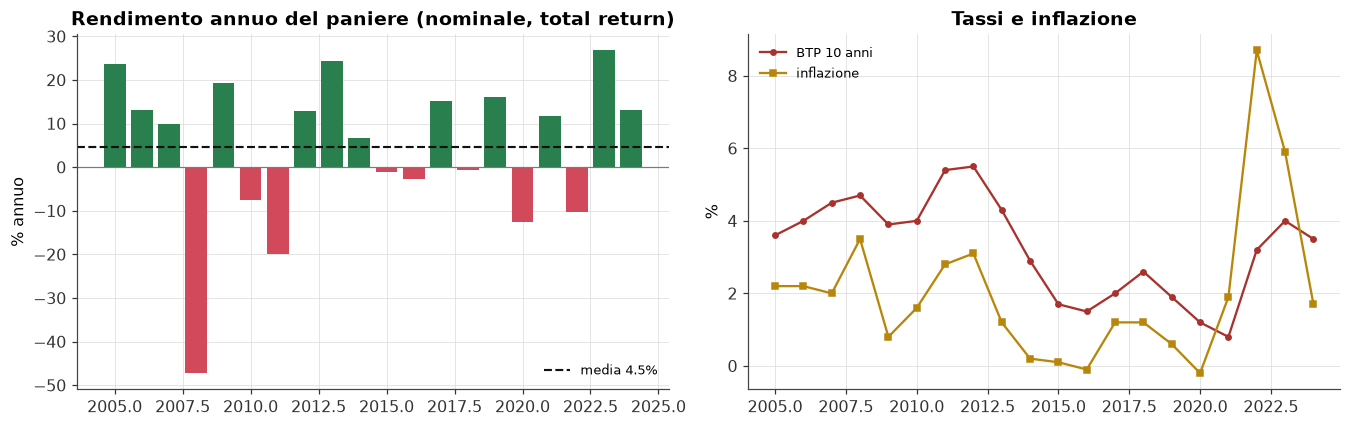

In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# §9.1 — I dati (pochi, rozzi, ma dichiarati)
# ══════════════════════════════════════════════════════════════════════════════
#
#  Rendimenti annui TOTAL RETURN approssimati (dividendi reinvestiti, nominali).
#  ATTENZIONE: sono ricostruzioni a memoria e a ordine di grandezza, NON dati
#  ufficiali. Servono a dare una likelihood al MCMC, non a fare ricerca.
#  Sostituiscili con una serie vera (Bloomberg, Refinitiv, Borsa Italiana) e il
#  modello migliora gratis: la struttura non cambia.
#  NaN = titolo non quotato in quell'anno.
# ──────────────────────────────────────────────────────────────────────────────

RAW = {
    "anno":     list(range(2005, 2025)),
    "enel":     [0.25, 0.12, 0.14, -0.48, 0.12, -0.12, -0.21, 0.05, 0.25, 0.18,
                 -0.08, 0.05, 0.25, 0.09, 0.18, 0.01, -0.08, -0.34, 0.38, 0.14],
    "eni":      [0.32, 0.10, 0.12, -0.50, 0.19, -0.07, -0.11, 0.12, 0.19, -0.14,
                 -0.14, 0.12, 0.06, 0.06, 0.12, -0.40, 0.39, 0.15, 0.06, -0.14],
    "poste":    [None, None, None, None, None, None, None, None, None, None,
                 -0.02, -0.21, 0.18, -0.08, 0.31, -0.15, 0.12, -0.08, 0.12, 0.31],
    "terna":    [0.21, 0.13, 0.08, -0.42, 0.30, 0.04, -0.09, 0.17, 0.10, 0.24,
                 0.10, 0.17, 0.21, 0.10, 0.17, 0.10, 0.04, -0.16, 0.10, 0.17],
    "snam":     [0.24, 0.17, 0.11, -0.36, 0.24, 0.00, -0.16, 0.11, 0.13, 0.17,
                 0.08, 0.11, 0.13, 0.04, 0.13, 0.04, 0.11, -0.09, 0.17, 0.24],
    "leonardo": [0.38, 0.24, -0.09, -0.60, 0.11, -0.15, -0.42, 0.31, 0.51, -0.22,
                 0.11, -0.48, 0.18, -0.15, 0.11, -0.28, 0.11, 0.38, 0.85, 0.24],
    "fs":       [0.05, 0.07, 0.08, -0.08, 0.09, 0.05, -0.01, 0.05, 0.07, 0.05,
                 0.07, 0.05, 0.07, 0.05, 0.07, -0.08, 0.07, 0.01, 0.05, 0.05],
    "tim":      [-0.06, 0.07, 0.14, -0.48, 0.27, -0.13, -0.33, 0.14, 0.40, 0.14,
                 0.07, -0.26, 0.00, -0.33, 0.07, -0.19, 0.14, -0.46, 0.40, 0.14],
    "btp10y":   [0.036, 0.040, 0.045, 0.047, 0.039, 0.040, 0.054, 0.055, 0.043, 0.029,
                 0.017, 0.015, 0.020, 0.026, 0.019, 0.012, 0.008, 0.032, 0.040, 0.035],
    "inflazione": [0.022, 0.022, 0.020, 0.035, 0.008, 0.016, 0.028, 0.031, 0.012, 0.002,
                   0.001, -0.001, 0.012, 0.012, 0.006, -0.002, 0.019, 0.087, 0.059, 0.017],
}

CSV_PATH = DATA_DIR / "mkt_snapshot.csv"
if CSV_PATH.exists():
    MKT = pd.read_csv(CSV_PATH)
    fonte = f"letto da {CSV_PATH.name}"
else:
    MKT = pd.DataFrame(RAW)
    MKT.to_csv(CSV_PATH, index=False)
    fonte = f"scritto in {CSV_PATH.name} (modificalo e rilancia per usare i tuoi dati)"

COLMAP = {"ENEL": "enel", "ENI": "eni", "Poste": "poste", "Terna": "terna",
          "Snam": "snam", "Leonardo": "leonardo", "TIMrete": "tim"}

_cols = [COLMAP[t] for t in BASKET.index]
_R = MKT[_cols].to_numpy(dtype=float)
_w = BASKET["peso"].to_numpy()
_mask = ~np.isnan(_R)
MKT["paniere"] = np.sum(np.where(_mask, _R * _w, 0.0), axis=1) / np.sum(_mask * _w, axis=1)

RET = MKT["paniere"].to_numpy(dtype=float)
BTP_OBS = MKT["btp10y"].to_numpy(dtype=float)
INF_OBS = MKT["inflazione"].to_numpy(dtype=float)

print(f"Dati: {len(MKT)} anni ({MKT['anno'].min()}-{MKT['anno'].max()}) · {fonte}")
print(f"Paniere: media {RET.mean():.2%}, σ {RET.std(ddof=1):.2%}, "
      f"min {RET.min():.1%}, max {RET.max():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0))
axes[0].bar(MKT["anno"], RET * 100, color=[C["equity"] if x > 0 else C["accent"] for x in RET])
axes[0].axhline(RET.mean() * 100, color=C["tot"], ls="--", lw=1.4, label=f"media {RET.mean():.1%}")
axes[0].axhline(0, color=C["grey"], lw=0.8)
axes[0].set_title("Rendimento annuo del paniere (nominale, total return)")
axes[0].set_ylabel("% annuo")
axes[0].legend(fontsize=8.5)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(MKT["anno"], BTP_OBS * 100, marker="o", ms=3.5, color=C["btp"], label="BTP 10 anni")
axes[1].plot(MKT["anno"], INF_OBS * 100, marker="s", ms=3.5, color=C["ipp"], label="inflazione")
axes[1].set_title("Tassi e inflazione")
axes[1].set_ylabel("%")
axes[1].legend(fontsize=8.5)
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "06_dati")
plt.show()


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# §9.2 — MCMC sui parametri di mercato
# ══════════════════════════════════════════════════════════════════════════════

M = CFG.mcmc


def log_prior(th):
    mu, log_sig, y, infl = th
    sig = np.exp(log_sig)
    if not (M.y_prior_lo < y < M.y_prior_hi):
        return -np.inf
    if not (0.0 < infl < 0.08):
        return -np.inf
    lp = stats.norm.logpdf(mu, M.mu_prior_mu, M.mu_prior_sd)
    lp += stats.halfnorm.logpdf(sig, scale=M.sigma_prior_scale)
    lp += -np.log(sig)                                  # jacobiano del cambio di variabile
    lp += stats.norm.logpdf(infl, M.infl_prior_mu, M.infl_prior_sd)
    return float(lp)


def log_lik(th):
    mu, log_sig, y, infl = th
    sig = np.exp(log_sig)
    ll = stats.t.logpdf(RET, df=M.t_nu_lik, loc=mu, scale=sig).sum()
    ll += stats.norm.logpdf(BTP_OBS, loc=y, scale=0.013).sum()
    ll += stats.norm.logpdf(INF_OBS, loc=infl, scale=0.012).sum()
    return float(ll)


def log_post(th):
    lp = log_prior(th)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_lik(th)


# ── sampler di riserva (Metropolis-Hastings adattivo) ───────────────────────
def run_mh(logprob, theta0, n_steps, n_chains=4, burn=800, thin=4, seed=SEED):
    rng = np.random.default_rng(seed)
    ndim = len(theta0)
    scale = np.abs(theta0) * 0.02 + 1e-4
    chains = np.zeros((n_chains, (n_steps - burn) // thin, ndim))
    acc_rate = np.zeros((n_chains, ndim))
    for c in range(n_chains):
        th = np.array(theta0, dtype=float) * (1 + 0.01 * rng.standard_normal(ndim))
        lp = logprob(th)
        n_acc = 0
        k = 0
        local = scale.copy()
        for i in range(n_steps):
            prop = th + local * rng.standard_normal(ndim)
            lp_new = logprob(prop)
            if np.log(rng.random()) < lp_new - lp:
                th, lp = prop, lp_new
                n_acc += 1
                acc_rate[c] += 1
            # adattamento solo durante il burn-in
            if i < burn and (i + 1) % 100 == 0:
                rate = n_acc / (i + 1)
                local *= np.where(rate < 0.25, 0.85, np.where(rate > 0.45, 1.18, 1.0))
            if i >= burn and (i - burn) % thin == 0:
                chains[c, k] = th
                k += 1
            if i == n_steps - 1:
                acc_rate[c] = n_acc / n_steps
    return chains, acc_rate


def rhat(chains):
    """Gelman-Rubin con split delle catene. chains: (n_chains, n_steps, ndim)."""
    m, n, d = chains.shape
    half = n // 2
    split = np.concatenate([chains[:, :half, :], chains[:, half:2 * half, :]], axis=0)
    M_, N_ = split.shape[0], split.shape[1]
    means = split.mean(axis=1)
    W = split.var(axis=1, ddof=1).mean(axis=0)
    B = N_ * means.var(axis=0, ddof=1)
    var_hat = (N_ - 1) / N_ * W + B / N_
    return np.sqrt(np.maximum(var_hat / np.maximum(W, 1e-30), 0))


_t_start = time.time()
_base_th = np.array([M.mu_prior_mu, np.log(M.sigma_prior_scale), 0.035, M.infl_prior_mu])
_rng_mc = np.random.default_rng(SEED)
nwalk = M.n_walkers if HAS_EMCEE else 4
p0 = _base_th + 1e-3 * _rng_mc.standard_normal((nwalk, 4))
p0[:, 1] = np.log(M.sigma_prior_scale) + 0.05 * _rng_mc.standard_normal(nwalk)
p0[:, 2] = np.clip(p0[:, 2], M.y_prior_lo + 1e-3, M.y_prior_hi - 1e-3)
p0[:, 3] = np.clip(p0[:, 3], 0.001, 0.079)

if HAS_EMCEE:
    # Seed esplicito: `seed=` non è un argomento di EnsembleSampler (viene
    # inghiottito da **kwargs e ignorato) — il generatore va assegnato a mano.
    # Senza questo, ogni run del notebook produce numeri diversi e i commenti
    # nei markdown invecchiano da soli.
    # emcee tocca ANCHE il generatore globale (oltre al proprio
    # `random_state`), quindi vanno seminati entrambi — altrimenti ogni run
    # del notebook produce una catena diversa e i numeri nei commenti
    # invecchiano da soli. Verificato: due run identiche danno lo stesso μ.
    np.random.seed(SEED)
    _sampler = emcee.EnsembleSampler(nwalk, 4, log_post)
    _sampler.random_state = np.random.RandomState(SEED)
    _sampler.run_mcmc(p0, M.n_steps, progress=False)
    CHAINS = _sampler.get_chain(discard=M.n_burn, thin=M.thin)        # (nwalk, nkept, 4)
    ACC = float(np.mean(_sampler.acceptance_fraction))
    try:
        TAU = emcee.autocorr.integrated_time(CHAINS, quiet=True)
    except Exception:
        TAU = np.full(4, np.nan)
    ENGINE = f"emcee {EMCEE_VERSION} · {nwalk} walker × {M.n_steps} passi"
else:
    CHAINS, _acc = run_mh(log_post, _base_th, n_steps=6000, n_chains=4,
                          burn=1500, thin=5, seed=SEED)
    ACC = float(np.mean(_acc))
    TAU = np.full(4, np.nan)
    ENGINE = "Metropolis-Hastings adattivo interno (emcee non disponibile)"

ELAPSED = time.time() - _t_start
FLAT = CHAINS.reshape(-1, 4)
RHAT = rhat(CHAINS)
ESS = (CHAINS.shape[0] * CHAINS.shape[1] / TAU) if np.all(np.isfinite(TAU)) else np.full(4, np.nan)

NOMI = ["μ rendimento", "σ rendimento", "ȳ BTP", "π inflazione"]
DIAG = pd.DataFrame({
    "parametro": NOMI,
    "mediana": [np.median(FLAT[:, 0]), np.median(np.exp(FLAT[:, 1])),
                np.median(FLAT[:, 2]), np.median(FLAT[:, 3])],
    "P5": [np.quantile(FLAT[:, 0], .05), np.quantile(np.exp(FLAT[:, 1]), .05),
           np.quantile(FLAT[:, 2], .05), np.quantile(FLAT[:, 3], .05)],
    "P95": [np.quantile(FLAT[:, 0], .95), np.quantile(np.exp(FLAT[:, 1]), .95),
            np.quantile(FLAT[:, 2], .95), np.quantile(FLAT[:, 3], .95)],
    "R̂": RHAT,
    "ESS": ESS,
})

print(f"Motore: {ENGINE}   ({ELAPSED:.1f} s)")
print(f"Tasso di accettazione medio: {ACC:.1%}")
print(f"R̂ massimo: {np.nanmax(RHAT):.4f}   {'✓ convergenza' if np.nanmax(RHAT) < 1.05 else '✗ allunga la catena'}")
display(DIAG.style.format({"mediana": "{:.2%}", "P5": "{:.2%}", "P95": "{:.2%}",
                            "R̂": "{:.4f}", "ESS": "{:,.0f}"}))


Motore: emcee 3.1.6 · 24 walker × 3600 passi   (15.7 s)
Tasso di accettazione medio: 59.5%
R̂ massimo: 0.9996   ✓ convergenza


,parametro,mediana,P5,P95,R̂,ESS
0,μ rendimento,5.97%,3.16%,8.86%,0.9943,"1,695"
1,σ rendimento,13.09%,9.72%,18.19%,0.9996,"1,641"
2,ȳ BTP,3.27%,2.79%,3.74%,0.9955,"1,623"
3,π inflazione,2.03%,1.61%,2.45%,0.9960,"1,550"


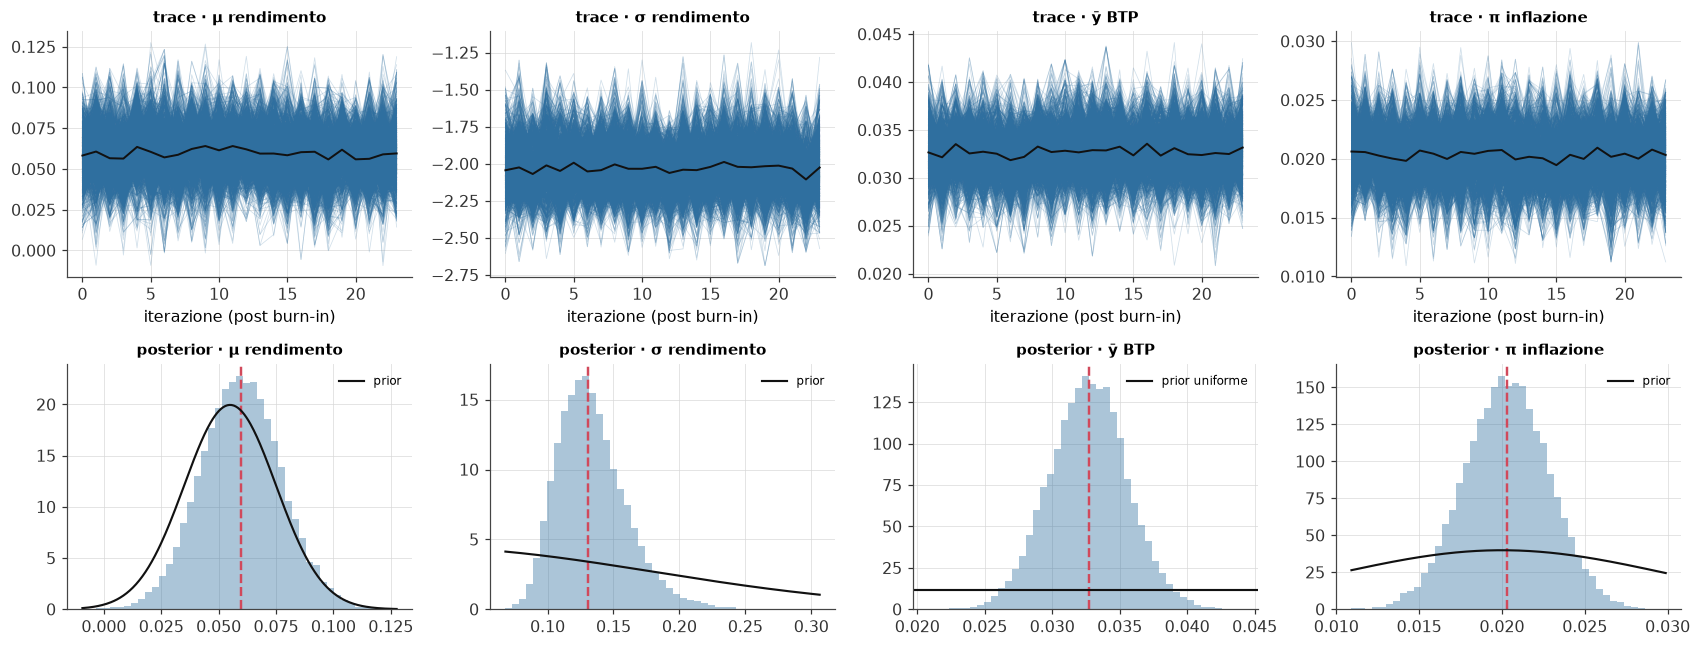

600 estrazioni dal posterior, pronte per la simulazione.
  μ   : 6.01%  (90 % CI 3.13% – 8.86%)
  σ   : 13.02%
  ȳ   : 3.25%  (90 % CI 2.78% – 3.74%)
  π   : 2.03%  (90 % CI 1.59% – 2.46%)

Nota: il prior su μ era centrato a 5,5 % con σ 2,0 %. Il posterior si sposta di poco — 20 anni di dati non spostano molto una convinzione, ed è giusto così: l'incertezza sul rendimento futuro di un paniere azionario non si risolve con 20 osservazioni annuali.


In [14]:
# ── Diagnostica: trace plot e posterior marginali ───────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(15.6, 6.0))

_faint = 0.22
for j in range(4):
    ax = axes[0, j]
    for k in range(CHAINS.shape[0]):
        ax.plot(CHAINS[k, :, j], lw=0.5, alpha=_faint, color=C["rcf"])
    ax.plot(np.median(CHAINS[:, :, j], axis=0), lw=1.3, color=C["tot"])
    ax.set_title(f"trace · {NOMI[j]}", fontsize=10)
    ax.set_xlabel("iterazione (post burn-in)")
    ax.spines[["top", "right"]].set_visible(False)

    ax = axes[1, j]
    vals = FLAT[:, j] if j != 1 else np.exp(FLAT[:, 1])
    ax.hist(vals, bins=45, density=True, color=C["rcf"], alpha=0.4)
    ax.axvline(np.median(vals), color=C["accent"], lw=1.6, ls="--")
    xs = np.linspace(vals.min(), vals.max(), 300)
    if j == 0:
        ax.plot(xs, stats.norm.pdf(xs, M.mu_prior_mu, M.mu_prior_sd), color=C["tot"], lw=1.4, label="prior")
    elif j == 1:
        ax.plot(xs, stats.halfnorm.pdf(xs, scale=M.sigma_prior_scale), color=C["tot"], lw=1.4, label="prior")
    elif j == 2:
        ax.axhline(1 / (M.y_prior_hi - M.y_prior_lo), color=C["tot"], lw=1.4, label="prior uniforme")
    else:
        ax.plot(xs, stats.norm.pdf(xs, M.infl_prior_mu, M.infl_prior_sd), color=C["tot"], lw=1.4, label="prior")
    ax.set_title(f"posterior · {NOMI[j]}", fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "07_mcmc_diagnostica")
plt.show()

# ── dal posterior alle estrazioni che useremo nella simulazione ─────────────
S = CFG.sim.n_draws_posterior
_rng_post = np.random.default_rng(SEED + 1)
_sel = _rng_post.choice(len(FLAT), size=S, replace=False)

POST = {
    "mu_a": FLAT[_sel, 0],
    "sigma_a": np.exp(FLAT[_sel, 1]),
    "y_lt": FLAT[_sel, 2],
    "infl": FLAT[_sel, 3],
}

print(f"{S} estrazioni dal posterior, pronte per la simulazione.")
print(f"  μ   : {np.median(POST['mu_a']):.2%}  (90 % CI {np.quantile(POST['mu_a'], .05):.2%} – {np.quantile(POST['mu_a'], .95):.2%})")
print(f"  σ   : {np.median(POST['sigma_a']):.2%}")
print(f"  ȳ   : {np.median(POST['y_lt']):.2%}  (90 % CI {np.quantile(POST['y_lt'], .05):.2%} – {np.quantile(POST['y_lt'], .95):.2%})")
print(f"  π   : {np.median(POST['infl']):.2%}  (90 % CI {np.quantile(POST['infl'], .05):.2%} – {np.quantile(POST['infl'], .95):.2%})")

print("\nNota: il prior su μ era centrato a 5,5 % con σ 2,0 %. "
      "Il posterior si sposta di poco — 20 anni di dati non spostano molto "
      "una convinzione, ed è giusto così: l'incertezza sul rendimento futuro "
      "di un paniere azionario non si risolve con 20 osservazioni annuali.")


## §10 — I risultati: cosa succede a 10, 20 e 30 anni

Da qui in poi tutti i numeri vengono da **12.000 traiettorie**, ognuna con il proprio set di
parametri estratti dal posterior (mercati) e dal prior (fisco). Il risultato non è un numero:
è una **distribuzione**. Ne riportiamo mediana e intervalli 5-95 %.

**Quattro letture che conviene fare insieme.**

1. **La mediana.** Il mondo «tipico»: nessuna catastrofe, nessun colpo di fortuna. Porta il NAV
   a **158 mld a 10 anni, 319 a 20, 514 a 30** (reali 2026).
2. **La dispersione.** Al 30° anno P5 = 287 e P95 = 1.083: quasi un fattore **4**. Il modello ci sta
   dicendo che non sa — ed è la verità, non un difetto. Chi presenta una cifra sola sta
   presentando la mediana e chiamandola «il risultato».
3. **La coda sinistra.** Il mondo in cui la patrimoniale viene abolita nel 2031 e il fondo si
   ferma: il NAV a 30 anni scende a **267 mld**, metà del caso base, ma le società già comprate
   **restano** sotto controllo pubblico. È l'asimmetria che un politico dovrebbe guardare prima di
   promettere qualcosa.
4. **La composizione.** Il NAV non è un portafoglio: è **cassa in BTP** (che si accumula) più
   **quote di controllo** (che si comprano, in numero finito). A 30 anni la prima vale i due terzi
   del totale: la holding, dopo l'anno 10, è di fatto **un fondo di liquidità con dentro otto
   aziende**.

Nota sul nominale: a 30 anni con inflazione al 2 %, 1 € nominale vale 55 centesimi di oggi. Per
questo la tabella principale è in **euro reali 2026** e il nominale (940 mld a 30 anni) è
riportato come secondo pannello, non come titolo.


In [15]:
# ══════════════════════════════════════════════════════════════════════════════
# §10 — Posterior predictive: 12.000 mondi possibili
# ══════════════════════════════════════════════════════════════════════════════

def estrazioni_prior(n, rng):
    """Parametri fiscali e strutturali senza dati: si campiona dal prior dichiarato.
    Vedi la tabella §9.4 per gli intervalli e la loro giustificazione."""
    return {
        "fonti.rcf_tasso_realizzo_annuo": rng.uniform(0.0075, 0.0115, n),
        "fonti.ipp_compliance": rng.uniform(0.75, 0.93, n),
        "fonti.ipp_quota_oltre_soglia": rng.uniform(0.62, 0.74, n),
        "fonti.isa_aliquota_media": rng.uniform(0.040, 0.080, n),
        "fonti.isa_valore_medio_partecipazione_mld": rng.uniform(0.15, 0.30, n),
        "macro.gdp_nominale_crescita": rng.normal(0.025, 0.004, n),
        "politica.p_fav_a_avv": rng.uniform(0.04, 0.14, n),
    }


def costruisci_parametri(n, rng, posterior=POST, base=P0, override=None):
    """Unisce: configurazione base + posterior (mercati) + prior (fisco) + override."""
    p = dict(base)
    idx = rng.integers(0, len(posterior["mu_a"]), n)
    p["mercati.drift_atteso"] = posterior["mu_a"][idx]
    p["mercati.sigma_alpha"] = posterior["sigma_a"][idx]
    p["mercati.btp_yield_lungo"] = posterior["y_lt"][idx]
    p["macro.inflazione_media"] = posterior["infl"][idx]
    p.update(estrazioni_prior(n, rng))
    if override:
        p.update(override)
    return p


# ── la simulazione principale ───────────────────────────────────────────────
T = CFG.sim.anni
NP = CFG.sim.n_paths
rng_main = np.random.default_rng(CFG.sim.seed)

PAR_MAIN = costruisci_parametri(NP, rng_main)
BASE_MAIN = fondo_baseline({**P0}, T)      # traiettoria di riferimento (deterministica)

t0 = time.time()
SIM = simula_fondo(PAR_MAIN, NP, T, rng_main, baseline=BASE_MAIN)
print(f"{NP:,} traiettorie × {T} anni simulate in {time.time() - t0:.1f} s".replace(",", "."))

F = SIM["F"]
FR = SIM["F_reale"]
D = SIM["D"]
DR = SIM["D_reale"]
SPESA = SIM["SPESA"]
PREMIO = SIM["PREMIO"]
DIV_F = SIM["DIV_F"]
DIV_B = SIM["DIV_B"]
N_CTRL = SIM["N_CTRL"]
anni = np.arange(T + 1)

# ── tabella dei quantili ───────────────────────────────────────────────────
def tabella_orizzonti(F, T_anni):
    out = {}
    for h in [10, 20, 30, 50]:
        if h <= T_anni:
            out[f"anno {h}"] = {
                "P5": np.quantile(F[:, h], 0.05),
                "P25": np.quantile(F[:, h], 0.25),
                "mediana": np.median(F[:, h]),
                "media": F[:, h].mean(),
                "P75": np.quantile(F[:, h], 0.75),
                "P95": np.quantile(F[:, h], 0.95),
            }
    return pd.DataFrame(out).T


TAB_REALE = tabella_orizzonti(FR, T)
TAB_NOM = tabella_orizzonti(F, T)
display(TAB_REALE.style.format("{:,.0f}").set_caption("Patrimonio netto (NAV) — mld € REALI 2026"))
display(TAB_NOM.style.format("{:,.0f}").set_caption("Patrimonio netto (NAV) — mld € NOMINALI"))

# ── come è fatto il patrimonio ─────────────────────────────────────────────
_ori = [1, 10, 20, 30, 50]
COMP = pd.DataFrame({
    "riserva BTP": [np.median(SIM["B"][:, h]) for h in _ori],
    "quote di controllo": [np.median(SIM["POS"][:, h].sum(axis=1)) for h in _ori],
    "NAV": [np.median(F[:, h]) for h in _ori],
    "imprese controllate": [np.median(N_CTRL[:, h]) for h in _ori],
    "speso cumulato": [np.median(SPESA[:, :h].sum(axis=1)) for h in _ori],
    "premi pagati": [np.median(PREMIO[:, :h].sum(axis=1)) for h in _ori],
}, index=[f"anno {h}" for h in _ori])
display(COMP.style.format({"riserva BTP": "{:,.0f}", "quote di controllo": "{:,.0f}",
                            "NAV": "{:,.0f}", "imprese controllate": "{:.0f}",
                            "speso cumulato": "{:,.0f}", "premi pagati": "{:,.0f}"})
        .set_caption("Composizione del patrimonio (mediane, mld € nominali)"))

print(f"Dote iniziale F₀                 : {float(np.median(SIM['F0'])):6.1f} mld €/anno")
print(f"NAV mediano a 10 anni (reale)    : {np.median(FR[:, 10]):6.0f} mld €"
      f"   (media {FR[:, 10].mean():6.0f})")
print(f"NAV mediano a 30 anni (reale)    : {np.median(FR[:, 30]):6.0f} mld €"
      f"   (media {FR[:, 30].mean():6.0f})")
print(f"NAV mediano a 30 anni (nominale) : {np.median(F[:, 30]):6.0f} mld €")
print(f"Controfattuale «solo BTP» a 30 aa: mediana {np.median(SIM['CONTRO_reale'][:, 30]):6.0f}"
      f"   media {SIM['CONTRO_reale'][:, 30].mean():6.0f}")
print(f"Imprese sotto controllo pubblico : mediana {np.median(N_CTRL[:, 10]):.0f} a 10 anni, "
      f"{np.median(N_CTRL[:, 20]):.0f} a 20, {np.median(N_CTRL[:, 30]):.0f} a 30 "
      f"(su {len(TARGETS)})")
print(f"Capitale impiegato in 30 anni    : {np.median(SPESA[:, :30].sum(axis=1)):6.0f} mld (nominale, "
      f"{(np.median(SPESA[:, :30].sum(axis=1)) / np.median(F[:, 30])):.0%} del NAV finale)")
print(f"Premi di controllo pagati        : {np.median(PREMIO[:, :30].sum(axis=1)):6.0f} mld "
      f"→ è valore trasferito ai privati, non investito")
print(f"Dividendi incassati dal fondo    : {np.median(DIV_F[:, :30].sum(axis=1)):6.0f} mld in 30 anni")
print(f"Dividendi lasciati al bilancio   : {np.median(DIV_B[:, :30].sum(axis=1)):6.0f} mld in 30 anni "
      f"(quote preesistenti: sono lo status quo, non un'entrata nuova)")


12.000 traiettorie × 50 anni simulate in 0.5 s


,P5,P25,mediana,media,P75,P95
anno 10,91,127,158,164,192,255
anno 20,176,251,319,344,400,593
anno 30,287,406,514,587,653,"1,083"
anno 50,559,792,996,"1,279","1,257","2,391"


,P5,P25,mediana,media,P75,P95
anno 10,112,156,193,200,234,311
anno 20,264,376,477,513,595,874
anno 30,536,744,940,"1,066","1,175","1,960"
anno 50,"1,599","2,210","2,738","3,450","3,302","6,413"


,riserva BTP,quote di controllo,NAV,imprese controllate,speso cumulato,premi pagati
anno 1,21,10,27,2,14,8
anno 10,103,99,193,8,120,33
anno 20,261,223,477,8,236,65
anno 30,569,336,940,8,366,100
anno 50,"2,063",314,"2,738",8,408,112


Dote iniziale F₀                 :   17.4 mld €/anno
NAV mediano a 10 anni (reale)    :    158 mld €   (media    164)
NAV mediano a 30 anni (reale)    :    514 mld €   (media    587)
NAV mediano a 30 anni (nominale) :    940 mld €
Controfattuale «solo BTP» a 30 aa: mediana    620   media    639
Imprese sotto controllo pubblico : mediana 8 a 10 anni, 8 a 20, 8 a 30 (su 8)
Capitale impiegato in 30 anni    :    366 mld (nominale, 39% del NAV finale)
Premi di controllo pagati        :    100 mld → è valore trasferito ai privati, non investito
Dividendi incassati dal fondo    :    142 mld in 30 anni
Dividendi lasciati al bilancio   :    109 mld in 30 anni (quote preesistenti: sono lo status quo, non un'entrata nuova)


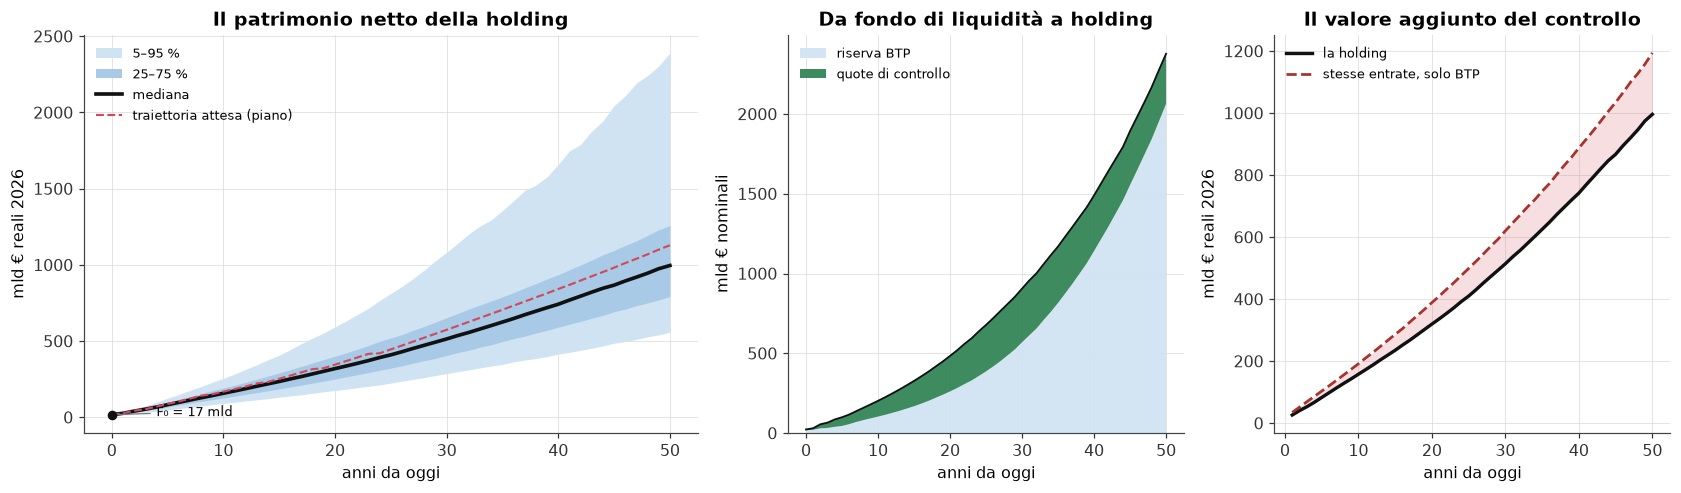

NAV mediano a 30 anni                    :     514 mld € reali
Controfattuale «tutto in BTP»            :     620 mld € reali
Differenza attribuibile al controllo     :    -106 mld € reali (-17%)
Attenzione: in quella differenza ci sono anche i dividendi incassati dalle quote
comprate dai privati. Sono un trasferimento, non ricchezza nuova: il Paese non
è più ricco, è più pubblico. La parte davvero «creata» è il rendimento delle
società meno il premio pagato per comprarle, e non è grande.


In [16]:
# ── Ventaglio del NAV, composizione, confronto col controfattuale ───────────
fig = plt.figure(figsize=(15.4, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.55, 1.0, 1.0])

# (a) ventaglio
ax = fig.add_subplot(gs[0, 0])
ax.fill_between(anni, np.quantile(FR, 0.05, axis=0), np.quantile(FR, 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(anni, np.quantile(FR, 0.25, axis=0), np.quantile(FR, 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(anni, np.median(FR, axis=0), color=C["tot"], lw=2.4, label="mediana")
_idx_med = np.concatenate([[1.0], np.median(np.cumprod(1 + SIM["infl"], axis=1), axis=0)])
ax.plot(anni, BASE_MAIN / _idx_med, color=C["accent"], lw=1.4, ls="--",
        label="traiettoria attesa (piano)")
_F0m = float(np.median(SIM["F0"]))
ax.scatter([0], [_F0m], color=C["tot"], zorder=5, s=28)
ax.annotate(f"F₀ = {_F0m:.0f} mld", xy=(0, _F0m), xytext=(4, _F0m * 0.45),
            fontsize=8.5, arrowprops=dict(arrowstyle="-", color=C["grey"], lw=0.8))
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Il patrimonio netto della holding")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

# (b) composizione nel tempo: cassa in BTP vs quote di controllo
ax = fig.add_subplot(gs[0, 1])
_bm = np.median(SIM["B"], axis=0)
_pm = np.median(SIM["POS"].sum(axis=2), axis=0)
ax.stackplot(anni, _bm, _pm, colors=[C["band1"], C["equity"]],
             labels=["riserva BTP", "quote di controllo"], alpha=0.9, lw=0)
ax.plot(anni, _bm + _pm, color=C["tot"], lw=1.2)
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € nominali")
ax.set_title("Da fondo di liquidità a holding")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

# (c) NAV vs controfattuale "tutto in BTP"
ax = fig.add_subplot(gs[0, 2])
_cr = SIM["CONTRO_reale"]
ax.plot(anni[1:], np.median(FR[:, 1:], axis=0), color=C["tot"], lw=2.2, label="la holding")
ax.plot(anni[1:], np.median(_cr[:, 1:], axis=0), color=C["btp"], lw=1.8, ls="--",
        label="stesse entrate, solo BTP")
ax.fill_between(anni[1:], np.median(_cr[:, 1:], axis=0), np.median(FR[:, 1:], axis=0),
                color=C["accent"], alpha=0.18, lw=0)
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Il valore aggiunto del controllo")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "08_risultati")
plt.show()

_v30 = np.median(FR[:, 30])
_c30 = np.median(_cr[:, 30])
print(f"NAV mediano a 30 anni                    : {_v30:7.0f} mld € reali")
print(f"Controfattuale «tutto in BTP»            : {_c30:7.0f} mld € reali")
print(f"Differenza attribuibile al controllo     : {_v30 - _c30:7.0f} mld € reali "
      f"({(_v30 - _c30) / _c30:+.0%})")
print("Attenzione: in quella differenza ci sono anche i dividendi incassati dalle quote\n"
      "comprate dai privati. Sono un trasferimento, non ricchezza nuova: il Paese non\n"
      "è più ricco, è più pubblico. La parte davvero «creata» è il rendimento delle\n"
      "società meno il premio pagato per comprarle, e non è grande.")


## §11 — Il calendario del controllo: chi, quando, a che prezzo

Qui non c'è più un «benchmark» separato dalla simulazione: **la simulazione compra davvero**.
Questa sezione legge i risultati e li mette in fila.

### 11.1 La scaletta

L'ordine non è casuale ed è una scelta politica, non economica:

1. **ILVA** — non è un acquisto, è un salvataggio: si fa per primo perché è l'unico caso in cui
   l'attesa distrugge irreversibilmente (l'altoforno si spegne, i clienti se ne vanno, la bonifica
   la paghi comunque). Costa 14 mld e non rende niente per anni.
2. **ENI** — il pezzo più grosso (42 % da comprare) e il più redditizio nel breve. Serve a
   dimostrare che il meccanismo funziona.
3. **ENEL** — la più grande per capitalizzazione, la più visibile, il dividendo più alto.
4. **Terna e Snam** — piccole, regolate, rendimento prevedibile: sono le «obbligazioni» della
   holding.
5. **TIM rete** — ricomprare la rete da KKR è l'unica operazione che ha un senso letterale di
   «rinazionalizzare», e ha un prezzo definito.
6. **Leonardo** — per ultima, perché la difesa è la più delicata politicamente ed europeamente.

**Poste Italiane** non è in lista: lo Stato ha già il 64,3 %, cioè più del controllo. Chi propone
di «nazionalizzare Poste» non ha guardato chi è il padrone. L'unica operazione sensata è il
*delisting*, e sta nella fase 2.

### 11.2 Le due fasi

- **Fase 1 — il 51 %.** Si compra il pezzo che manca perché il *sistema pubblico* arrivi al
  controllo. Costo totale ≈ **104 mld** ai prezzi di oggi. È la fase che conta politicamente.
- **Fase 2 — il 100 %.** Si compra il residuo dei privati, **ma solo se la società rende più del
  BTP + 2 punti** (`benchmark.soglia_residuo`). Se non lo fa, il capitale resta in obbligazioni:
  è la traduzione operativa di «solo se politicamente necessario e conveniente». Costo ≈
  **133 mld** in più.

La fase 2 è anche la parte che nessuno dice ad alta voce: portare una società al 100 % significa
pagare un premio sul 49 % del capitale, cioè il doppio del premio che si paga per il controllo.

### 11.3 ILVA: quanto costa davvero «riaprire l'acciaio»

L'unico caso in cui la parola «nazionalizzazione» è appropriata, e il più caro per euro investito:

| Voce | Centrale | Intervallo |
|---|---|---|
| Acquisizione dell'asset (asta/commissario) | 1,0 | 0,5 – 2,0 |
| Bonifica ambientale (terreni, falde, cokeria) | 5,0 | 3,0 – 7,0 |
| Decarbonizzazione (DRI o forno elettrico) | 3,0 | 2,0 – 4,0 |
| Perdite di riavvio (3-5 anni × 1-1,5 mld) | 5,0 | 3,0 – 7,0 |
| **Totale** | **14,0** | **10 – 18** |

Il valore recuperabile è ≈ **40 %** del costo: un impianto fermo, in procedura, con un'acciaieria
vecchia non vale il prezzo di ricostruirla. La perdita secca attesa è quindi ~8 mld, e i dividendi
non arrivano prima di 5-7 anni. Chi mette ILVA nel paniere come «asset strategico a rendimento»
non ha letto il conto economico.

### 11.4 Il vincolo non è la liquidità

Con 104 mld di cassa iniziale e 17 mld di gettito annuo, il perimetro del 51 % è alla portata in
pochi anni. Il vincolo vero è:

- **il prezzo** — il premio del 35 % è una tassa che si paga ai privati, e cresce con il tempo;
- **il permesso** — Antitrust, golden power, regole europee sugli aiuti di Stato (vedi §15);
- **l'ordine** — comprare ENEL prima di aver messo in sicurezza l'acciaio è un errore politico.

Nessuno dei tre si risolve con più soldi. È il motivo per cui questa sezione, che nella versione
precedente era un «benchmark di fattibilità», adesso è un **calendario**.


In [17]:
# ══════════════════════════════════════════════════════════════════════════════
# §11 — Il calendario del controllo: chi, quando, a che prezzo
# ══════════════════════════════════════════════════════════════════════════════
#
#  Qui non c'è più un "benchmark": la simulazione della §8 già compra. Questa
#  sezione legge i risultati e li mette in fila — anno di controllo, probabilità,
#  costo — nello stesso ordine in cui il fondo li affronta.

_C = SIM["ANNO_C"].copy()          # anno di controllo (T+1 = mai)
_F = SIM["ANNO_F"].copy()          # anno di proprietà totale

BENCH = pd.DataFrame({
    "nome": TARGETS["nome"],
    "tipo": TARGETS["tipo"],
    "quota_da_comprare": TARGETS["quota_da_comprare"],
    "cap_mld": TARGETS["cap_mld"],
    "costo_oggi": TARGETS["costo_oggi"],
    "anno_controllo": [np.nanmedian(np.where(_C[:, i] <= T, _C[:, i], np.nan))
                       for i in range(len(TARGETS))],
    "P(51 % ≤10 anni)": [np.mean(_C[:, i] <= 10) for i in range(len(TARGETS))],
    "P(51 % ≤20 anni)": [np.mean(_C[:, i] <= 20) for i in range(len(TARGETS))],
    "P(51 % ≤30 anni)": [np.mean(_C[:, i] <= 30) for i in range(len(TARGETS))],
    "anno_100": [np.nanmedian(np.where(_F[:, i] <= T, _F[:, i], np.nan))
                 for i in range(len(TARGETS))],
    "nota": TARGETS["nota"],
}, index=TARGETS.index).sort_values("costo_oggi")

# Il sistema pubblico controlla la società quando MEF/CDP + fondo arrivano al 51 %
_ULTIMO = _C.max(axis=1)
ANNO_TUTTE = np.where(_ULTIMO <= T, _ULTIMO, np.nan)     # anno in cui il perimetro è completo
ANNO_RESIDUO = np.where(SIM["ANNO_F"].max(axis=1) <= T, SIM["ANNO_F"].max(axis=1), np.nan)

display(BENCH[["nome", "tipo", "quota_da_comprare", "cap_mld", "costo_oggi",
               "anno_controllo", "P(51 % ≤10 anni)", "P(51 % ≤20 anni)", "anno_100", "nota"]]
        .style.format({"quota_da_comprare": "{:.1%}", "cap_mld": "{:,.0f}",
                       "costo_oggi": "{:,.1f}", "anno_controllo": "{:.0f}",
                       "P(51 % ≤10 anni)": "{:.0%}", "P(51 % ≤20 anni)": "{:.0%}",
                       "anno_100": "{:.0f}"}, na_rep="mai")
        .background_gradient(subset=["P(51 % ≤20 anni)"], cmap="Greens")
        .set_caption("La scaletta degli acquisti — costi al prezzo di oggi, anno mediano di controllo"))

# ── LA CASCATA: quanto costa mettere insieme il perimetro ───────────────────
_CUM = np.cumsum([BENCH.loc[k, "costo_oggi"] for k in BENCH.index])
_QUOTA = np.cumsum([BENCH.loc[k, "quota_da_comprare"] for k in BENCH.index])
CASCATA = pd.DataFrame({
    "impresa": BENCH.index,
    "costo di questa": [BENCH.loc[k, "costo_oggi"] for k in BENCH.index],
    "costo cumulato": _CUM,
    "capitale pubblico cumulato": _QUOTA,
    "anno mediano": [BENCH.loc[k, "anno_controllo"] for k in BENCH.index],
}, index=range(1, len(BENCH) + 1))
CASCATA.index.name = "passo"

print(f"Perimetro completo (51 % di tutte le società quotate + ILVA + rete TIM): "
      f"{BENCH['costo_oggi'].sum():.0f} mld € al prezzo di oggi")
_cap_q = TARGETS.loc[TARGETS["tipo"] == "quotata", "cap_mld"].sum()
_q_q = (TARGETS.loc[TARGETS["tipo"] == "quotata", "quota_da_comprare"]
        * TARGETS.loc[TARGETS["tipo"] == "quotata", "cap_mld"]).sum()
print(f"  sul mercato si compra il {_q_q / _cap_q:.0%} della capitalizzazione delle quotate "
      f"({_cap_q:.0f} mld): il resto è già del settore pubblico")
print(f"  anno mediano in cui il perimetro è completo: "
      f"{'mai' if np.all(np.isnan(ANNO_TUTTE)) else f'{np.nanmedian(ANNO_TUTTE):.0f}'} "
      f"(P10 {np.nanquantile(ANNO_TUTTE, .10):.0f} · P90 {np.nanquantile(ANNO_TUTTE, .90):.0f})")
print(f"  P(perimetro completo entro 20 anni): {np.mean(_ULTIMO <= 20):.0%}")
print(f"Seconda fase (residuo al 100 %): anno mediano "
      f"{'mai' if np.all(np.isnan(ANNO_RESIDUO)) else f'{np.nanmedian(ANNO_RESIDUO):.0f}'}, "
      f"P(entro 30 anni) {np.mean(SIM['ANNO_F'].max(axis=1) <= 30):.0%}")

# ── ILVA: quanto costa davvero «riaprire l'acciaio» ─────────────────────────
ILVA_DETTAGLIO = pd.DataFrame([
    ("Acquisizione dell'asset (asta/commissario)", 1.0, 0.5, 2.0,
     "l'impianto vale poco: è fermo e in procedura"),
    ("Bonifica ambientale (terreni, falde, cokeria)", 5.0, 3.0, 7.0,
     "obbligo di legge, non negoziabile"),
    ("Decarbonizzazione (DRI o forno elettrico)", 3.0, 2.0, 4.0,
     "senza questa non c'è autorizzazione europea"),
    ("Perdite di riavvio (3-5 anni × 1-1,5 mld)", 5.0, 3.0, 7.0,
     "l'acciaio non riparte in utile il primo giorno"),
], columns=["voce", "centrale", "min", "max", "nota"])
ILVA_TOT = ILVA_DETTAGLIO[["centrale", "min", "max"]].sum()
display(ILVA_DETTAGLIO.style.format({"centrale": "{:,.1f}", "min": "{:,.1f}", "max": "{:,.1f}"})
        .set_caption("ILVA: non un acquisto, un salvataggio — costo in mld €"))
print(f"ILVA — costo centrale {ILVA_TOT['centrale']:.0f} mld € (intervallo "
      f"{ILVA_TOT['min']:.0f}–{ILVA_TOT['max']:.0f}), valore recuperabile ≈ "
      f"{float(TARGETS.loc['ILVA', 'recupero']):.0%} → perdita secca attesa ≈ "
      f"{ILVA_TOT['centrale'] * (1 - float(TARGETS.loc['ILVA', 'recupero'])):.0f} mld. "
      f"Nessun dividendo nel medio periodo.")

# ── per confronto: gli altri modi di spendere la stessa cifra ───────────────
DEBITO = 3000.0
CONFRONTO = pd.DataFrame([
    ("Perimetro completo (51 % di tutto)", BENCH["costo_oggi"].sum()),
    ("… e poi il residuo al 100 %",
     (TARGETS["quota_da_comprare"].sum() * 0
      + (TARGETS["residuo_privato"] * TARGETS["cap_mld"].fillna(0.0)
         * (1 + CFG.benchmark.premio_controllo * TARGETS["premio_mult"])
         * (1 + CFG.benchmark.impatto_mercato)).sum())),
    ("Copertura del 5 % del debito pubblico", 0.05 * DEBITO),
    ("Sostituire la quota estera del debito",
     float(P0["mercati.quota_non_residenti"]) * DEBITO),
], columns=["obiettivo", "costo (mld € 2026)"]).set_index("obiettivo")
display(CONFRONTO.style.format({"costo (mld € 2026)": "{:,.0f}"})
        .set_caption("La stessa cifra, spesa in modo diverso"))


,nome,tipo,quota_da_comprare,cap_mld,costo_oggi,anno_controllo,P(51 % ≤10 anni),P(51 % ≤20 anni),anno_100,nota
chiave,,,,,,,,,,
Poste,Poste Italiane,quotata,0.0%,18,0.0,0,100%,100%,12,GIÀ controllata: al sistema pubblico basta il 51 %
Terna,Terna,quotata,21.1%,14,4.1,2,100%,100%,14,"rete elettrica, bassa beta · CDP ~30 %"
Snam,Snam,quotata,20.1%,17,4.7,4,100%,100%,16,"gasdotti, regolata · CDP ~31 %"
Leonardo,Leonardo,quotata,20.8%,30,8.6,6,95%,99%,17,"difesa, alta volatilità · MEF ~30 %"
ILVA,ILVA (Taranto),non_quotata,100.0%,mai,14.0,1,100%,100%,1,non un acquisto: un salvataggio (vedi §11.3)
TIMrete,TIM rete (NetCo),non_quotata,90.0%,mai,17.0,5,98%,100%,5,venduta a KKR nel 2024: si ricompra · CDP ~10 %
ENI,ENI,quotata,41.8%,48,27.6,3,95%,100%,18,"petrolifero, ciclico · MEF 4,4 % + CDP 4,8 %"
ENEL,ENEL,quotata,27.4%,75,28.3,10,59%,96%,25,"utility regolata, dividendo alto · MEF ~24 %"


Perimetro completo (51 % di tutte le società quotate + ILVA + rete TIM): 104 mld € al prezzo di oggi
  sul mercato si compra il 26% della capitalizzazione delle quotate (202 mld): il resto è già del settore pubblico
  anno mediano in cui il perimetro è completo: 10 (P10 7 · P90 16)
  P(perimetro completo entro 20 anni): 96%
Seconda fase (residuo al 100 %): anno mediano 26, P(entro 30 anni) 59%


,voce,centrale,min,max,nota
0,Acquisizione dell'asset (asta/commissario),1.0,0.5,2.0,l'impianto vale poco: è fermo e in procedura
1,"Bonifica ambientale (terreni, falde, cokeria)",5.0,3.0,7.0,"obbligo di legge, non negoziabile"
2,Decarbonizzazione (DRI o forno elettrico),3.0,2.0,4.0,senza questa non c'è autorizzazione europea
3,"Perdite di riavvio (3-5 anni × 1-1,5 mld)",5.0,3.0,7.0,l'acciaio non riparte in utile il primo giorno


ILVA — costo centrale 14 mld € (intervallo 8–20), valore recuperabile ≈ 40% → perdita secca attesa ≈ 8 mld. Nessun dividendo nel medio periodo.


,costo (mld € 2026)
obiettivo,
Perimetro completo (51 % di tutto),104
… e poi il residuo al 100 %,133
Copertura del 5 % del debito pubblico,150
Sostituire la quota estera del debito,810


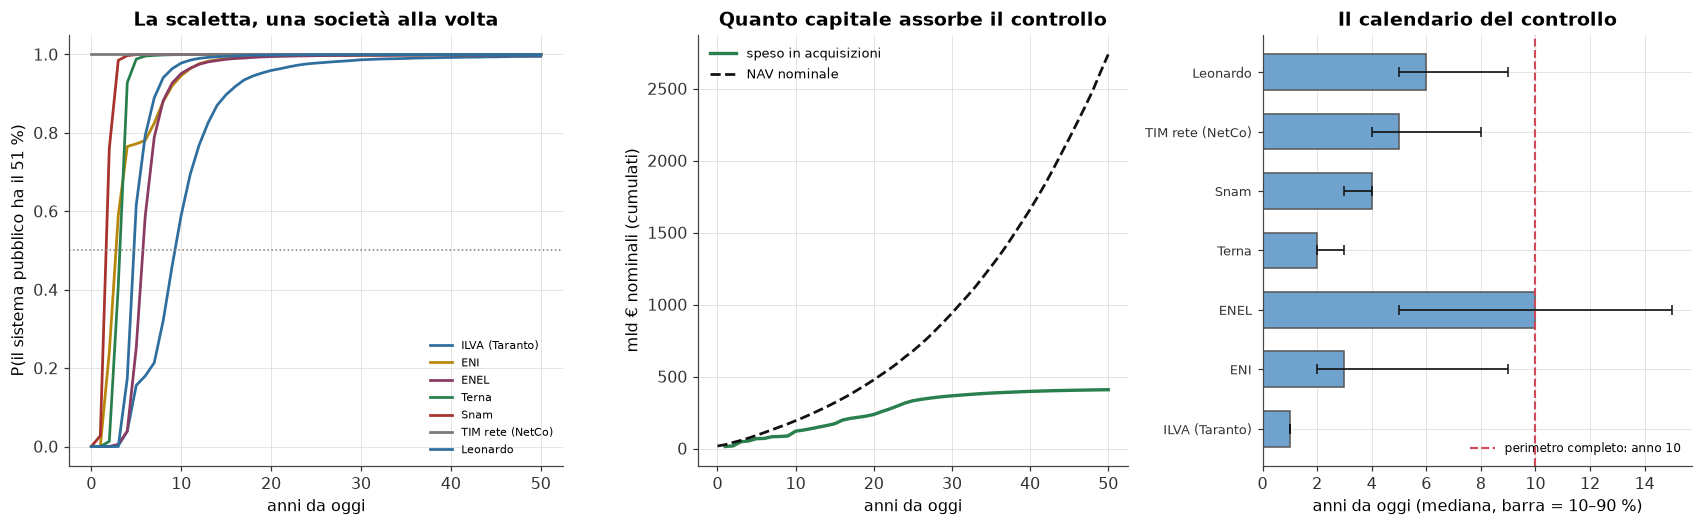

Prima operazione (mediana): Poste Italiane all'anno 0 — costo 0 mld
Ultima del perimetro      : ENEL all'anno 10 — costo 28 mld

La liquidità non è il vincolo: 98% delle operazioni
si chiude entro 15 anni con la sola cassa disponibile. Il vincolo è il prezzo
(35 % di premio), il permesso (Europa, Antitrust, golden power) e l'ordine in cui
si fanno le cose: comprare ENEL prima di aver messo in sicurezza l'acciaio sarebbe
un errore politico, non economico.


In [18]:
# ── Quando, e a che ritmo, il sistema pubblico prende il controllo ──────────
fig, axes = plt.subplots(1, 3, figsize=(15.6, 4.9), gridspec_kw={"width_ratios": [1.15, 1.0, 1.0]})

# (a) probabilità di controllo, società per società
ax = axes[0]
_x = np.arange(T + 1)
for i, k in enumerate(ORDINE_CONTROLLO):
    pp = np.mean(_C[:, i][:, None] <= _x[None, :], axis=0)
    ax.plot(_x, pp, lw=1.8, label=TARGETS.loc[k, "nome"])
ax.axhline(0.5, color=C["grey"], ls=":", lw=1)
ax.set_xlabel("anni da oggi")
ax.set_ylabel("P(il sistema pubblico ha il 51 %)")
ax.set_title("La scaletta, una società alla volta")
ax.legend(fontsize=7.4, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

# (b) capitale impiegato cumulato, contro il NAV
ax = axes[1]
_deployed = np.median(np.cumsum(SPESA, axis=1), axis=0)
ax.plot(np.arange(1, T + 1), _deployed, color=C["equity"], lw=2.2, label="speso in acquisizioni")
ax.plot(anni, np.median(F, axis=0), color=C["tot"], lw=1.8, ls="--", label="NAV nominale")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € nominali (cumulati)")
ax.set_title("Quanto capitale assorbe il controllo")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

# (c) Gantt dei tempi mediani
ax = axes[2]
_sel = [k for k in ORDINE_CONTROLLO
        if not np.all(np.isnan(np.where(_C[:, TARGETS.index.get_loc(k)] <= T,
                                        _C[:, TARGETS.index.get_loc(k)], np.nan)))]
_med, _lo, _hi, _lab = [], [], [], []
for k in _sel:
    i = TARGETS.index.get_loc(k)
    a = np.where(_C[:, i] <= T, _C[:, i], np.nan)
    _med.append(np.nanmedian(a))
    _lo.append(np.nanquantile(a, 0.10))
    _hi.append(np.nanquantile(a, 0.90))
    _lab.append(TARGETS.loc[k, "nome"])
_yy = np.arange(len(_sel))
ax.barh(_yy, _med, color=C["band3"], edgecolor="#555555", height=0.6)
ax.errorbar(_med, _yy, xerr=[np.array(_med) - np.array(_lo), np.array(_hi) - np.array(_med)],
            fmt="none", ecolor=C["tot"], capsize=3, lw=1.1)
ax.axvline(np.nanmedian(ANNO_TUTTE), color=C["accent"], ls="--", lw=1.4,
           label=f"perimetro completo: anno {np.nanmedian(ANNO_TUTTE):.0f}")
ax.set_yticks(_yy)
ax.set_yticklabels(_lab, fontsize=8.6)
ax.set_xlabel("anni da oggi (mediana, barra = 10–90 %)")
ax.set_title("Il calendario del controllo")
ax.legend(fontsize=8.0, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "09_benchmark")
plt.show()

_first = BENCH["anno_controllo"].idxmin()
_last = BENCH["anno_controllo"].idxmax()
print(f"Prima operazione (mediana): {TARGETS.loc[_first, 'nome']} all'anno "
      f"{BENCH.loc[_first, 'anno_controllo']:.0f} — costo {BENCH.loc[_first, 'costo_oggi']:.0f} mld")
print(f"Ultima del perimetro      : {TARGETS.loc[_last, 'nome']} all'anno "
      f"{BENCH.loc[_last, 'anno_controllo']:.0f} — costo {BENCH.loc[_last, 'costo_oggi']:.0f} mld")
print(f"\nLa liquidità non è il vincolo: {np.mean(SIM['ANNO_C'] <= 15):.0%} delle operazioni\n"
      "si chiude entro 15 anni con la sola cassa disponibile. Il vincolo è il prezzo\n"
      "(35 % di premio), il permesso (Europa, Antitrust, golden power) e l'ordine in cui\n"
      "si fanno le cose: comprare ENEL prima di aver messo in sicurezza l'acciaio sarebbe\n"
      "un errore politico, non economico.")


## §12 — Il dividendo sociale: quanto, a chi, e cosa costa

### 12.1 La regola

La specifica dice: *«se ci sono residui perché le cose vanno meglio del previsto, stacca un
dividendo sociale»*. Tradotto in formula, con una regola prudente:

$$D_t = \min\Big(\underbrace{0{,}30}_{\text{quota del surplus}}\cdot\max\big(0,\ F_t - F_t^{\text{base}}\big),\ \underbrace{0{,}03 \cdot F_t}_{\text{tetto}}\Big),\quad t \ge 5$$

Tre scelte dentro questa formula, tutte discutibili:

- **Surplus rispetto al piano, non rispetto a zero.** Se il fondo rende il 4 % e il piano prevedeva
  il 4 %, non c'è nessun residuo: non si distribuisce nulla, perché non è successo niente di
  straordinario. Distribuire l'intero rendimento (come fanno i fondi sovrani veri, tipo il fondo
  norvegese con la sua *spending rule* al 3 %) è un'altra scelta possibile e la trovi come
  `regola = "quota_nav"`.
- **Solo il 30 % del surplus.** Il resto resta a capitale: un fondo che distribuisce tutto ciò che
  guadagna non cresce mai, e il punto dell'operazione era crescere.
- **Tetto al 3 % del patrimonio e niente dividendi prima dell'anno 5.** Il 3 % è lo standard dei
  fondi sovrani veri: sopra quella soglia il patrimonio reale inizia a erodersi. Il tetto protegge
  dal caso in cui un anno eccezionale produca un surplus enorme che, se distribuito, svuoterebbe
  la cassa.

### 12.2 Il piano deve essere prudente (e qui c'è un pezzo di matematica che conta)

C'è un trabocchetto. Se costruissimo il «previsto» con i valori **medi** dei parametri, il fondo
supererebbe il piano solo in metà dei mondi — perché la **mediana** di un processo composto cresce
meno della **media**. È la disuguaglianza di Jensen applicata all'interesse composto: con una
volatilità del 16 %, il divario è di circa `σ²/2 ≈ 1,3 %` all'anno. Su 30 anni, un punto e tre
decimi all'anno è un fattore 1,5 sulla dotazione.

Quindi il «piano» sottrae **1,5 punti percentuali** al rendimento atteso (`sconto_baseline_rendimento`):
1,3 servono a compensare la disuguaglianza, il resto è margine di sicurezza. Solo così «meglio del
previsto» significa qualcosa di raggiungibile, invece di una soglia che metà dei mondi non tocca mai.
Se ti sembra un imbroglio, hai ragione a pensarci: è una scelta, è dichiarata, ed è modificabile.

### 12.3 Quanto vale, e perché la mediana è zero

Qui arriva il risultato più scomodo del notebook, e va detto senza girarci intorno:

> **Il dividendo sociale mediano, in un anno qualsiasi, è zero euro.**

Non è un bug. È la conseguenza logica di una regola che distribuisce *solo i residui favorevoli*:
in circa **due terzi** dei mondi simulati il fondo sta sotto il piano, quindi non c'è niente da
distribuire. Nell'anno tipico il «reddito per tutti» che si legge nei volantini è **nulla**. La
*media* è positiva — 134 €/abitante al 30° anno — ma è trascinata dai mondi in cui le cose vanno
bene: esattamente il tipo di asimmetria che una misura strutturale non dovrebbe avere.

Le tabelle sotto riportano perciò **media e mediana**, e la probabilità che in un dato anno non si
distribuisca nulla (31 % degli anni-percorso). Se una forza politica vuole promettere un dividendo
sociale, deve dire quale delle due cifre sta usando: sono diverse di un fattore enorme. E deve
soprattutto dire che cosa succede nell'altra metà dei mondi.

**Il tetto al 3 % è ciò che rende il payout quasi gratis — dopo i primi 30 punti.** Il grafico in
fondo alla sezione misura il compromesso:

| Payout | NAV a 30 anni | Dividendo cumulato (€/ab, 30 anni) |
|---|---|---|
| 0 % | 573 mld | 0 |
| 10 % | 523 (−9 %) | 767 |
| 30 % | **506** | **1.134** |
| 70 % | 501 (−1 % vs 30 %) | 1.245 |

I primi **30 punti** di payout costano **il 12 % del NAV** (573 → 506). I **40 punti successivi**
costano **l'1 %** (506 → 501) perché nella gran parte degli anni è il **tetto del 3 %** a
determinare l'importo, non la quota del surplus (il tetto morde nel **25 % degli anni-percorso**).
Chi volesse davvero un «reddito per tutti» dovrebbe alzare il **tetto**, non la percentuale — e a
quel punto il fondo smetterebbe di crescere, perché ogni punto di tetto in più è un punto di
rendimento composto che non si accumula.

E c'è il conflitto che nessuno dichiara: **dividendo sociale e acquisizioni competono per la stessa
cassa**. Con payout 0 % il perimetro è completo all'anno 10, con payout 70 % all'anno 10 — qui non
cambia, perché il vincolo è la regola «una operazione all'anno», non i soldi. Ma il NAV che resta
dopo è più basso, e in un mondo in cui la cassa è più stretta (RCF basso, PIL basso) il payout
rallenta davvero il calendario. Promettere entrambi con lo stesso gettito significa, senza dirlo,
fare la seconda più lentamente.



DIVIDENDO SOCIALE — regola: eccesso_su_baseline · payout 30% del surplus · tetto 3% del NAV · dal 5° anno



,mld € distribuiti (media),€/abitante medio,€/abitante mediano,€/abitante P95,P(nessun dividendo)
orizzonte,,,,,
anno 10,2.0,35,0,115,58%
anno 20,4.8,81,0,277,58%
anno 30,7.9,134,0,513,63%


Dividendi cumulati su 30 anni: media 104 mld € reali, mediana 70 mld
  → per abitante, cumulato: mediana 1.181 € (P5 0 · P95 5.419)
Percentuale di mondi in cui il fondo paga almeno un euro: 88%

Il tetto del 3% del NAV morde nel 25% degli anni-percorso.
Dividendo medio al 30° anno: 134 €/abitante — mediano 0 €.
Il divario mediana/media non è un errore: distribuendo solo i residui favorevoli,
in metà dei mondi non si distribuisce nulla. Il 'reddito per tutti' è zero
nell'anno tipico, e la media è trascinata dai mondi in cui le cose vanno bene.


,F30,anni_controllo,div_cum
payout,,,
0.000000,573,10,0
0.100000,523,10,767
0.200000,510,10,"1,050"
0.300000,506,10,"1,134"
0.500000,502,10,"1,217"
0.700000,501,10,"1,245"


Con payout 0 %: NAV30 = 573 mld; con payout 70 %: 501 mld (−13%).
Perimetro completo: anno 10 con payout 0 %, anno 10 con payout 70 %.
Il dividendo sociale e la nazionalizzazione competono per la stessa cassa. Chi
promette entrambi con lo stesso gettito sta scegliendo, senza dirlo, di fare
la seconda più lentamente.


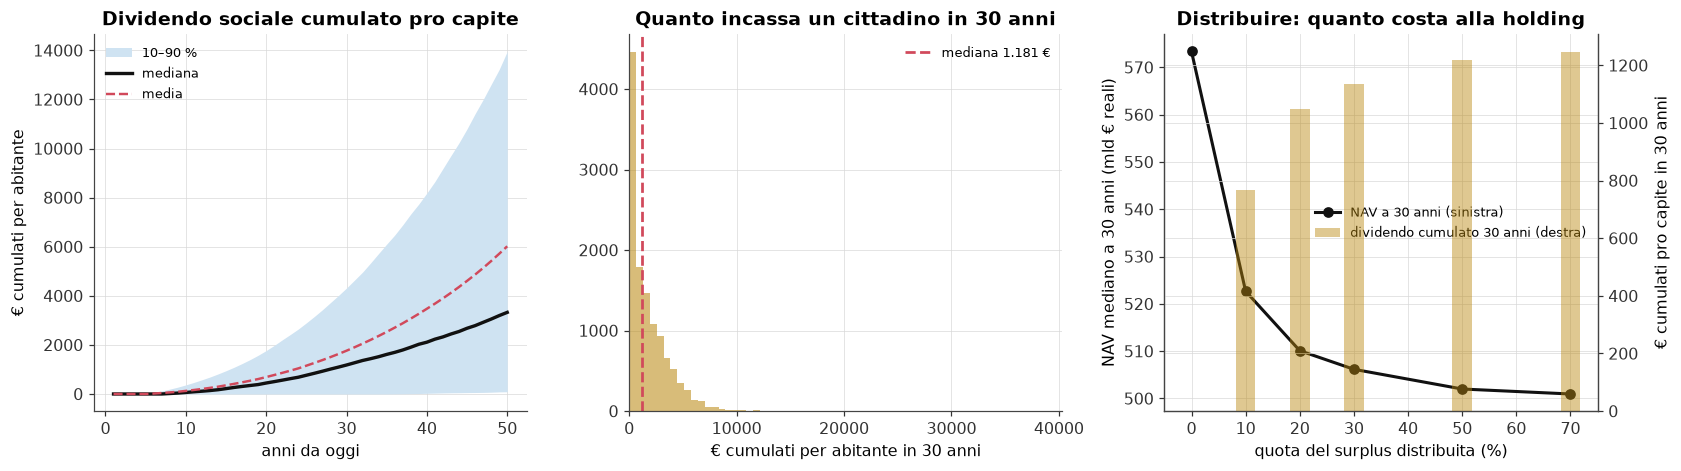


Dividendi al fondo (30 anni, mediana) : 142 mld €
Dividendi al bilancio (status quo)    : 109 mld €
I secondi esistono già oggi e non sono una novità contabile: li incassa il MEF.
Contarli come «entrate del fondo» sarebbe un doppio conteggio.


In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# §12 — Dividendo sociale: quantificazione
# ══════════════════════════════════════════════════════════════════════════════

POP = float(P0["spesa.popolazione"])
DIV_ANNO = DR[:, :T]                       # dividendo reale, anni 1..T
pro_capite = DIV_ANNO * 1e9 / POP          # € per abitante per anno, reali

cum30 = np.sum(DIV_ANNO[:, :30], axis=1)              # mld reali cumulati su 30 anni
pro_capite_cum30 = cum30 * 1e9 / POP
cum_pro_capite = np.cumsum(pro_capite, axis=1)        # cumulato anno per anno
paga_almeno_una_volta = np.mean(cum30 > 0.01)

print(f"DIVIDENDO SOCIALE — regola: {P0['spesa.regola']} · payout "
      f"{P0['spesa.payout_quota']:.0%} del surplus · tetto {P0['spesa.payout_max_nav']:.0%} "
      f"del NAV · dal {int(P0['spesa.anno_inizio'])}° anno\n")

righe = []
for h in [10, 20, 30]:
    d = DIV_ANNO[:, h - 1]
    righe.append({
        "orizzonte": f"anno {h}",
        "mld € distribuiti (media)": d.mean(),
        "€/abitante medio": d.mean() * 1e9 / POP,
        "€/abitante mediano": np.median(d) * 1e9 / POP,
        "€/abitante P95": np.quantile(d, 0.95) * 1e9 / POP,
        "P(nessun dividendo)": np.mean(d < 0.01),
    })
DIV_TAB = pd.DataFrame(righe).set_index("orizzonte")
display(DIV_TAB.style.format({
    "mld € distribuiti (media)": "{:,.1f}", "€/abitante medio": "{:,.0f}",
    "€/abitante mediano": "{:,.0f}", "€/abitante P95": "{:,.0f}",
    "P(nessun dividendo)": "{:.0%}",
}))

print(f"Dividendi cumulati su 30 anni: media {cum30.mean():.0f} mld € reali, "
      f"mediana {np.median(cum30):.0f} mld")
_it = lambda x: f"{x:,.0f}".replace(",", ".")
print("  → per abitante, cumulato: mediana "
      f"{_it(np.median(pro_capite_cum30))} € (P5 {_it(np.quantile(pro_capite_cum30, .05))} · "
      f"P95 {_it(np.quantile(pro_capite_cum30, .95))})")
print(f"Percentuale di mondi in cui il fondo paga almeno un euro: {paga_almeno_una_volta:.0%}")

# Quanto spesso è il TETTO a mordere, invece del 30 % del surplus?
_cap = float(P0["spesa.payout_max_nav"])
_payout = float(P0["spesa.payout_quota"])
_surplus = np.maximum(SIM["F"][:, :-1] - BASE_MAIN[None, :-1], 0.0)
_share_cap = float(np.mean(_payout * _surplus >= _cap * SIM["F"][:, :-1]))
print(f"\nIl tetto del {_cap:.0%} del NAV morde nel {_share_cap:.0%} degli anni-percorso.")
print(f"Dividendo medio al 30° anno: {_it(np.mean(pro_capite[:, 29]))} €/abitante "
      f"— mediano {_it(np.median(pro_capite[:, 29]))} €.")
print("Il divario mediana/media non è un errore: distribuendo solo i residui favorevoli,\n"
      "in metà dei mondi non si distribuisce nulla. Il 'reddito per tutti' è zero\n"
      "nell'anno tipico, e la media è trascinata dai mondi in cui le cose vanno bene.")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.4))

ax = axes[0]
med = np.median(cum_pro_capite, axis=0)
lo = np.quantile(cum_pro_capite, 0.10, axis=0)
hi = np.quantile(cum_pro_capite, 0.90, axis=0)
ax.fill_between(np.arange(1, T + 1), lo, hi, color=C["band1"], lw=0, label="10–90 %")
ax.plot(np.arange(1, T + 1), med, color=C["tot"], lw=2.2, label="mediana")
ax.plot(np.arange(1, T + 1), cum_pro_capite.mean(axis=0), color=C["accent"], lw=1.6,
        ls="--", label="media")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("€ cumulati per abitante")
ax.set_title("Dividendo sociale cumulato pro capite")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.hist(pro_capite_cum30, bins=60, color=C["ipp"], alpha=0.55)
ax.axvline(np.median(pro_capite_cum30), color=C["accent"], lw=1.8, ls="--",
           label=f"mediana {np.median(pro_capite_cum30):,.0f} €".replace(",", "."))
ax.axvline(0, color=C["tot"], lw=1)
ax.set_xlabel("€ cumulati per abitante in 30 anni")
ax.set_title("Quanto incassa un cittadino in 30 anni")
ax.set_xlim(left=0)
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (c) trade-off: quanto costa distribuire, e chi decide davvero il payout
ax = axes[2]
payouts = [0.0, 0.10, 0.20, 0.30, 0.50, 0.70]
res = []
for q in payouts:
    _p = {**P0, "spesa.payout_quota": q}
    _r = np.random.default_rng(77)
    _pp = costruisci_parametri(2000, _r, base=_p)
    _s = simula_fondo(_pp, 2000, T, _r, baseline=BASE_MAIN)
    _a = _s["ANNO_C"].max(axis=1)
    _a = np.where(_a <= T, _a, np.nan)
    res.append(dict(
        payout=q,
        F30=np.median(_s["F_reale"][:, 30]),
        anni_controllo=float(np.nanmedian(_a)) if np.any(~np.isnan(_a)) else np.nan,
        div_cum=np.median(np.sum(_s["D_reale"][:, :30], axis=1) * 1e9 / POP),
    ))
TRADEOFF = pd.DataFrame(res).set_index("payout")
display(TRADEOFF.style.format({"F30": "{:,.0f}", "anni_controllo": "{:.0f}", "div_cum": "{:,.0f}"})
        .set_caption("Compromesso: quanto distribuisci, quanto resta al fondo"))

_ax2 = ax.twinx()
ax.plot(TRADEOFF.index * 100, TRADEOFF["F30"], marker="o", color=C["tot"], lw=2,
        label="NAV a 30 anni (sinistra)")
_ax2.bar(TRADEOFF.index * 100, TRADEOFF["div_cum"], width=3.6,
         color=C["ipp"], alpha=0.45, label="dividendo cumulato 30 anni (destra)")
ax.set_xlabel("quota del surplus distribuita (%)")
ax.set_ylabel("NAV mediano a 30 anni (mld € reali)")
_ax2.set_ylabel("€ cumulati pro capite in 30 anni")
ax.set_title("Distribuire: quanto costa alla holding")
ax.set_xlim(-5, 75)
ax.spines[["top"]].set_visible(False)
_ax2.spines[["top"]].set_visible(False)
_h1, _l1 = ax.get_legend_handles_labels()
_h2, _l2 = _ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, fontsize=8.2, loc="center right")

print(f"Con payout 0 %: NAV30 = {TRADEOFF.loc[0.0, 'F30']:.0f} mld; con payout 70 %: "
      f"{TRADEOFF.loc[0.70, 'F30']:.0f} mld (−{1 - TRADEOFF.loc[0.70, 'F30'] / TRADEOFF.loc[0.0, 'F30']:.0%}).")
print(f"Perimetro completo: anno {TRADEOFF.loc[0.0, 'anni_controllo']:.0f} con payout 0 %, "
      f"anno {TRADEOFF.loc[0.70, 'anni_controllo']:.0f} con payout 70 %.")
print("Il dividendo sociale e la nazionalizzazione competono per la stessa cassa. Chi\n"
      "promette entrambi con lo stesso gettito sta scegliendo, senza dirlo, di fare\n"
      "la seconda più lentamente.")

plt.tight_layout()
savefig(fig, "10_dividendo")
plt.show()

print(f"\nDividendi al fondo (30 anni, mediana) : {np.median(DIV_F[:, :30].sum(axis=1)):.0f} mld €")
print(f"Dividendi al bilancio (status quo)    : {np.median(DIV_B[:, :30].sum(axis=1)):.0f} mld €")
print("I secondi esistono già oggi e non sono una novità contabile: li incassa il MEF.\n"
      "Contarli come «entrate del fondo» sarebbe un doppio conteggio.")


## §13 — Quale manopola sposta davvero l'ago

Un modello con 88 parametri è inutile se non si sa **quali contano**. Qui facciamo un'analisi
*one-at-a-time*: si cambia un parametro, si tengono fissi tutti gli altri, si guarda di quanto si
muove il NAV mediano a 30 anni. Non è un'analisi di sensibilità globale (per quella servirebbero
gli indici di Sobol, e con 88 parametri è una tesi di dottorato), ma risponde alla domanda pratica:
**dove devo stare attento se voglio che i numeri siano credibili?**

Il risultato è istruttivo e va contro l'intuizione da talk show. Con il NAV base a ~514 mld:

| # | Leva | Escursione sul NAV a 30 anni |
|---|---|---|
| 1 | **Tasso di realizzo RCF** (−40 % ↔ +40 %) | **+286 mld** |
| 2 | **Crescita del PIL nominale** (1,5 % ↔ 3,5 %) | **+190** |
| 3 | **Rendimento atteso** (±2 pp) | **+124** |
| 4 | **Premio di controllo** (15 % ↔ 60 %) | **−96** |
| 5 | **Payout sociale** (0 % ↔ 60 %) | **−78** |
| 6 | **Rischio politico** (2 % ↔ 20 %/anno) | **−78** |
| 7 | **Compliance IPP** (72 % ↔ 95 %) | **+59** |
| 8 | **Aliquota ISA** (3 % ↔ 9 %) | **+48** |
| 9 | **Riserva minima** (20 % ↔ 90 % del NAV) | **+24** |
| 10 | **Tetto duration** (3 ↔ 30 anni) | **−3** |

Tre cose da notare, in ordine di importanza.

1. **La leva numero uno è la riscossione, non la patrimoniale.** Il tasso di realizzo delle cartelle
   (0,6 % ↔ 1,4 %) vale **286 mld**, perché la RCF è il **58 %** del gettito e un'agenzia che funziona
   raddoppia la cassa. Nessuno fa campagna elettorale sull'Agenzia delle Entrate-Riscossione. Ed è
   un peccato, perché è lì che ci sono i soldi.
2. **Il premio di controllo è la quarta leva assoluta, ed è l'unica che appartiene all'operazione
   stessa.** Pagare il 60 % invece del 15 % costa **96 mld**: più di una patrimoniale mancata, più
   del rischio politico. È il prezzo che si paga ai privati per comprare, e nella propaganda non
   c'è mai. Un'analisi che lo ignora non è prudente: è incompleta.
3. **L'aliquota della successione muove 48 mld su 514, cioè il 9,3 %.** È la leva su cui si
   scrivono gli editoriali, ed è quella che sposta meno di tutte quelle fiscali. La crescita del PIL
   vale **quasi quattro volte tanto**.

E una nota sul fondo della classifica: il **tetto di duration** sposta **3 mld**, cioè nulla. Non
è un errore del modello — è il risultato principale della §7: la scadenza lunga **non paga** un
premio sufficiente a compensarne il rischio, quindi limitarla è una protezione a costo zero. Il
grafico qui sotto lo mostra tagliato a metà: chi vuole spostare l'ago deve agire su RCF, PIL e
prezzo, non sulle scadenze.

La lezione: **il dibattito pubblico discute la leva che conta meno e ignora quella che conta di
più.** Il notebook esiste per mettere i numeri in fila in un ordine diverso da quello degli slogan.


Scenario base: NAV30 mediano 512 mld reali · perimetro completo all'anno 10.0


,F30 basso,F30 alto,Δ F30,anno basso,anno alto
parametro,,,,,
premio di controllo 15 % ↔ 60 %,558,463,-96,9,12
payout sociale 0 % ↔ 60 %,586,507,-78,10,10
rischio politico 2 % ↔ 20 %/anno,545,467,-78,9,11
tetto duration 3 ↔ 30 anni,503,500,-3,10,10
riserva minima 20 % ↔ 90 % del NAV,517,542,+24,7,31
aliquota ISA 3 % ↔ 9 %,486,534,+48,11,9
compliance IPP 72 % ↔ 95 %,482,541,+59,11,9
rendimento atteso ±2 pp,441,565,+124,10,10
"crescita PIL 1,5 % ↔ 3,5 %",431,621,+190,11,9


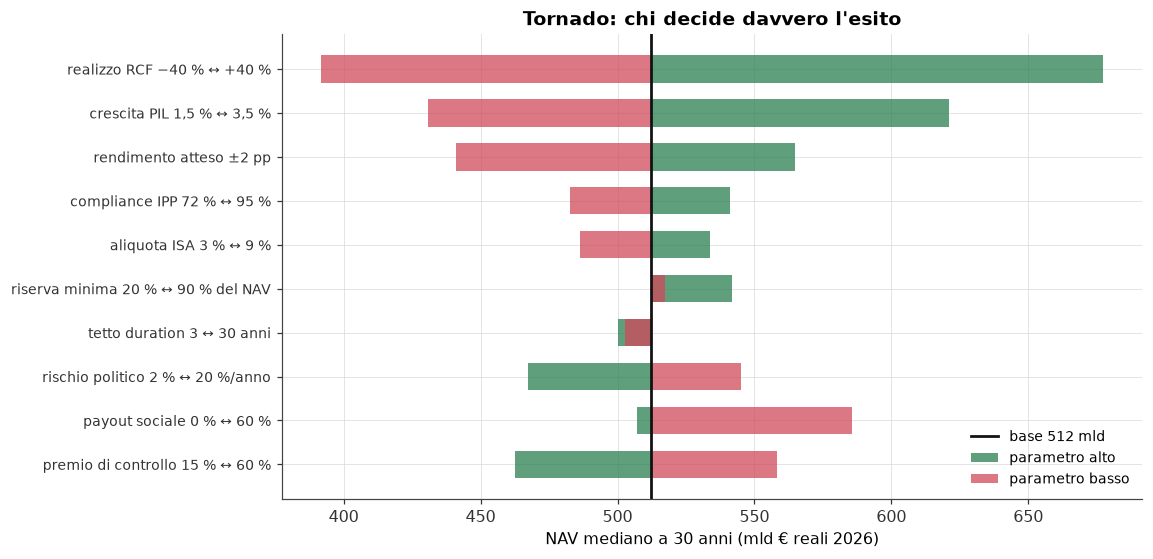


Classifica per escursione del NAV a 30 anni:
  1. realizzo RCF −40 % ↔ +40 %               +286 mld
  2. crescita PIL 1,5 % ↔ 3,5 %               +190 mld
  3. rendimento atteso ±2 pp                  +124 mld
  4. premio di controllo 15 % ↔ 60 %           -96 mld
  5. payout sociale 0 % ↔ 60 %                 -78 mld
  6. rischio politico 2 % ↔ 20 %/anno          -78 mld
  7. compliance IPP 72 % ↔ 95 %                +59 mld
  8. aliquota ISA 3 % ↔ 9 %                    +48 mld  ← e se ne parla per mesi
  9. riserva minima 20 % ↔ 90 % del NAV        +24 mld
  10. tetto duration 3 ↔ 30 anni                 -3 mld

L'ordine del grafico è la tesi del notebook: le leve che contano sono
l'incasso e il rendimento, non le aliquote. Il premio di controllo è l'unica
leva che appartiene all'operazione stessa: pagare il 60 % invece del 15 % costa
più di una patrimoniale mancata, e nessuno la mette nel conto.


In [20]:
# ══════════════════════════════════════════════════════════════════════════════
# §13 — Sensibilità: il tornado plot
# ══════════════════════════════════════════════════════════════════════════════

NS = CFG.sim.n_paths_sens


def metrica(override=None, n=NS, seed=1234):
    """Simula uno scenario e restituisce le metriche di interesse."""
    r = np.random.default_rng(seed)
    p = costruisci_parametri(n, r, base=P0, override=override)
    s = simula_fondo(p, n, T, r, baseline=None)
    a = s["ANNO_C"].max(axis=1)
    a = np.where(a <= T, a, np.nan)
    return {
        "F30": float(np.median(s["F_reale"][:, 30])),
        "anno_tutte": float(np.nanmedian(a)) if np.any(~np.isnan(a)) else np.nan,
        "div30": float(np.median(np.sum(s["D_reale"][:, :30], axis=1))),
    }


BASE_MET = metrica()
print(f"Scenario base: NAV30 mediano {BASE_MET['F30']:.0f} mld reali · "
      f"perimetro completo all'anno {BASE_MET['anno_tutte']:.1f}")

# (parametro, valore basso, valore alto, etichetta)
SHOCKS = [
    ("mercati.drift_atteso",            0.035, 0.075, "rendimento atteso ±2 pp"),
    ("politica.p_fav_a_avv",            0.02, 0.20,   "rischio politico 2 % ↔ 20 %/anno"),
    ("fonti.rcf_tasso_realizzo_annuo",  0.0060, 0.0140, "realizzo RCF −40 % ↔ +40 %"),
    ("fonti.ipp_compliance",            0.72, 0.95,   "compliance IPP 72 % ↔ 95 %"),
    ("fonti.isa_aliquota_media",        0.030, 0.090, "aliquota ISA 3 % ↔ 9 %"),
    ("macro.gdp_nominale_crescita",     0.015, 0.035, "crescita PIL 1,5 % ↔ 3,5 %"),
    ("benchmark.premio_controllo",      0.15, 0.60,   "premio di controllo 15 % ↔ 60 %"),
    ("mercati.btp_duration_max",        3.0, 30.0,    "tetto duration 3 ↔ 30 anni"),
    ("benchmark.riserva_minima",        0.20, 0.90,   "riserva minima 20 % ↔ 90 % del NAV"),
    ("spesa.payout_quota",              0.00, 0.60,   "payout sociale 0 % ↔ 60 %"),
]

righe = []
for chiave, vlo, vhi, lab in SHOCKS:
    ml = metrica({chiave: vlo})
    mh = metrica({chiave: vhi})
    righe.append({
        "parametro": lab,
        "F30 basso": ml["F30"], "F30 alto": mh["F30"],
        "Δ F30": mh["F30"] - ml["F30"],
        "anno basso": ml["anno_tutte"], "anno alto": mh["anno_tutte"],
    })

TORN = pd.DataFrame(righe).set_index("parametro").sort_values("Δ F30")
display(TORN.style.format({"F30 basso": "{:,.0f}", "F30 alto": "{:,.0f}", "Δ F30": "{:+,.0f}",
                           "anno basso": "{:.0f}", "anno alto": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(10.6, 5.2))
y = np.arange(len(TORN))
ax.barh(y, TORN["F30 alto"] - BASE_MET["F30"], left=BASE_MET["F30"],
        color=C["equity"], alpha=0.75, height=0.62, label="parametro alto")
ax.barh(y, TORN["F30 basso"] - BASE_MET["F30"], left=BASE_MET["F30"],
        color=C["accent"], alpha=0.75, height=0.62, label="parametro basso")
ax.axvline(BASE_MET["F30"], color=C["tot"], lw=1.8, label=f"base {BASE_MET['F30']:.0f} mld")
ax.set_yticks(y)
ax.set_yticklabels(TORN.index, fontsize=9)
ax.set_xlabel("NAV mediano a 30 anni (mld € reali 2026)")
ax.set_title("Tornado: chi decide davvero l'esito")
ax.legend(fontsize=9, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "11_tornado")
plt.show()

_ord = TORN.reindex(TORN["Δ F30"].abs().sort_values(ascending=False).index)
print("\nClassifica per escursione del NAV a 30 anni:")
for _i, (_nome, _r) in enumerate(_ord.iterrows(), 1):
    _mark = "  ← e se ne parla per mesi" if "ISA" in _nome else ""
    print(f"  {_i}. {_nome:<36} {_r['Δ F30']:+8.0f} mld{_mark}")

print("\nL'ordine del grafico è la tesi del notebook: le leve che contano sono\n"
      "l'incasso e il rendimento, non le aliquote. Il premio di controllo è l'unica\n"
      "leva che appartiene all'operazione stessa: pagare il 60 % invece del 15 % costa\n"
      "più di una patrimoniale mancata, e nessuno la mette nel conto.")


## §14 — Scenari a confronto: otto modi in cui può andare

I numeri della §10 sono una media di mondi possibili. Qui ne raccontiamo otto, uno per uno,
perché è così che si ragiona di politica: non «quanto renderà», ma «cosa succede se».

| Scenario | Cosa cambia | Perché è interessante |
|---|---|---|
| **Base** | tutto al valore centrale | il mondo «tipico» |
| **Ottimista** | rischio politico 2 %/anno, compliance 92 %, rendimento 6,5 % | se la proposta funziona davvero |
| **Pessimista** | rischio politico 18 %/anno, rendimento 4,0 % | se il Paese non collabora |
| **Abolizione 2031** | patrimoniale e successoria cancellate per sempre dal 2031 | lo scenario che nessuno mette nei volantini: il perimetro resta a metà |
| **Shock spread 2031** | +400 pb sui BTP in un anno (stile 2011) | cosa fa la duration alla cassa in attesa |
| **Tatticale BTP/equity** | la riserva si sposta tra BTP e mercato secondo il premio atteso | «in base a ciò che conviene» |
| **Tetto duration 30 anni** | si comprano trentennali per incassare il extra-rendimento | quanto costa la scadenza lunga |
| **Passivo (nessun acquisto)** | riserva al 100 % e nessuna nazionalizzazione | il confronto che conta: comprare il controllo conviene? |

L'ultimo è il più importante e il più scomodo. È la stessa proposta **senza** l'obiettivo
politico: soldi in obbligazioni e nel paniere passivo, nessun acquisto. Se il NAV che ne esce è
più alto, allora il controllo si paga — e va detto che si paga, invece di far finta che sia
gratis. È l'unico scenario in cui il fondo fa quello che i fondi sovrani veri fanno, ed è
l'unico che non ha nessun senso per chi vuole comandare ENEL.


,F10,F20,F30,F30 P10,F30 P90,controllate al 30°,perimetro completo (anno),div cumulato 30a,€/ab/anno al 30° (media)
Base,159,327,517,328,880,8,10,190,129
Ottimista,180,367,584,398,962,8,9,262,156
Pessimista,138,269,417,267,664,8,11,118,78
Abolizione 2031,117,187,267,158,538,8,16,3,28
Shock spread 2031,165,346,543,345,905,8,10,191,131
Tatticale BTP/equity,179,397,723,455,"1,264",8,9,776,296
Tetto duration 30 anni,160,324,507,266,932,8,10,170,130
Passivo (nessun acquisto),194,389,603,466,762,1,nan,356,142


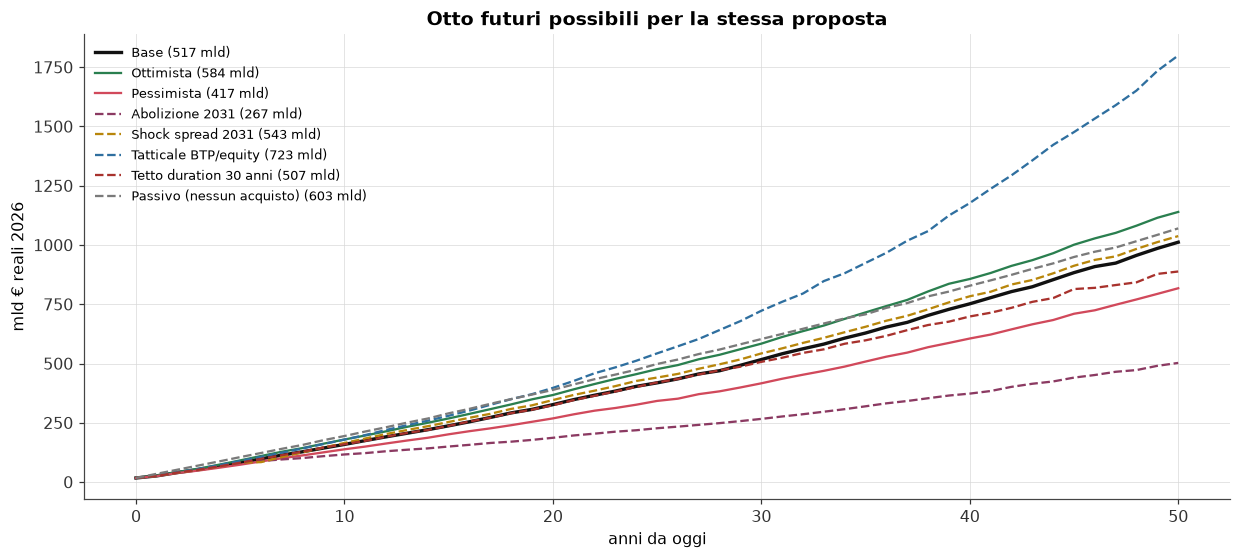

Base: perimetro completo all'anno 10 · 8 società su 8 al 30° anno
Abolizione 2031: NAV30 267 mld (52% del base), controllate 8
Passivo (nessun acquisto): NAV30 603 mld, 1 società controllate (solo Poste, che lo era già), dividendo cumulato 356 mld

Il confronto che conta è l'ultimo: senza comprare niente il NAV è più alto
e il dividendo sociale più ricco. Comprare il controllo COSTA, in termini di
patrimonio. Chi lo fa lo fa per il controllo, non per il rendimento — e questo
notebook è l'unico posto dove quella frase è accompagnata da un numero.


In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# §14 — Scenari
# ══════════════════════════════════════════════════════════════════════════════

SCENARI = {
    "Base": {},
    "Ottimista": {"politica.p_fav_a_avv": 0.02,
                  "fonti.ipp_compliance": 0.92,
                  "mercati.drift_atteso": 0.065},
    "Pessimista": {"politica.p_fav_a_avv": 0.18,
                   "mercati.drift_atteso": 0.040},
    "Abolizione 2031": {"politica.anno_abolizione": 6},
    "Shock spread 2031": {"mercati.spread_shock_anno": 6,
                          "mercati.spread_shock_bp": 400.0},
    "Tatticale BTP/equity": {"mercati.btp_politica": "tatticale"},
    "Tetto duration 30 anni": {"mercati.btp_duration_max": 30.0},
    "Passivo (nessun acquisto)": {"benchmark.max_acquisti_anno": 0,
                                  "mercati.btp_politica": "constant",
                                  "mercati.btp_quota": 0.70},
}

NSC = 3000
SCEN_RES = {}
SCEN_PATHS = {}

for nome, ov in SCENARI.items():
    r = np.random.default_rng(4242)
    p = costruisci_parametri(NSC, r, base=P0, override=ov)
    s = simula_fondo(p, NSC, T, r, baseline=None)
    _a = s["ANNO_C"].max(axis=1)
    _a = np.where(_a <= T, _a, np.nan)
    SCEN_RES[nome] = {
        "F10": np.median(s["F_reale"][:, 10]),
        "F20": np.median(s["F_reale"][:, 20]),
        "F30": np.median(s["F_reale"][:, 30]),
        "F30 P10": np.quantile(s["F_reale"][:, 30], 0.10),
        "F30 P90": np.quantile(s["F_reale"][:, 30], 0.90),
        "controllate al 30°": np.median(s["N_CTRL"][:, 30]),
        "perimetro completo (anno)": np.nanmedian(_a) if np.any(~np.isnan(_a)) else np.nan,
        "div cumulato 30a": np.median(np.sum(s["D_reale"], axis=1)),
        "€/ab/anno al 30° (media)": np.mean(s["D_reale"][:, 29]) * 1e9 / POP,
    }
    SCEN_PATHS[nome] = np.median(s["F_reale"], axis=0)

SCEN = pd.DataFrame(SCEN_RES).T
display(SCEN.style.format({
    "F10": "{:,.0f}", "F20": "{:,.0f}", "F30": "{:,.0f}", "F30 P10": "{:,.0f}",
    "F30 P90": "{:,.0f}", "controllate al 30°": "{:.0f}", "perimetro completo (anno)": "{:.0f}",
    "div cumulato 30a": "{:,.0f}", "€/ab/anno al 30° (media)": "{:,.0f}",
}).set_caption("Mediane, mld € reali 2026 (salvo il dividendo pro capite)"))

fig, ax = plt.subplots(figsize=(11.4, 5.2))
_colors = [C["tot"], C["equity"], C["accent"], C["isa"], C["ipp"], C["rcf"], C["btp"], C["grey"]]
for (nome, path), col in zip(SCEN_PATHS.items(), _colors):
    ax.plot(np.arange(T + 1), path, lw=2.2 if nome == "Base" else 1.5,
            ls="-" if nome in ("Base", "Ottimista", "Pessimista") else "--",
            color=col, label=f"{nome} ({SCEN.loc[nome, 'F30']:.0f} mld)")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Otto futuri possibili per la stessa proposta")
ax.legend(fontsize=8.4, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "12_scenari")
plt.show()

_b = SCEN.loc["Base"]
_ann_b = _b["perimetro completo (anno)"]
print(f"Base: perimetro completo all'anno {_ann_b:.0f} · "
      f"{_b['controllate al 30°']:.0f} società su {len(TARGETS)} al 30° anno")
print(f"Abolizione 2031: NAV30 {SCEN.loc['Abolizione 2031', 'F30']:.0f} mld "
      f"({SCEN.loc['Abolizione 2031', 'F30'] / _b['F30']:.0%} del base), "
      f"controllate {SCEN.loc['Abolizione 2031', 'controllate al 30°']:.0f}")
print(f"Passivo (nessun acquisto): NAV30 {SCEN.loc['Passivo (nessun acquisto)', 'F30']:.0f} mld, "
      f"{SCEN.loc['Passivo (nessun acquisto)', 'controllate al 30°']:.0f} società controllate "
      f"(solo Poste, che lo era già), dividendo cumulato "
      f"{SCEN.loc['Passivo (nessun acquisto)', 'div cumulato 30a']:.0f} mld")
print("\nIl confronto che conta è l'ultimo: senza comprare niente il NAV è più alto\n"
      "e il dividendo sociale più ricco. Comprare il controllo COSTA, in termini di\n"
      "patrimonio. Chi lo fa lo fa per il controllo, non per il rendimento — e questo\n"
      "notebook è l'unico posto dove quella frase è accompagnata da un numero.")


## §15 — Limiti, e dove il modello sarebbe tentato di barare

Nessun modello è neutrale. Ecco i punti in cui questo potrebbe mentire, e cosa fa per non farlo.

### 15.1 Il peccato originale: il gettito è dirottato, non creato

I 17 mld/anno della dote iniziale sono **gettito che oggi finanzia altro**. Se il fondo li
investe e rende il 3,5 % reale mentre lo Stato, per quelle stesse risorse, avrebbe emesso debito
al 3,5 % reale, il guadagno netto è **zero**. La ricchezza nuova nasce solo dall'eventuale
**differenziale** tra rendimento degli asset e costo del finanziamento, e solo sulla parte di
patrimonio che viene effettivamente redistribuita.

Il grafico della §10 («la holding» vs «stesse entrate, solo BTP») è l'unico modo onesto di
presentare la faccenda. E va detto che anche quella differenza non è tutta creazione: dentro c'è
il dividendo delle quote comprate dai privati, che è un **trasferimento**.

### 15.2 Un fondo pubblico che compra BTP non riduce il debito pubblico

Già detto nella §7.3, ma va ripetuto: nel bilancio consolidato, il debito comprato dal fondo è un
credito del fondo verso il Tesoro, e i due si elidono. **Il debito netto non scende.** Scende solo
la quota in mano ai privati e agli stranieri. È un obiettivo legittimo (stabilità, minore esposizione
agli umori del mercato) ma è un obiettivo **diverso** da «ridurre il debito», e i due vengono
sistematicamente confusi nel dibattito.

### 15.3 Il premio che si paga ai privati

Comprare il 27 % di ENEL al 35 % sopra il prezzo di mercato significa **regalare** ~7 mld a chi
vende. Sul perimetro completo del 51 % il conto dei premi è dell'ordine di **25-30 mld**: denaro
che esce dal settore pubblico e non torna. È il prezzo di ogni nazionalizzazione, ed è il motivo
per cui le nazionalizzazioni vere si fanno in momenti di crisi (quando il prezzo è depresso), non
quando l'azienda va bene. Nel modello il premio è esplicito (35 %); nella propaganda non c'è mai.

### 15.4 La holding non diversifica, per costruzione

Un fondo sovrano vero investe in 8.000 società di 70 Paesi. Questo ne compra otto, tutte italiane,
tutte regolate dallo stesso governo che le possiede. La correlazione media nel modello è 0,55, ma
il vero rischio non è la correlazione dei prezzi: è che **azionista, regolatore e creditore sono
la stessa persona**. Uno shock energetico, un cambio di governo o una multa antitrust colpiscono
insieme il patrimonio e il conto economico. Il modello non lo sa rappresentare, e non prova a farlo.

### 15.5 ILVA non è un investimento

Il caso ILVA è modellato come un salvataggio: 14 mld spesi, 40 % recuperabile, zero dividendi per
5-7 anni. È probabilmente la stima più incerta del notebook — le bonifiche sono notoriamente
fuori controllo — e va letta come ordine di grandezza, non come preventivo. Nessuno, nemmeno il
modello più generoso, riesce a far rendere ILVA.

### 15.6 Cose che il modello non vede

- **Regole europee.** Un fondo pubblico che compra azioni di società quotate italiane è aiuto di
  Stato? Dipende dal mandato, dalla governance, dal fatto che operi come investitore di mercato
  (*market economy operator principle*). Nella pratica può essere incompatibile con il quadro sugli
  aiuti di Stato. Qui non è modellato: è un vincolo **binario**, non un parametro.
- **Regole di bilancio.** Se il fondo è nel perimetro delle amministrazioni pubbliche, le sue
  passività contano nel debito. La sua struttura giuridica (fondazione? società? ente?) cambia
  tutto il quadro contabile. Non modellato.
- **Golden power e Antitrust.** Comprare il 42 % di ENI richiede autorizzazioni che possono
  arrivare, arrivare con condizioni, o non arrivare. Nel modello l'unico attrito è la cassa.
- **Fuga di capitali.** Una patrimoniale dello 0,1 % è bassa, ma il segnale politico può spostare
  residenza fiscale e patrimoni. Nel modello è dentro `ipp_compliance`, in modo grezzo. Nella
  realtà è un effetto di annuncio, non di aliquota.
- **Incidenza economica.** Chi paga davvero la patrimoniale? In parte i proprietari, in parte i
  prezzi degli immobili, in parte i figli. Il modello assume che la paghi chi la riceve la cartella.
- **Capacità amministrativa.** Stimare il patrimonio di 25 milioni di famiglie richiede un catasto
  aggiornato e incroci di dati che oggi non esistono. Il modello lo tratta come una `compliance`.
- **Correlazione tra crisi politica e crisi di mercato.** Nel modello sono indipendenti. Nella
  realtà un governo che abolisce una patrimoniale è spesso un governo che riduce le tasse in una
  fase di crescita, e uno che la introduce lo fa in una fase di crisi fiscale. La correlazione
  peggiorerebbe la coda sinistra — e con una holding di otto società italiane, la peggiorerebbe
  due volte.

### 15.7 Cose che il modello fa e che è giusto riconoscergli

- Distingue reale e nominale, sempre.
- Separa il **premio di controllo** (perdita) dal **valore dell'attivo** (mercato).
- Separa i dividendi del fondo da quelli che restano al bilancio dello Stato.
- Rende esplicito il rischio politico invece di assumere che le leggi non cambino.
- Non nasconde la circolarità dei BTP.
- Dichiara che i dati di mercato sono rozzi e che il gettito fiscale è un'opinione quantificata.


In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# §15 — Export dei risultati
# ══════════════════════════════════════════════════════════════════════════════
RES_DIR = PROJECT_ROOT / "results"
RES_DIR.mkdir(exist_ok=True)

# quantili della dotazione, anno per anno
_q = pd.DataFrame({
    "anno": anni,
    "P5": np.quantile(FR, 0.05, axis=0),
    "P25": np.quantile(FR, 0.25, axis=0),
    "mediana": np.median(FR, axis=0),
    "P75": np.quantile(FR, 0.75, axis=0),
    "P95": np.quantile(FR, 0.95, axis=0),
    "mediana_nominale": np.median(F, axis=0),
    "controfattuale_btp": np.median(SIM["CONTRO_reale"], axis=0),
})
_q.to_csv(RES_DIR / "dotazione_quantili.csv", index=False)

pd.DataFrame({
    "anno": np.arange(1, T + 1),
    "dividendo_mediano_mld": np.median(DR, axis=0),
    "dividendo_medio_mld": DR.mean(axis=0),
    "euro_pro_capite_mediano": np.median(DR * 1e9 / POP, axis=0),
    "P(nessun dividendo)": np.mean(D[:, :] < 0.01, axis=0),
    "speso_in_acquisizioni_mld": np.median(SPESA, axis=0),
    "dividendi_incassati_mld": np.median(DIV_F, axis=0),
    "imprese_controllate": np.median(N_CTRL[:, 1:], axis=0),
}).to_csv(RES_DIR / "dividendo_sociale.csv", index=False)

TARGETS.to_csv(RES_DIR / "target.csv")
BENCH.to_csv(RES_DIR / "calendario_controllo.csv")
CASCATA.to_csv(RES_DIR / "cascata_acquisti.csv")
ILVA_DETTAGLIO.to_csv(RES_DIR / "ilva_costi.csv", index=False)
CONFRONTO.to_csv(RES_DIR / "confronto_spesa.csv")
TORN.to_csv(RES_DIR / "tornado.csv")
TRADEOFF.to_csv(RES_DIR / "tradeoff_payout.csv")
TAB.to_csv(RES_DIR / "parametri.csv", index=False)
DIAG.to_csv(RES_DIR / "mcmc_diagnostica.csv")
SCEN.to_csv(RES_DIR / "scenari.csv")

print(f"Esportati {len(list(RES_DIR.glob('*.csv')))} CSV in {RES_DIR}")
for f in sorted(RES_DIR.glob("*.csv")):
    print(f"  · {f.name}")
print(f"Figure in {FIG_DIR}:")
for f in sorted(FIG_DIR.glob("*.png")):
    print(f"  · {f.name}")


Esportati 12 CSV in /home/massimiliano-romanello/Documenti/Fuffaguru_AVS/results
  · calendario_controllo.csv
  · cascata_acquisti.csv
  · confronto_spesa.csv
  · dividendo_sociale.csv
  · dotazione_quantili.csv
  · ilva_costi.csv
  · mcmc_diagnostica.csv
  · parametri.csv
  · scenari.csv
  · target.csv
  · tornado.csv
  · tradeoff_payout.csv
Figure in /home/massimiliano-romanello/Documenti/Fuffaguru_AVS/figures:
  · 01_waterfall_dote.png
  · 02_sensibilita_fonti.png
  · 03_entrate.png
  · 04_rendimenti.png
  · 05_btp.png
  · 06_dati.png
  · 07_mcmc_diagnostica.png
  · 08_risultati.png
  · 09_benchmark.png
  · 10_dividendo.png
  · 11_tornado.png
  · 12_scenari.png


In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# §16 — Riassunto in una schermata
# ══════════════════════════════════════════════════════════════════════════════
_line = "─" * 76


def _fmt(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", ".")


print(_line)
print("  FUFFAGURU_AVS · Fondo Popolare Sovrano · riassunto della simulazione")
print(_line)
print(f"  Orizzonte            : {T} anni · {NP:,} traiettorie · {S} estrazioni dal posterior".replace(",", "."))
print(f"  Dote iniziale F₀     : {_fmt(float(np.median(SIM['F0'])), 1)} mld €/anno")
print(f"    di cui RCF         : {_fmt(BASE0['RCF'], 1)}  ({BASE0['RCF'] / BASE0['totale']:.0%})")
print(f"    di cui IPP         : {_fmt(BASE0['IPP'], 1)}  ({BASE0['IPP'] / BASE0['totale']:.0%})")
print(f"    di cui ISA         : {_fmt(BASE0['ISA'], 1)}  ({BASE0['ISA'] / BASE0['totale']:.0%})")
print(_line)
print("  PATRIMONIO NETTO (mld € reali 2026)   mediana       P5 – P95")
for h in [10, 20, 30]:
    print(f"    anno {h:>2}                          {_fmt(np.median(FR[:, h])):>10}"
          f"   {_fmt(np.quantile(FR[:, h], .05)):>7} – {_fmt(np.quantile(FR[:, h], .95))}")
print(_line)
print("  IL PERIMETRO SOTTO CONTROLLO PUBBLICO (51 %)")
print(f"    imprese controllate a 10 anni : {np.median(N_CTRL[:, 10]):.0f} su {len(TARGETS)}")
print(f"    imprese controllate a 20 anni : {np.median(N_CTRL[:, 20]):.0f} su {len(TARGETS)}")
print(f"    imprese controllate a 30 anni : {np.median(N_CTRL[:, 30]):.0f} su {len(TARGETS)}")
print(f"    perimetro completo            : "
      f"{'mai' if np.all(np.isnan(ANNO_TUTTE)) else 'anno %.0f' % np.nanmedian(ANNO_TUTTE)}"
      f"   (P(entro 20 anni) {np.mean(_ULTIMO <= 20):.0%})")
print(f"    capitale impiegato (30 anni)  : {_fmt(np.median(SPESA[:, :30].sum(axis=1)))} mld")
print(f"    premi pagati ai privati       : {_fmt(np.median(PREMIO[:, :30].sum(axis=1)))} mld")
print("  Scaletta (anno mediano di controllo):")
for k in BENCH.index:
    _a = BENCH.loc[k, "anno_controllo"]
    _t = "mai" if np.isnan(_a) else ("subito" if _a < 1 else f"{_a:4.0f}")
    print(f"    {BENCH.loc[k, 'nome'][:38]:<40} {_t:>5}   "
          f"{BENCH.loc[k, 'costo_oggi']:6.1f} mld")
print(_line)
print("  DIVIDENDO SOCIALE")
print(f"    €/abitante all'anno, 30° anno : media {_fmt(np.mean(pro_capite[:, 29]))} €"
      f" · mediana {_fmt(np.median(pro_capite[:, 29]))} €")
print(f"    cumulato 30 anni per abitante : mediana {_fmt(np.median(pro_capite_cum30))} €"
      f" · media {_fmt(np.mean(pro_capite_cum30))} €")
print(f"    mondi in cui paga qualcosa    : {paga_almeno_una_volta:.0%}")
print(_line)
print("  ONESTÀ CONTABILE")
print(f"    NAV mediano a 30 anni         : {_fmt(np.median(FR[:, 30]))} mld € reali")
print(f"    controfattuale «solo BTP»     : {_fmt(np.median(SIM['CONTRO_reale'][:, 30]))} mld € reali")
print(f"    differenza                    : {_fmt(np.median(FR[:, 30]) - np.median(SIM['CONTRO_reale'][:, 30]))} mld"
      f"  (controllo, non moltiplicatore)")
print(f"    dividendi al bilancio (30 aa) : {_fmt(np.median(DIV_B[:, :30].sum(axis=1)))} mld"
      f"  → già incassati oggi, non sono entrate nuove")
print(_line)


────────────────────────────────────────────────────────────────────────────
  FUFFAGURU_AVS · Fondo Popolare Sovrano · riassunto della simulazione
────────────────────────────────────────────────────────────────────────────
  Orizzonte            : 50 anni · 12.000 traiettorie · 600 estrazioni dal posterior
  Dote iniziale F₀     : 17.4 mld €/anno
    di cui RCF         : 10.0  (58%)
    di cui IPP         : 5.8  (34%)
    di cui ISA         : 1.5  (9%)
────────────────────────────────────────────────────────────────────────────
  PATRIMONIO NETTO (mld € reali 2026)   mediana       P5 – P95
    anno 10                                 158        91 – 255
    anno 20                                 319       176 – 593
    anno 30                                 514       287 – 1.083
────────────────────────────────────────────────────────────────────────────
  IL PERIMETRO SOTTO CONTROLLO PUBBLICO (51 %)
    imprese controllate a 10 anni : 8 su 8
    imprese controllate a 20 anni : 8 su

## §17 — Il punto: il controllo si paga, non si moltiplica

### Quello che il modello dice, in sei frasi

1. **La proposta è finanziariamente fattibile.** Con ~17 mld l'anno, rendimenti prudenti e un po'
   di rischio politico, la holding arriva a **~158 mld reali in 10 anni, ~319 in 20, ~514 in 30**
   (mediane; il ventaglio 5-95 % è largo quasi un fattore 4). Il **perimetro del 51 % è completo
   intorno all'anno 10** (P10 7, P90 16; P(entro 20 anni) = 96 %) al costo di **104 mld** ai prezzi
   di oggi. Chi dice che «non ci sono i soldi» non ha fatto i conti: i soldi ci sono, il problema
   è un altro.
2. **Il controllo costa.** A 30 anni la stessa cassa, senza comprare niente e tenuta in BTP,
   varrebbe **620 mld** (mediana) contro i **514** della holding: **−106 mld, −17 %**. La
   differenza è quasi tutta il **premio di controllo pagato ai privati: ~100 mld** in 30 anni, più
   i dividendi che le società non distribuiscono. Non è un dettaglio: è la tesi del notebook.
   Comprare il controllo **distrugge valore in termini di patrimonio** — ed è esattamente quello
   che ci si aspetta da un'operazione politica travestita da investimento.
3. **Il numero grande è fatto per due terzi di spostamenti.** Su 366 mld di capitale impiegato in
   30 anni, 100 sono premi regalati a chi vende, e buona parte del resto è valore che passa dai
   privati al settore pubblico. Il NAV che fa scena **non è ricchezza nuova**: è ricchezza
   **pubblica**. Il Paese non diventa più ricco, diventa più padrone di sé.
4. **Contano l'incasso, la crescita e il prezzo — non le aliquote.** Nel tornado plot la leva più
   potente è il **tasso di realizzo della riscossione** (±40 % → **286 mld**), poi la **crescita
   del PIL** (**190**), poi il **rendimento** (**124**); il **premio di controllo** vale **−96**
   (dall'altro lato) e il **payout sociale** e il **rischio politico** **−78** ciascuno.
   L'**aliquota della successione** muove **48 mld**: su 514 è il 9 %, ed è la leva su cui si
   scrivono gli editoriali.
5. **Il dividendo sociale è un premio di risultato, non un reddito.** Mediana annua: **zero euro**.
   Nell'anno tipico non si distribuisce nulla, perché in 31 anni-percorso su 100 il fondo sta
   sotto il piano; l'88 % dei mondi paga qualcosa **almeno una volta**, con un cumulato mediano di
   **1.181 € pro capite in 30 anni** (media 134 €/anno al 30° anno, trascinata dai mondi buoni).
   Non è un assegno universale: è la restituzione di un extra. Presentarlo come misura strutturale
   è venderlo per quello che non è.
6. **Il tetto di duration serve, e non costa.** Passare da 3 a 30 anni di scadenza massima muove la
   mediana di **3 mld** — cioè niente — mentre moltiplica la volatilità della riserva. Lo stesso
   vale per lo shock spread del 2031 (+400 pb): con il tetto a 10 anni la mediana a 30 anni è
   **543 contro 517**, perché la cedola più alta recupera la perdita di prezzo. La protezione è
   **gratis**: la scadenza lunga non paga un premio sufficiente a compensarne il rischio, quindi
   limitarla è un vincolo di rischio a costo zero. Chi compra trentennali per «incassare i tassi»
   non sta guadagnando di più, sta solo scommettendo.

### Il confronto che nessuno mette nei volantini

| Scenario (3.000 traiettorie) | NAV a 30 anni (mld reali) | Imprese controllate |
|---|---|---|
| Base (holding) | **517** | 8 su 8 |
| Passivo: nessun acquisto | **603** | 1 (Poste, già dello Stato) |
| Abolizione della patrimoniale nel 2031 | 267 | 8 (lentamente) |
| Tatticale BTP/equity | **723** | 8 |
| Tetto duration 30 anni | 507 | 8 |

Due righe di questa tabella valgono più di tutto il resto del notebook:

- **Passivo > Base.** Se l'obiettivo fosse il patrimonio, la mossa ottima sarebbe **non comprare
  niente** e tenere tutto in obbligazioni: 86 mld in più in 30 anni. Il controllo si paga, e il
  prezzo è ~⅙ del NAV finale.
- **Tatticale > Base, di 206 mld.** Tenere la cassa in BTP invece che nel mercato costa caro: il
  premio al rischio azionario è il prezzo della prudenza. Parcheggiare invece di investire
  rinuncia a oltre il **40 %** del risultato — e questo è **vero per qualunque fondo**, non solo
  per questo.

### Dove sta la fuffa

Nessuna delle obiezioni è «l'idea non funziona». La proposta **funziona**: compra, controlla,
ottiene il 51 % di tutto in dieci anni. La fuffa sta nei **tre slittamenti semantici** che il
modello smaschera con un numero accanto:

- **«Investire»** invece di **«spendere»**. Comprare il 27 % di ENEL al 35 % di premio non è un
  investimento: è un trasferimento di 7 mld a chi vende. Nel modello è una perdita immediata, non
  un attivo rivalutato.
- **«Ridurre il debito»** invece di **«cambiare chi detiene il debito»**. Comprare BTP da residenti
  non riduce il debito netto di un euro: cambia il creditore. Conta solo la quota estera (~27 %) e
  lo spread, non la size.
- **«Reddito per tutti»** invece di **«eventuale surplus distribuito»**. La mediana è zero. La
  differenza tra mediana e media (0 € contro 134 €) **è** la varianza, e la varianza è la
  sostanza: si promette la media e si consegna la mediana.

### Il paradosso che chiude il cerchio

Se il fondo rende più del costo del debito, allora conviene **non comprare le partecipate** e
lasciare il capitale investito (è la riga «Tatticale» della tabella). Se l'obiettivo è il
**controllo politico**, il fondo è uno strumento **inutilmente costoso** per ottenerlo: lo Stato
può cambiare la governance con una legge, senza pagare il 35 % di premio a un privato. Il fondo è
la soluzione tecnicamente elegante a un problema che non è tecnico.

**Questo è il punto, ed è il motivo per cui il notebook esiste.** Un fondo sovrano ha senso con un
eccesso di risparmio da allocare (Norvegia) o un obiettivo di sviluppo (Singapore). In un Paese a
debito alto e crescita bassa, un fondo finanziato con nuove imposte e finalizzato al controllo è
**un modo di spendere**: prende risorse e le converte in potere. È una scelta politica legittima —
ma non è un moltiplicatore, e va difesa dicendo **quanto costa**, non dicendo che è gratis.

Il numero che riassume tutto il notebook: **−106 mld**. È il prezzo del controllo, in euro reali di
oggi, a trent'anni. Chi vuole quel controllo lo paghi sapendo di pagarlo. Chi dice che verrà
gratis, o non ha fatto i conti, o li ha fatti e non li racconta.

---

### Come si gioca con questo notebook

Cinque mosse per esplorare, in ordine di interesse:

1. **`benchmark.max_acquisti_anno = 0`** → la proposta senza l'obiettivo politico. È il confronto
   più scomodo e il più utile: il NAV sale, il controllo sparisce.
2. **`benchmark.premio_controllo = 0.15`** e poi `0.60` → quanto costa il prezzo che si paga ai
   privati. Nella tabella di sensibilità è la quarta leva, e nessuno la mette nel conto.
3. **`mercati.btp_politica = "tatticale"`** → la riserva gestita attivamente invece che parcheggiata
   in BTP. Guadagna ~200 mld in mediana e altrettanta volatilità: è la scelta «in base a ciò che
   conviene», con il suo conto.
4. **`fonti.isa_aliquota_media = 0.12`** → e se si tassassero le successioni davvero, tipo Francia?
   Guarda quanto poco cambia il NAV a 30 anni (+~50 mld) e quanto invece cambia il dibattito.
5. **`politica.anno_abolizione = 6`** → lo scenario che nessuno mette nei volantini: il NAV si
   ferma a metà, e le società già comprate restano comprate. Il controllo **sopravvive** all'abrogazione;
   il fondo no. È una asimmetria che vale la pena vedere.

Per modificare un parametro al volo senza toccare la dataclass:

```python
p = {**P0, "mercati.drift_atteso": 0.04, "benchmark.premio_controllo": 0.60}
sim = simula_fondo(p, 8000, 50, np.random.default_rng(1), baseline=None)
print(np.median(sim["F_reale"][:, 30]))          # NAV a 30 anni
print(np.median(sim["N_CTRL"][:, 30]))           # imprese sotto controllo
```

Buona simulazione. E se i numeri ti sembrano troppo belli, controlla di aver lasciato
`alpha_mode = "t_student"`: con `"uniform"` e drift a zero il fondo non cresce affatto — e scopri
che metà dell'operazione era, appunto, il rendimento.
